# Global Analysis — All Screens

**Created: Apr 12, 2026**

Exploratory notebook across all 8 LFC-FDR outputs. No figures are saved — run cells to view interactively.

## Datasets
| Key | File | Description |
|-----|------|-------------|
| `ABE_OG` | `ABE_OG_LFC_FDR.csv` | ABE original library, T0 baseline, 4 tissues (bm/spleen/men/d15) |
| `CBE_OG` | `CBE_OG_LFC_FDR.csv` | CBE original library, T0 baseline, 4 tissues |
| `ABE_EPO_T0` | `ABE_FC_EPO_T0_LFC_FDR.csv` | ABE focused, EPO screen vs T0 baseline |
| `CBE_EPO_T0` | `CBE_FC_EPO_T0_LFC_FDR.csv` | CBE focused, EPO screen vs T0 baseline |
| `ABE_EPO_BC` | `ABE_FC_EPO_TO_BC_removed_LFC_FDR.csv` | ABE focused, EPO screen vs barcoding baseline (bm4/spleen4/spleen5 removed) |
| `CBE_EPO_BC` | `CBE_FC_EPO_TO_BC_LFC_FDR.csv` | CBE focused, EPO screen vs barcoding baseline |
| `ABE_BC_T0` | `ABE_FC_BC_T0_removed_LFC_FDR.csv` | ABE focused, barcoding screen vs T0, null control (bm4/spleen4/spleen5 removed) |
| `CBE_BC_T0` | `CBE_FC_BC_T0_LFC_FDR.csv` | CBE focused, barcoding screen vs T0 (null control) |

## Sections
1. Imports and data loading
2. Replicate-level concordance stripplots
3. Effect size comparison: median vs mean vs concordant mean
4. Rank plots (waterfall) — sweep effect size × FDR method × editing cutoff
5. Volcano plots
6. Editing efficiency — distributions and cutoff sensitivity
7. Hit overlap — Fisher vs Stouffer, T0 vs BC baseline, tissue-to-tissue
8. Tissue-specificity — cross-tissue LFC correlation
9. EPO vs BC null validation

# 1. Imports and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import scipy.stats
from sklearn.decomposition import PCA
from adjustText import adjust_text
from matplotlib_venn import venn2, venn3
from upsetplot import UpSet, from_indicators
import warnings
import os
warnings.filterwarnings('ignore')

# ── Global style (matching published figures) ─────────────────────────────
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['text.usetex']  = False
plt.rcParams['font.family']     = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica']

blues   = sns.color_palette('Blues').as_hex()
greens  = sns.color_palette('Greens').as_hex()
reds    = sns.color_palette('Reds').as_hex()
yellows = sns.color_palette('Oranges').as_hex()
purples = sns.color_palette('Purples').as_hex()

greys = sns.color_palette('Greys').as_hex()
teals = sns.color_palette('BuPu').as_hex()
pinks = sns.color_palette('RdPu').as_hex()
browns = sns.color_palette('YlOrBr').as_hex()

In [2]:
BASE = '/Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/'

dfs = {
    'ABE_OG':     pd.read_csv(BASE + 'LFC-FDR/ABE_OG_LFC_FDR.csv', low_memory=False),
    'CBE_OG':     pd.read_csv(BASE + 'LFC-FDR/CBE_OG_LFC_FDR.csv', low_memory=False),
    'ABE_EPO_T0': pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_T0_LFC_FDR.csv', low_memory=False),
    'CBE_EPO_T0': pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_T0_LFC_FDR.csv', low_memory=False),
    'ABE_EPO_BC': pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_TO_BC_LFC_FDR.csv', low_memory=False),
    'CBE_EPO_BC': pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_TO_BC_LFC_FDR.csv', low_memory=False),
    'ABE_BC_T0':  pd.read_csv(BASE + 'LFC-FDR/ABE_FC_BC_T0_LFC_FDR.csv', low_memory=False),
    'CBE_BC_T0':  pd.read_csv(BASE + 'LFC-FDR/CBE_FC_BC_T0_LFC_FDR.csv', low_memory=False),
}

# Conditions with FDR calculated
conds_og      = ['d15', 'bm', 'spleen', 'men']
conds_focused = ['d15', 'bm', 'spleen']

# Per-replicate raw count columns per condition per screen
rep_cols = {
    'ABE_OG':     {'bm':    ['bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5'],
                   'spleen':['spleen1','spleen2','spleen3','spleen4'],
                   'men':   ['meninges1','meninges2','meninges3','meninges4','meninges5'],
                   'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_OG':     {'bm':    ['bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5'],
                   'spleen':['spleen1','spleen2','spleen3','spleen4'],
                   'men':   ['meninges1','meninges2','meninges3','meninges4','meninges5'],
                   'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_EPO_T0': {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                   'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                   'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_EPO_T0': {'bm':    ['bm1','bm3','bm4','bm6','bm7','bm9','bm10'],
                   'spleen':['spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10'],
                   'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_EPO_BC': {'bm':    ['bm1','bm3','bm5'],
                   'spleen':['spleen1','spleen3'],
                   'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_EPO_BC': {'bm':    ['bm1','bm3','bm4','bm6','bm7','bm9','bm10'],
                   'spleen':['spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10'],
                   'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_BC_T0':  {'bm':    ['bm1','bm3','bm5'],
                   'spleen':['spleen1','spleen3'],
                   'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_BC_T0':  {'bm':    ['bm1','bm3','bm4','bm5','bm7','bm8','bm9'],
                   'spleen':['spleen1','spleen3','spleen4','spleen5','spleen7','spleen8','spleen9'],
                   'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
}

# COSMIC cancer gene census
cosmic = pd.read_csv(BASE + 'source-data/Census_allSun Nov 17 02_26_47 2024.csv').fillna('Undefined')
t_dict = {
    'TSG': 'TSG', 'TSG, fusion': 'TSG',
    'Undefined': 'Undefined', 'fusion': 'Undefined',
    'oncogene': 'Oncogene',
    'oncogene, TSG': 'Oncogene/TSG', 'oncogene, TSG, fusion': 'Oncogene/TSG',
    'oncogene, fusion': 'Oncogene',
}
color_dict = {'Oncogene':'tab:red', 'Oncogene/TSG':'tab:purple',
              'TSG':'tab:blue', 'Undefined':'tab:grey'}

def add_cosmic(df):
    gene_col = 'gene_name_h' if 'gene_name_h' in df.columns else 'Gene'
    roles = []
    for v in df[gene_col]:
        sub = cosmic[cosmic['Gene Symbol'] == v]
        roles.append('Undefined' if len(sub)==0 else t_dict.get(sub['Role in Cancer'].values[0], 'Undefined'))
    df = df.copy()
    df['Role in Cancer'] = roles
    df['color'] = [color_dict[r] for r in roles]
    return df

for key in dfs:
    dfs[key] = add_cosmic(dfs[key])

print('Loaded:')
for k, v in dfs.items():
    print(f'  {k}: {len(v)} guides')

Loaded:
  ABE_OG: 1070 guides
  CBE_OG: 13242 guides
  ABE_EPO_T0: 376 guides
  CBE_EPO_T0: 1257 guides
  ABE_EPO_BC: 376 guides
  CBE_EPO_BC: 1257 guides
  ABE_BC_T0: 376 guides
  CBE_BC_T0: 1257 guides


# 1b. Replicate QC — PCA and 90/10 Skew Ratio

PCA on Spearman correlation between all samples (per screen).
Samples excluded from LFC-FDR analysis (due to abnormal skewing) are highlighted in red and excluded from the PCA.

**Excluded samples:**
- CBE OG: `spleen10` excluded (only 9 spleen used)
- CBE EPO focused: `bm2, bm5, bm8` and `spleen2, spleen5, spleen8` excluded
- CBE BC focused: `bm2, bm6, bm10` and `spleen2, spleen6, spleen10` excluded
- ABE (all screens): no samples excluded


In [3]:
# ── Load count tables ──────────────────────────────────────────────────────
ABE_OG_COUNTS   = pd.read_csv(BASE + 'counts/og/OG_ABE_COUNTS.txt',   sep='\t')
CBE_OG_COUNTS   = pd.read_csv(BASE + 'counts/og/OG_CBE_COUNTS.txt',   sep='\t')
ABE_EPO_COUNTS  = pd.read_csv(BASE + 'counts/focused/FC_ABE_EPO_COUNTS.txt',       sep='\t')
CBE_EPO_COUNTS  = pd.read_csv(BASE + 'counts/focused/FC_CBE_EPO_COUNTS_new.txt',   sep='\t')
ABE_BC_COUNTS   = pd.read_csv(BASE + 'counts/focused/FC_ABE_BC_COUNTS.txt',        sep='\t')
CBE_BC_COUNTS   = pd.read_csv(BASE + 'counts/focused/FC_CBE_BC_COUNTS_new.txt',    sep='\t')

# ── Sample lists used in LFC-FDR (exactly mirroring LFC_FDR_calculation.ipynb) ─
# Only sample columns (no sgRNA/gene/lib annotation columns)

ABE_OG_samps = [
    'bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5',
    'meninges1','meninges2','meninges3','meninges4','meninges5',
    'spleen1','spleen2','spleen3','spleen4',
    'input_rep1','input_rep2','input_rep3',
    'd5_rep1','d5_rep2','d5_rep3',
    'd15_rep1','d15_rep2','d15_rep3',
    'plasmidlib'
]

CBE_OG_samps = [
    'bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5',
    'bonemarrow6','bonemarrow7','bonemarrow8','bonemarrow9','bonemarrow10',
    'meninges1','meninges2','meninges3','meninges4','meninges5',
    'meninges6','meninges7','meninges8','meninges9','meninges10',
    'spleen1','spleen2','spleen3','spleen4','spleen5',
    'spleen6','spleen7','spleen8','spleen9',  # spleen10 excluded
    'input_rep1','input_rep2','input_rep3',
    'd5_rep1','d5_rep2','d5_rep3',
    'd15_rep1','d15_rep2','d15_rep3',
    'plasmidlib'
]

ABE_FC_samps = [
    'bm1','bm2','bm3','bm4','bm5',
    'spleen1','spleen2','spleen3','spleen4','spleen5',
    'd15-rep1','d15-rep2','d15-rep3','d15-rep4','d15-rep5',
    'd5','input','lib'
]

# ABE BC (null): bm2 and spleen2 excluded (abnormal skewing)
ABE_BC_samps = [s for s in ABE_FC_samps if s not in ('bm2', 'spleen2')]

CBE_EPO_samps = [
    'bm1','bm3','bm4','bm6','bm7','bm9','bm10',  # bm2,5,8 excluded
    'spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10',  # spleen2,5,8 excluded
    'd15-rep1','d15-rep3','d15-rep4','d15-rep5',  # d15-rep2 excluded (abnormal skewing)
    'd5','input','lib'
]

CBE_BC_samps = [
    'bm3','bm4','bm5','bm7','bm9',  # bm1,2,6,8,10 excluded (abnormal skewing)
    'spleen3','spleen4','spleen5','spleen7','spleen9',  # spleen1,2,6,8,10 excluded (abnormal skewing)
    'd15-rep1','d15-rep2','d15-rep3','d15-rep4','d15-rep5',
    'd5','input','lib'
]


In [ ]:

# Tissue → color mapping (consistent across screens)
_TISSUE_COLOR = {
    'bonemarrow': '#4393c3',  # blue
    'bm':         '#4393c3',
    'meninges':   '#d6604d',  # red
    'men':        '#d6604d',
    'spleen':     '#74c476',  # green
    'input':      '#969696',  # grey
    'd5':         '#bcbddc',  # light purple
    'd15':        '#756bb1',  # purple
    'plasmidlib': '#252525',  # black
    'lib':        '#252525',
}

def _sample_color(samp):
    for key, col in _TISSUE_COLOR.items():
        if samp.startswith(key):
            return col
    return '#aaaaaa'


def plot_pca(counts_df, samp_cols, screen_name):
    """
    PCA on Spearman correlation between samples.
    Points colored by tissue. Legend shows tissue groups.
    """
    df = counts_df[samp_cols].dropna().copy()
    corr = df.corr(method='spearman')
    pca = PCA(n_components=2)
    Xt = pca.fit_transform(corr)
    var = pca.explained_variance_ratio_
    colors = [_sample_color(s) for s in samp_cols]

    fig, ax = plt.subplots(figsize=(6, 6))
    for i, (x, y) in enumerate(Xt):
        ax.scatter(x, y, c=colors[i], edgecolor='black', s=120, alpha=0.85, zorder=3)
    seen = {}
    for s, col in zip(samp_cols, colors):
        tissue = next((k for k in _TISSUE_COLOR if s.startswith(k)), s)
        if tissue not in seen:
            seen[tissue] = col
    legend_handles = [Patch(facecolor=col, edgecolor='black', label=t) for t, col in seen.items()]
    ax.legend(handles=legend_handles, fontsize=12, loc='best', frameon=False)
    ax.set_xlabel(f'PC1 ({var[0]*100:.1f}%)', fontsize=16)
    ax.set_ylabel(f'PC2 ({var[1]*100:.1f}%)', fontsize=16)
    ax.set_title(f'{screen_name} — PCA on Spearman corr', fontsize=16)
    ax.tick_params(labelsize=16, direction='out', length=6, width=1)
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)
    plt.tight_layout()
    plt.show()


def plot_skew(counts_df, samp_cols, screen_name):
    """
    90/10 skew ratio horizontal barplot, individual samples on y-axis,
    colored by tissue. Red dashed line at x=10 as QC threshold.
    """
    df = counts_df[samp_cols].copy()
    skews, colors = [], []
    for s in samp_cols:
        vals = sorted(df[s].values)
        n = len(vals)
        skews.append(vals[int(0.9*n)] / max(vals[int(0.1*n)], 1))
        colors.append(_sample_color(s))

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.barh(range(len(samp_cols)), skews, color=colors, edgecolor='black', linewidth=0.7)
    ax.set_yticks(range(len(samp_cols)))
    ax.set_yticklabels(samp_cols, fontsize=16)
    ax.axvline(x=10, color='red', linestyle='--', linewidth=1, alpha=0.6, label='QC threshold (10)')
    ax.set_xlabel('90/10 Skew Ratio', fontsize=16)
    ax.set_title(f'{screen_name} — 90/10 Skew Ratio', fontsize=16)
    ax.tick_params(axis='x', labelsize=16, direction='out', length=6, width=1)
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)
    ax.legend(fontsize=12, frameon=False)
    plt.tight_layout()
    plt.show()



In [ ]:
# ── 90/10 Skew Ratio — original figure2.ipynb style ───────────────────────
# barplot (mean per tissue group) + stripplot (individual samples), log x-scale
# Panels: OG ABE, OG CBE, Focused EPO ABE, Focused EPO CBE, Focused BC ABE, Focused BC CBE


palette_skew = ['black', yellows[3], purples[2], purples[5], blues[3], greens[3], reds[3]]
order_skew        = ['Plasmid', 'Input', 'D5', 'D15', 'Spleen', 'Bone Marrow']
order_skew_og     = ['Plasmid', 'Input', 'D5', 'D15', 'Spleen', 'Bone Marrow', 'Meninges']

# tissue label maps
_tissue_label_og = {
    'plasmidlib': 'Plasmid',
    'input_rep': 'Input',
    'd5_rep': 'D5', 'd5': 'D5',
    'd15_rep': 'D15', 'd15-rep': 'D15',
    'spleen': 'Spleen',
    'bonemarrow': 'Bone Marrow',
    'meninges': 'Meninges',
    'bm': 'Bone Marrow',
    'input': 'Input',
    'lib': 'Plasmid',
    'men': 'Meninges',
}

def _tissue_label(samp):
    for prefix, label in _tissue_label_og.items():
        if samp.startswith(prefix):
            return label
    return samp

def _skew_df(counts_df, samp_cols):
    rows = []
    for s in samp_cols:
        d = sorted(counts_df[s].values)
        n = len(d)
        ten    = d[int(0.1 * n)]
        ninety = d[int(0.9 * n)]
        ratio  = ninety / ten if ten > 0 else np.nan
        rows.append({'Sample': s, 'Name': _tissue_label(s), '90/10 Skew Ratio': ratio})
    return pd.DataFrame(rows)

def plot_skew_single(counts_df, samp_cols, label, title, order=None):
    df = _skew_df(counts_df, samp_cols)

    fig, ax = plt.subplots(figsize=(4, 4))
    _order = order if order is not None else order_skew
    _palette = palette_skew[:len(_order)]
    sns.barplot(data=df, y='Name', x='90/10 Skew Ratio', ax=ax,
                edgecolor='black', linewidth=1,
                palette=_palette, order=_order)
    sns.stripplot(data=df, y='Name', x='90/10 Skew Ratio', ax=ax,
                  edgecolor='black', linewidth=1,
                  palette=_palette, order=_order, s=10)
    ax.set_xscale('log')
    ax.xaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=10))
    ax.xaxis.set_major_formatter(mpl.ticker.LogFormatterMathtext())
    ax.set_ylabel('')
    ax.set_xlabel('90/10 Skew Ratio', fontsize=16)
    ax.set_title(f'{label} — {title}', fontsize=16)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=16, length=6, width=1, direction='out')
    ax.tick_params(axis='x', which='minor', length=3, width=0.8, direction='out')
    fig.tight_layout()
    plt.show()
    return fig

import os as _os
_os.makedirs(BASE + 'figure_final', exist_ok=True)

# OG screens
fig_abe_og = plot_skew_single(ABE_OG_COUNTS, ABE_OG_samps, 'ABE', 'OG screens', order=order_skew_og)
fig_abe_og.savefig(BASE + 'figure_final/skew_ABE_OG.pdf', bbox_inches='tight')

fig_cbe_og = plot_skew_single(CBE_OG_COUNTS, CBE_OG_samps, 'CBE', 'OG screens', order=order_skew_og)
fig_cbe_og.savefig(BASE + 'figure_final/skew_CBE_OG.pdf', bbox_inches='tight')

# Focused EPO
fig_abe_epo = plot_skew_single(ABE_EPO_COUNTS, ABE_BC_samps, 'ABE', 'Focused EPO screens')  # ABE EPO: same exclusions as ABE BC (bm2, spleen2)
fig_abe_epo.savefig(BASE + 'figure_final/skew_ABE_EPO.pdf', bbox_inches='tight')

fig_cbe_epo = plot_skew_single(CBE_EPO_COUNTS, CBE_EPO_samps, 'CBE', 'Focused EPO screens')
fig_cbe_epo.savefig(BASE + 'figure_final/skew_CBE_EPO.pdf', bbox_inches='tight')

# Focused BC / null
fig_abe_bc = plot_skew_single(ABE_BC_COUNTS, ABE_BC_samps, 'ABE', 'Focused BC (null) screens')
fig_abe_bc.savefig(BASE + 'figure_final/skew_ABE_BC.pdf', bbox_inches='tight')

fig_cbe_bc = plot_skew_single(CBE_BC_COUNTS, CBE_BC_samps, 'CBE', 'Focused BC (null) screens')
fig_cbe_bc.savefig(BASE + 'figure_final/skew_CBE_BC.pdf', bbox_inches='tight')

# 1b. LFC PCA
PCA on Spearman correlation of per-replicate LFC values across all guides. Same color code as counts PCA.

# 2. Editing Efficiency (All Timepoints)
Style matching figure 2e: `barplot` + `stripplot`, ABE vs CBE side by side.
Two cyan shades: darker = target editing (w/ bystanders), lighter = pure correct editing.
Applies sample exclusions consistent with `LFC_FDR_calculation.ipynb`.

In [5]:
edit_palette = [purples[4], blues[4]]   # purple = target+bystander, blue = pure correct
min_sensor_reads_og = 10
min_sensor_reads_focused = 100

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


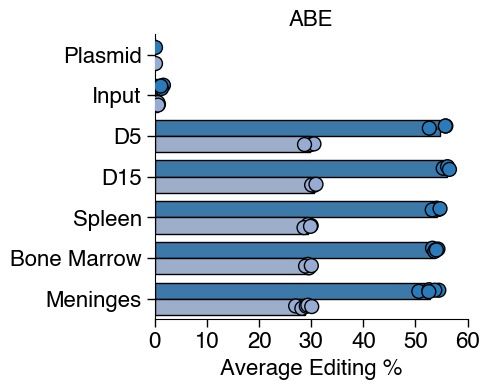

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


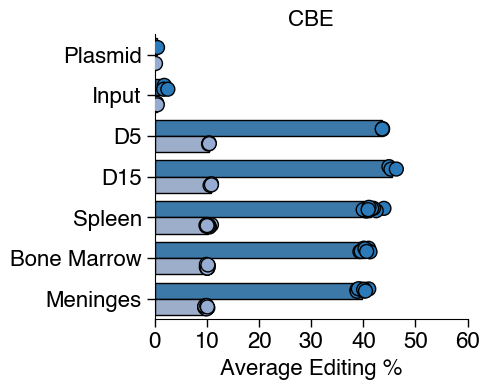

In [6]:
# ── OG screens — editing efficiency (all timepoints, figure 2e style) ─────
BASE_crispr = BASE + 'crispresso/'

ABE_og_files = os.listdir(BASE_crispr + 'og/ABE')
CBE_og_files = os.listdir(BASE_crispr + 'og/CBE')
ABE_og_files.remove('spleen_rep5_ABE.csv')  # near-zero reads, as in figure2.ipynb

name_dict_og = {
    'meninges': 'Meninges', 'spleen': 'Spleen', 'bonemarrow': 'Bone Marrow',
    'd5': 'D5', 'd15': 'D15', 'plasmidlib': 'Plasmid', 'input': 'Input',
}

ABE_og = dfs['ABE_OG'][dfs['ABE_OG']['classification'] == 'targeting guide'][['gRNA_id']]
CBE_og = dfs['CBE_OG'][dfs['CBE_OG']['classification'] == 'targeting guide'][['gRNA_id']]

t, corr, name = [], [], []
for f in ABE_og_files:
    g = pd.read_csv(BASE_crispr + f'og/ABE/{f}').rename(columns={'Guide_ID': 'gRNA_id'})
    g = pd.merge(g, ABE_og, on='gRNA_id')
    g = g[g['Reads_aligned_all_amplicons'] >= min_sensor_reads_og]
    t.append(np.average(g['target_base_edit_perc']))
    corr.append(np.average(g['corr_perc']))
    name.append(name_dict_og[f.split('_')[0]])

t2, corr2, name2 = [], [], []
for f in CBE_og_files:
    g = pd.read_csv(BASE_crispr + f'og/CBE/{f}').rename(columns={'Guide_ID': 'gRNA_id'})
    g = pd.merge(g, CBE_og, on='gRNA_id')
    g = g[g['Reads_aligned_all_amplicons'] >= min_sensor_reads_og]
    t2.append(np.average(g['target_base_edit_perc']))
    corr2.append(np.average(g['corr_perc']))
    name2.append(name_dict_og[f.split('_')[0]])

ABE_editing1 = pd.DataFrame({'Sample': name,  'Editing %': t,    'Edit Type': 'Target Editing (w/ Bystanders)'})
ABE_editing2 = pd.DataFrame({'Sample': name,  'Editing %': corr, 'Edit Type': 'Pure Correct Editing'})
ABE_og_editing = pd.concat((ABE_editing1, ABE_editing2))

CBE_editing1 = pd.DataFrame({'Sample': name2, 'Editing %': t2,    'Edit Type': 'Target Editing (w/ Bystanders)'})
CBE_editing2 = pd.DataFrame({'Sample': name2, 'Editing %': corr2, 'Edit Type': 'Pure Correct Editing'})
CBE_og_editing = pd.concat((CBE_editing1, CBE_editing2))

order_og = ['Plasmid', 'Input', 'D5', 'D15', 'Spleen', 'Bone Marrow', 'Meninges']

def _plot_editing_bar(data, title, order, palette, save_path):
    fig, ax = plt.subplots(1, 1, figsize=(5, 4))
    sns.barplot(data=data, y='Sample', x='Editing %', hue='Edit Type', ax=ax,
                edgecolor='black', linewidth=1, palette=palette, order=order)
    sns.stripplot(data=data, y='Sample', x='Editing %', hue='Edit Type', ax=ax,
                  edgecolor='black', linewidth=1, palette=palette, order=order, dodge=True, s=10,
                  hue_order=['Target Editing (w/ Bystanders)', 'Pure Correct Editing'])
    ax.set_ylabel('')
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60])
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)
    ax.set_title(title, fontsize=16)
    ax.set_xlabel('Average Editing %', fontsize=16)
    ax.legend([], [], frameon=False)
    fig.tight_layout()
    fig.savefig(save_path, bbox_inches='tight')
    plt.show()

_plot_editing_bar(ABE_og_editing, 'ABE', order_og, edit_palette, BASE + 'figures_final/2e_ABE.pdf')
_plot_editing_bar(CBE_og_editing, 'CBE', order_og, edit_palette, BASE + 'figures_final/2e_CBE.pdf')


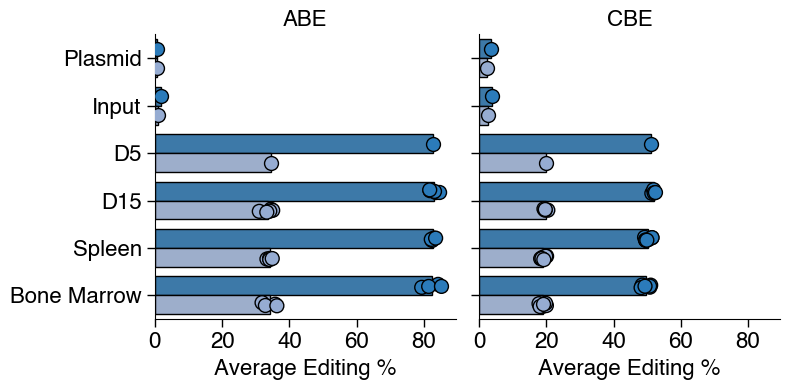

In [221]:
# ── Focused EPO screens — editing efficiency (all timepoints) ──────────────
# ABE EPO: bm2, spleen2 excluded.
# CBE EPO: bm2,bm5,bm8, spleen2,spleen5,spleen8, d15-rep2 excluded.

_abe_epo_name = {
    'bm1': 'Bone Marrow', 'bm3': 'Bone Marrow', 'bm4': 'Bone Marrow', 'bm5': 'Bone Marrow',
    'spleen1': 'Spleen', 'spleen3': 'Spleen', 'spleen4': 'Spleen', 'spleen5': 'Spleen',
    'd15-rep1': 'D15', 'd15-rep2': 'D15', 'd15-rep3': 'D15', 'd15-rep4': 'D15', 'd15-rep5': 'D15',
    'd5': 'D5', 'input': 'Input', 'lib': 'Plasmid',
}
_cbe_epo_name = {
    'bm1': 'Bone Marrow', 'bm3': 'Bone Marrow', 'bm4': 'Bone Marrow',
    'bm6': 'Bone Marrow', 'bm7': 'Bone Marrow', 'bm9': 'Bone Marrow', 'bm10': 'Bone Marrow',
    'spleen1': 'Spleen', 'spleen3': 'Spleen', 'spleen4': 'Spleen',
    'spleen6': 'Spleen', 'spleen7': 'Spleen', 'spleen9': 'Spleen', 'spleen10': 'Spleen',
    'd15-rep1': 'D15', 'd15-rep3': 'D15', 'd15-rep4': 'D15', 'd15-rep5': 'D15',
    'd5': 'D5', 'input': 'Input', 'lib': 'Plasmid',
}

ABE_epo_guides = dfs['ABE_EPO_T0'][dfs['ABE_EPO_T0']['classification'] == 'targeting guide'][['gRNA_id']]
CBE_epo_guides = dfs['CBE_EPO_T0'][dfs['CBE_EPO_T0']['classification'] == 'targeting guide'][['gRNA_id']]

t, corr, name = [], [], []
for stem, label in _abe_epo_name.items():
    fp = BASE_crispr + f'focused/ABE_EPO/{stem}_compact_unfiltered.csv'
    if not os.path.exists(fp): continue
    g = pd.read_csv(fp).rename(columns={'Guide_ID': 'gRNA_id'})
    g = pd.merge(g, ABE_epo_guides, on='gRNA_id')
    g = g[g['Reads_aligned_all_amplicons'] >= min_sensor_reads]
    t.append(np.average(g['target_base_edit_perc']))
    corr.append(np.average(g['corr_perc']))
    name.append(label)

t2, corr2, name2 = [], [], []
for stem, label in _cbe_epo_name.items():
    fp = BASE_crispr + f'focused/CBE_EPO_NEW/{stem}_compact_unfiltered.csv'
    if not os.path.exists(fp): continue
    g = pd.read_csv(fp).rename(columns={'Guide_ID': 'gRNA_id'})
    g = pd.merge(g, CBE_epo_guides, on='gRNA_id')
    g = g[g['Reads_aligned_all_amplicons'] >= min_sensor_reads]
    t2.append(np.average(g['target_base_edit_perc']))
    corr2.append(np.average(g['corr_perc']))
    name2.append(label)

ABE_editing1 = pd.DataFrame({'Sample': name,  'Editing %': t,    'Edit Type': 'Target Editing (w/ Bystanders)'})
ABE_editing2 = pd.DataFrame({'Sample': name,  'Editing %': corr, 'Edit Type': 'Pure Correct Editing'})
ABE_epo_editing = pd.concat((ABE_editing1, ABE_editing2))

CBE_editing1 = pd.DataFrame({'Sample': name2, 'Editing %': t2,    'Edit Type': 'Target Editing (w/ Bystanders)'})
CBE_editing2 = pd.DataFrame({'Sample': name2, 'Editing %': corr2, 'Edit Type': 'Pure Correct Editing'})
CBE_epo_editing = pd.concat((CBE_editing1, CBE_editing2))

order_fc = ['Plasmid', 'Input', 'D5', 'D15', 'Spleen', 'Bone Marrow']

fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True, sharex=True)
sns.barplot(data=ABE_epo_editing, y='Sample', x='Editing %', hue='Edit Type', ax=ax[0], edgecolor='black', linewidth=1, palette=edit_palette, order=order_fc)
sns.barplot(data=CBE_epo_editing, y='Sample', x='Editing %', hue='Edit Type', ax=ax[1], edgecolor='black', linewidth=1, palette=edit_palette, order=order_fc)
sns.stripplot(data=ABE_epo_editing, y='Sample', x='Editing %', hue='Edit Type', ax=ax[0], edgecolor='black', linewidth=1, palette=edit_palette, order=order_fc, dodge=True, s=10)
sns.stripplot(data=CBE_epo_editing, y='Sample', x='Editing %', hue='Edit Type', ax=ax[1], edgecolor='black', linewidth=1, palette=edit_palette, order=order_fc, dodge=True, s=10)
ax[0].set_ylabel(''); ax[1].set_ylabel('')
ax[0].set_xticks([0, 20, 40, 60, 80])
ax[0].spines[['top', 'right']].set_visible(False); ax[1].spines[['top', 'right']].set_visible(False)
ax[0].tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1); ax[1].tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)
ax[0].set_title('ABE', fontsize=16); ax[1].set_title('CBE', fontsize=16)
ax[0].set_xlabel('Average Editing %', fontsize=16); ax[1].set_xlabel('Average Editing %', fontsize=16)
ax[0].legend([], [], frameon=False); ax[1].legend([], [], frameon=False)
# fig.suptitle('Focused EPO screens — editing efficiency', fontsize=16, y=1.02)
fig.tight_layout()
plt.show()
# fig.savefig('figures/fig_epo_editing.pdf')

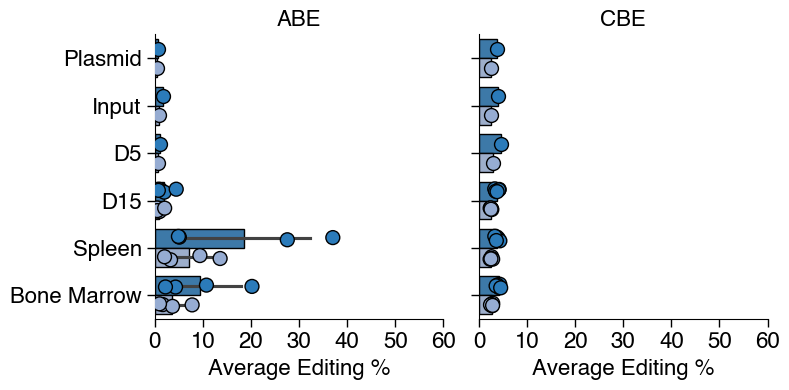

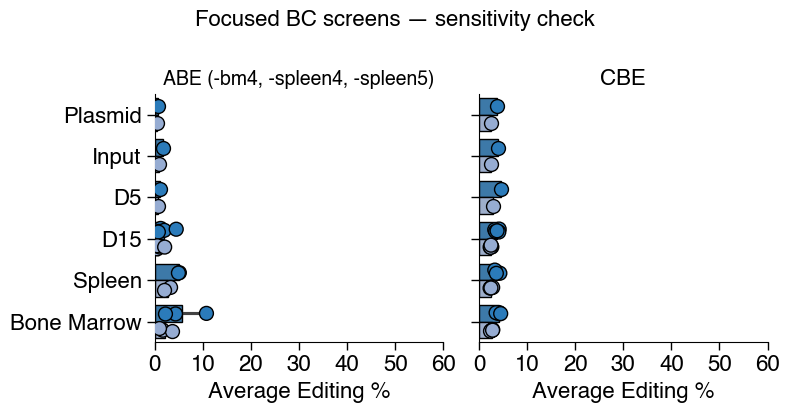

In [222]:
# ── Focused BC (null) screens — editing efficiency (all timepoints) ────────
# ABE BC: bm2, spleen2 excluded.
# CBE BC: bm1,bm2,bm6,bm8,bm10, spleen1,spleen2,spleen6,spleen8,spleen10 excluded.

_abe_bc_name = {
    'bm1': 'Bone Marrow', 'bm3': 'Bone Marrow', 'bm5': 'Bone Marrow',
    'spleen1': 'Spleen', 'spleen3': 'Spleen',
    'd15-rep1': 'D15', 'd15-rep2': 'D15', 'd15-rep3': 'D15', 'd15-rep4': 'D15', 'd15-rep5': 'D15',
    'd5': 'D5', 'input': 'Input', 'lib': 'Plasmid',
}
_cbe_bc_name = {
    'bm3': 'Bone Marrow', 'bm4': 'Bone Marrow', 'bm5': 'Bone Marrow',
    'bm7': 'Bone Marrow', 'bm9': 'Bone Marrow',
    'spleen3': 'Spleen', 'spleen4': 'Spleen', 'spleen5': 'Spleen',
    'spleen7': 'Spleen', 'spleen9': 'Spleen',
    'd15-rep1': 'D15', 'd15-rep2': 'D15', 'd15-rep3': 'D15', 'd15-rep4': 'D15', 'd15-rep5': 'D15',
    'd5': 'D5', 'input': 'Input', 'lib': 'Plasmid',
}

ABE_bc_guides = dfs['ABE_EPO_BC'][dfs['ABE_EPO_BC']['classification'] == 'targeting guide'][['gRNA_id']]
CBE_bc_guides = dfs['CBE_EPO_BC'][dfs['CBE_EPO_BC']['classification'] == 'targeting guide'][['gRNA_id']]

t, corr, name = [], [], []
for stem, label in _abe_bc_name.items():
    fp = BASE_crispr + f'focused/ABE_BC/{stem}_compact_unfiltered.csv'
    if not os.path.exists(fp): continue
    g = pd.read_csv(fp).rename(columns={'Guide_ID': 'gRNA_id'})
    g = pd.merge(g, ABE_bc_guides, on='gRNA_id')
    g = g[g['Reads_aligned_all_amplicons'] >= min_sensor_reads]
    t.append(np.average(g['target_base_edit_perc']))
    corr.append(np.average(g['corr_perc']))
    name.append(label)

t2, corr2, name2 = [], [], []
for stem, label in _cbe_bc_name.items():
    fp = BASE_crispr + f'focused/CBE_BC_NEW/{stem}_compact_unfiltered.csv'
    if not os.path.exists(fp): continue
    g = pd.read_csv(fp).rename(columns={'Guide_ID': 'gRNA_id'})
    g = pd.merge(g, CBE_bc_guides, on='gRNA_id')
    g = g[g['Reads_aligned_all_amplicons'] >= min_sensor_reads]
    t2.append(np.average(g['target_base_edit_perc']))
    corr2.append(np.average(g['corr_perc']))
    name2.append(label)

ABE_editing1 = pd.DataFrame({'Sample': name,  'Editing %': t,    'Edit Type': 'Target Editing (w/ Bystanders)'})
ABE_editing2 = pd.DataFrame({'Sample': name,  'Editing %': corr, 'Edit Type': 'Pure Correct Editing'})
ABE_bc_editing = pd.concat((ABE_editing1, ABE_editing2))

CBE_editing1 = pd.DataFrame({'Sample': name2, 'Editing %': t2,    'Edit Type': 'Target Editing (w/ Bystanders)'})
CBE_editing2 = pd.DataFrame({'Sample': name2, 'Editing %': corr2, 'Edit Type': 'Pure Correct Editing'})
CBE_bc_editing = pd.concat((CBE_editing1, CBE_editing2))

fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True, sharex=True)
sns.barplot(data=ABE_bc_editing, y='Sample', x='Editing %', hue='Edit Type', ax=ax[0], edgecolor='black', linewidth=1, palette=edit_palette, order=order_fc)
sns.barplot(data=CBE_bc_editing, y='Sample', x='Editing %', hue='Edit Type', ax=ax[1], edgecolor='black', linewidth=1, palette=edit_palette, order=order_fc)
sns.stripplot(data=ABE_bc_editing, y='Sample', x='Editing %', hue='Edit Type', ax=ax[0], edgecolor='black', linewidth=1, palette=edit_palette, order=order_fc, dodge=True, s=10)
sns.stripplot(data=CBE_bc_editing, y='Sample', x='Editing %', hue='Edit Type', ax=ax[1], edgecolor='black', linewidth=1, palette=edit_palette, order=order_fc, dodge=True, s=10)
ax[0].set_ylabel(''); ax[1].set_ylabel('')
ax[0].set_xticks([0, 10, 20, 30, 40, 50, 60])
ax[0].spines[['top', 'right']].set_visible(False); ax[1].spines[['top', 'right']].set_visible(False)
ax[0].tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1); ax[1].tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)
ax[0].set_title('ABE', fontsize=16); ax[1].set_title('CBE', fontsize=16)
ax[0].set_xlabel('Average Editing %', fontsize=16); ax[1].set_xlabel('Average Editing %', fontsize=16)
ax[0].legend([], [], frameon=False); ax[1].legend([], [], frameon=False)
# fig.suptitle('Focused BC screens — editing efficiency', fontsize=16, y=1.02)
fig.tight_layout()
plt.show()
# fig.savefig('figures/fig_bc_editing.pdf')


| Sample   | Target Edit % | Correct Edit % |
|----------|--------------|----------------|
| bm1      | 4.2%         | 1.6%           |
| bm3      | 10.7%        | 3.9%           |
| bm4      | 20.0%        | 7.6%           |
| bm5      | 2.1%         | 0.9%           |
| spleen1  | 5.0%         | 3.2%           |
| spleen3  | 4.9%         | 2.0%           |
| spleen4  | 37.2%        | 13.8%          |
| spleen5  | 27.7%        | 9.2%           |

# 2b. Editing Efficiency Distributions (All Timepoints)
Histograms of per-guide `target_base_edit_perc` and `corr_perc` at each timepoint.
Style matching figure 2f. Rows: target editing (top) / correct only (bottom). Columns: timepoints.

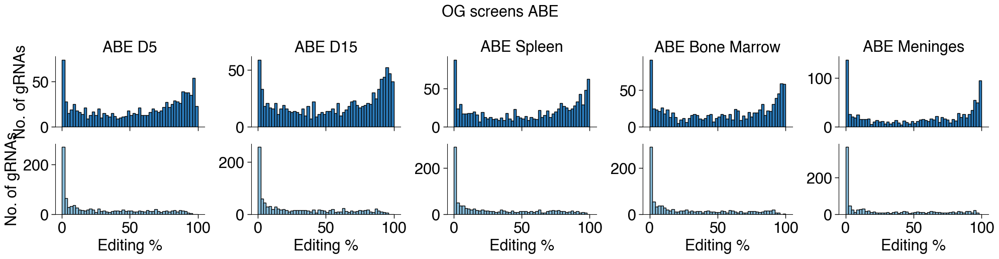

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


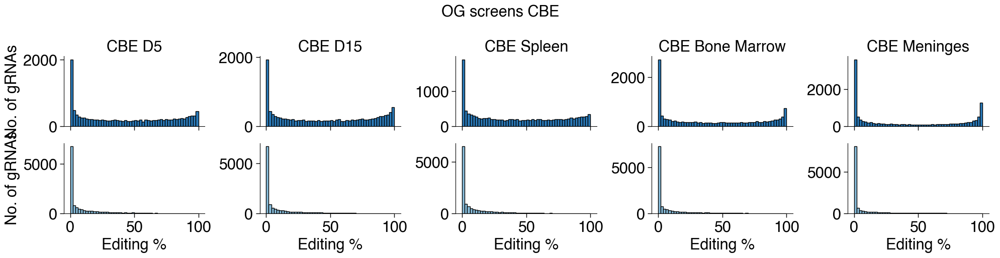

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


In [223]:
# ── OG screens — editing efficiency histograms (all timepoints, figure 2f style) ──
BASE_mle = BASE + 'MLE/'

og_tps = ['d5', 'd15', 'spleen', 'bm', 'men']
og_tp_labels = {'d5': 'D5', 'd15': 'D15', 'spleen': 'Spleen', 'bm': 'Bone Marrow', 'men': 'Meninges'}
og_abe_files = {'d5': 'og/ABE/d5_ABE_MLE.csv', 'd15': 'og/ABE/d15_ABE_MLE.csv',
                'spleen': 'og/ABE/spleen_ABE_MLE.csv', 'bm': 'og/ABE/bm_ABE_MLE.csv',
                'men': 'og/ABE/men_ABE_MLE.csv'}
og_cbe_files = {'d5': 'og/CBE/d5_CBE_MLE.csv', 'd15': 'og/CBE/d15_CBE_MLE.csv',
                'spleen': 'og/CBE/spleen_CBE_MLE.csv', 'bm': 'og/CBE/bm_CBE_MLE.csv',
                'men': 'og/CBE/men_CBE_MLE.csv'}

ABE_og_guides = dfs['ABE_OG'][dfs['ABE_OG']['classification'] == 'targeting guide'][['gRNA_id']]
CBE_og_guides = dfs['CBE_OG'][dfs['CBE_OG']['classification'] == 'targeting guide'][['gRNA_id']]

n = len(og_tps)
fig, ax = plt.subplots(2, n, figsize=(4*n, 5), sharex=True, sharey=False)

for k, tp in enumerate(og_tps):
    abe = pd.read_csv(BASE_mle + og_abe_files[tp]).rename(columns={'Guide_ID': 'gRNA_id'})
    abe = pd.merge(abe, ABE_og_guides, on='gRNA_id')
    cbe = pd.read_csv(BASE_mle + og_cbe_files[tp]).rename(columns={'Guide_ID': 'gRNA_id'})
    cbe = pd.merge(cbe, CBE_og_guides, on='gRNA_id')
    ax[0][k].hist(abe['target_base_edit_perc'], bins=np.linspace(0,100,51), linewidth=1, color=blues[4], edgecolor='black')
    ax[1][k].hist(abe['corr_perc'],             bins=np.linspace(0,100,51), linewidth=1, color=blues[2], edgecolor='black')
    ax[0][k].set_title(f'ABE {og_tp_labels[tp]}', fontsize=22)
    for row in [0, 1]:
        ax[row][k].spines[['top', 'right']].set_visible(False)
        ax[row][k].tick_params(axis='both', which='major', labelsize=22, direction='out', length=6, width=1)

ax[0][0].set_ylabel('No. of gRNAs', fontsize=22)
ax[1][0].set_ylabel('No. of gRNAs', fontsize=22)
for k in range(n):
    ax[1][k].set_xlabel('Editing %', fontsize=22)
fig.suptitle('OG screens ABE', fontsize=22, y=1.02)
fig.tight_layout()
plt.show()
fig.savefig('figures_final/fig_og_hist.pdf')

fig, ax = plt.subplots(2, n, figsize=(4*n, 5), sharex=True, sharey=False)

for k, tp in enumerate(og_tps):
    cbe = pd.read_csv(BASE_mle + og_cbe_files[tp]).rename(columns={'Guide_ID': 'gRNA_id'})
    cbe = pd.merge(cbe, CBE_og_guides, on='gRNA_id')
    ax[0][k].hist(cbe['target_base_edit_perc'], bins=np.linspace(0,100,51), linewidth=1, color=blues[4], edgecolor='black')
    ax[1][k].hist(cbe['corr_perc'],             bins=np.linspace(0,100,51), linewidth=1, color=blues[2], edgecolor='black')
    ax[0][k].set_title(f'CBE {og_tp_labels[tp]}', fontsize=22)
    for row in [0, 1]:
        ax[row][k].spines[['top', 'right']].set_visible(False)
        ax[row][k].tick_params(axis='both', which='major', labelsize=22, direction='out', length=6, width=1)

ax[0][0].set_ylabel('No. of gRNAs', fontsize=22)
ax[1][0].set_ylabel('No. of gRNAs', fontsize=22)
for k in range(n):
    ax[1][k].set_xlabel('Editing %', fontsize=22)
fig.suptitle('OG screens CBE', fontsize=22, y=1.02)
fig.tight_layout()
plt.show()
fig.savefig('figures_final/fig_og_cbe_hist.pdf')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


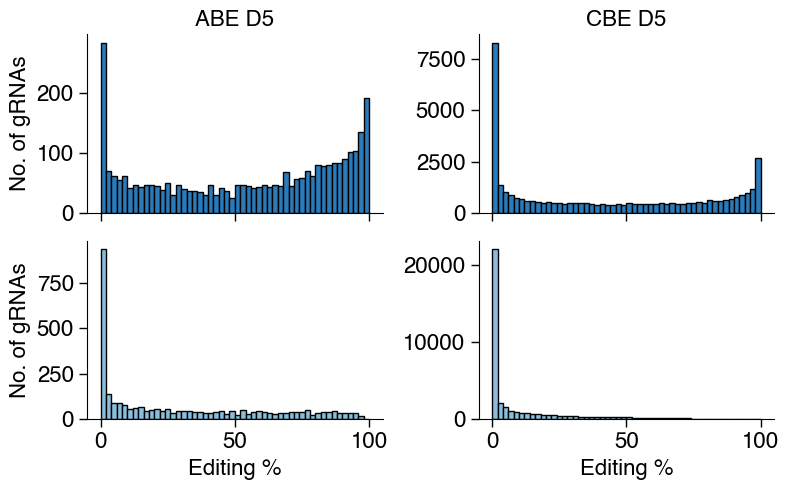

In [ ]:
import glob as _glob

# ── D5 editing efficiency histograms (ABE vs CBE) ──────────────────────────
_abe_d5_files = sorted(_glob.glob(BASE_crispr + 'og/ABE/d5_*_ABE.csv'))
_cbe_d5_files = sorted(_glob.glob(BASE_crispr + 'og/CBE/d5_*_CBE.csv'))

_abe_d5 = pd.concat([pd.read_csv(f).rename(columns={'Guide_ID': 'gRNA_id'}) for f in _abe_d5_files], ignore_index=True)
_cbe_d5 = pd.concat([pd.read_csv(f).rename(columns={'Guide_ID': 'gRNA_id'}) for f in _cbe_d5_files], ignore_index=True)

ABE_og_guides = dfs['ABE_OG'][dfs['ABE_OG']['classification'] == 'targeting guide'][['gRNA_id']]
CBE_og_guides = dfs['CBE_OG'][dfs['CBE_OG']['classification'] == 'targeting guide'][['gRNA_id']]

ABE_edits = pd.merge(_abe_d5, ABE_og_guides, on='gRNA_id')
CBE_edits = pd.merge(_cbe_d5, CBE_og_guides, on='gRNA_id')

fig, ax = plt.subplots(2, 2, figsize=(8, 5), sharex=True, sharey=False)

ax[0][0].hist(ABE_edits['target_base_edit_perc'], bins=np.linspace(0,100,51), linewidth=1, color=blues[4], edgecolor='black')
ax[1][0].hist(ABE_edits['corr_perc'],             bins=np.linspace(0,100,51), linewidth=1, color=blues[2], edgecolor='black')
ax[0][1].hist(CBE_edits['target_base_edit_perc'], bins=np.linspace(0,100,51), linewidth=1, color=blues[4], edgecolor='black')
ax[1][1].hist(CBE_edits['corr_perc'],             bins=np.linspace(0,100,51), linewidth=1, color=blues[2], edgecolor='black')

for row in [0, 1]:
    for col in [0, 1]:
        ax[row][col].spines[['top', 'right']].set_visible(False)
        ax[row][col].tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)

ax[0][0].set_ylabel('No. of gRNAs', fontsize=16)
ax[1][0].set_ylabel('No. of gRNAs', fontsize=16)
ax[1][0].set_xlabel('Editing %', fontsize=16)
ax[1][1].set_xlabel('Editing %', fontsize=16)
ax[0][0].set_title('ABE D5', fontsize=16)
ax[0][1].set_title('CBE D5', fontsize=16)

fig.tight_layout()
fig.savefig('figures_final/fig2f.pdf')

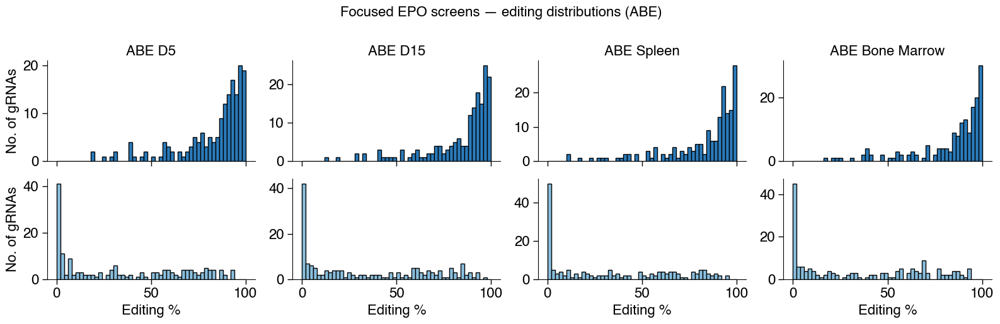

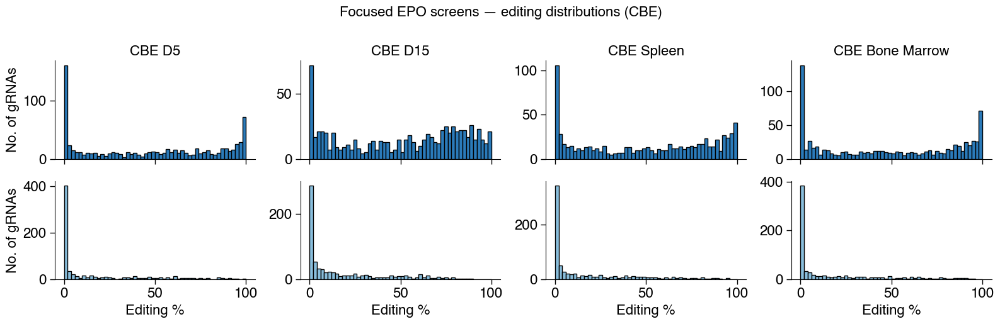

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


In [227]:
# ── Focused EPO screens — editing efficiency histograms ────────────────────
fc_tps     = ['d5', 'd15', 'spleen', 'bm']
fc_tp_labels = {'d5': 'D5', 'd15': 'D15', 'spleen': 'Spleen', 'bm': 'Bone Marrow'}

ABE_epo_guides2 = dfs['ABE_EPO_T0'][dfs['ABE_EPO_T0']['classification'] == 'targeting guide'][['gRNA_id']]
CBE_epo_guides2 = dfs['CBE_EPO_T0'][dfs['CBE_EPO_T0']['classification'] == 'targeting guide'][['gRNA_id']]

n = len(fc_tps)
for editor, guides, screen_dir in [('ABE', ABE_epo_guides2, 'focused/ABE_EPO'),
                                    ('CBE', CBE_epo_guides2, 'focused/CBE_EPO_NEW')]:
    fig, ax = plt.subplots(2, n, figsize=(4*n, 5), sharex=True, sharey=False)
    for k, tp in enumerate(fc_tps):
        df = pd.read_csv(BASE_mle + f'{screen_dir}/{tp}.csv').rename(columns={'Guide_ID': 'gRNA_id'})
        df = pd.merge(df, guides, on='gRNA_id')
        ax[0][k].hist(df['target_base_edit_perc'], bins=np.linspace(0,100,51), linewidth=1, color=blues[4], edgecolor='black')
        ax[1][k].hist(df['corr_perc'],             bins=np.linspace(0,100,51), linewidth=1, color=blues[2], edgecolor='black')
        ax[0][k].set_title(f'{editor} {fc_tp_labels[tp]}', fontsize=16)
        for row in [0, 1]:
            ax[row][k].spines[['top', 'right']].set_visible(False)
            ax[row][k].tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)
    ax[0][0].set_ylabel('No. of gRNAs', fontsize=16)
    ax[1][0].set_ylabel('No. of gRNAs', fontsize=16)
    for k in range(n):
        ax[1][k].set_xlabel('Editing %', fontsize=16)
    fig.suptitle(f'Focused EPO screens — editing distributions ({editor})', fontsize=16, y=1.02)
    fig.tight_layout()
    plt.show()
fig.savefig('figures_final/fig_epo_hist.pdf')

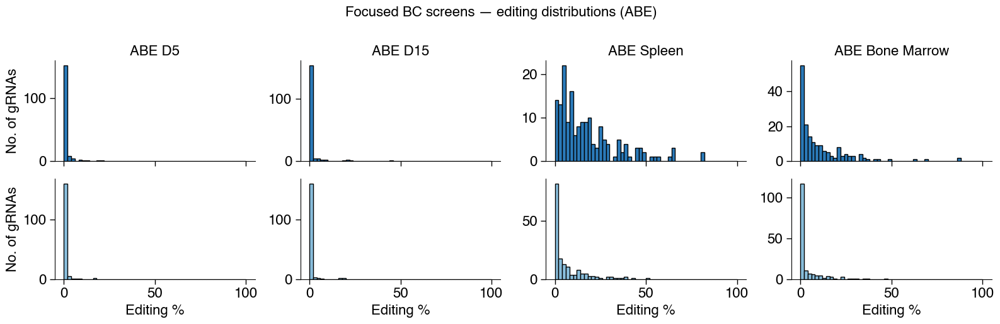

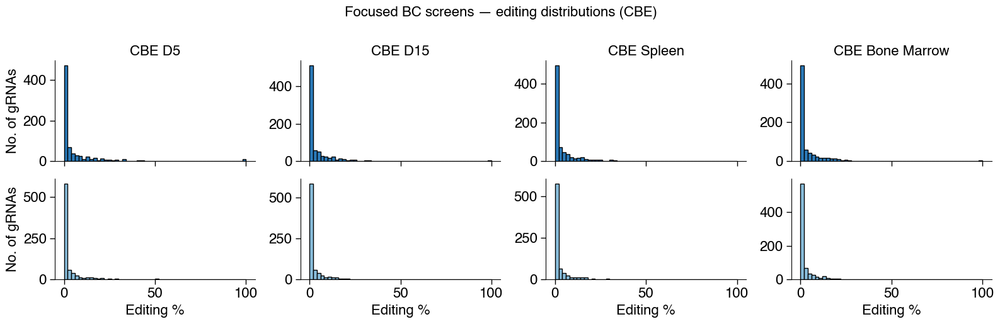

In [105]:
# ── Focused BC screens — editing efficiency histograms ─────────────────────
ABE_bc_guides2 = dfs['ABE_EPO_BC'][dfs['ABE_EPO_BC']['classification'] == 'targeting guide'][['gRNA_id']]
CBE_bc_guides2 = dfs['CBE_EPO_BC'][dfs['CBE_EPO_BC']['classification'] == 'targeting guide'][['gRNA_id']]

for editor, guides, screen_dir in [('ABE', ABE_bc_guides2, 'focused/ABE_BC'),
                                    ('CBE', CBE_bc_guides2, 'focused/CBE_BC_NEW')]:
    fig, ax = plt.subplots(2, n, figsize=(4*n, 5), sharex=True, sharey=False)
    for k, tp in enumerate(fc_tps):
        df = pd.read_csv(BASE_mle + f'{screen_dir}/{tp}.csv').rename(columns={'Guide_ID': 'gRNA_id'})
        df = pd.merge(df, guides, on='gRNA_id')
        ax[0][k].hist(df['target_base_edit_perc'], bins=np.linspace(0,100,51), linewidth=1, color=blues[4], edgecolor='black')
        ax[1][k].hist(df['corr_perc'],             bins=np.linspace(0,100,51), linewidth=1, color=blues[2], edgecolor='black')
        ax[0][k].set_title(f'{editor} {fc_tp_labels[tp]}', fontsize=16)
        for row in [0, 1]:
            ax[row][k].spines[['top', 'right']].set_visible(False)
            ax[row][k].tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)
    ax[0][0].set_ylabel('No. of gRNAs', fontsize=16)
    ax[1][0].set_ylabel('No. of gRNAs', fontsize=16)
    for k in range(n):
        ax[1][k].set_xlabel('Editing %', fontsize=16)
    fig.suptitle(f'Focused BC screens — editing distributions ({editor})', fontsize=16, y=1.02)
    fig.tight_layout()
    plt.show()
# fig.savefig('figures/fig_bc_hist.pdf')


# 3. Effect size comparison: median vs mean vs concordant mean

Scatter plots showing how much the three estimates diverge.
Ambiguous guides (concordant_mean = NaN, i.e. <2/3 replicates agree on direction) shown in orange.
Targeting guides only.

In [86]:
def plot_effect_size_comparison(df, screen_name, conditions):
    n = len(conditions)
    fig, axes = plt.subplots(2, n, figsize=(4*n, 8))
    if n == 1:
        axes = axes.reshape(2, 1)

    targ = df[df['classification'] == 'targeting guide'].copy()

    for k, cond in enumerate(conditions):
        med = f'LFC_median_{cond}'
        avg = f'LFC_avg_{cond}'
        con = f'LFC_concordant_mean_{cond}'
        if med not in targ.columns:
            continue
        lim = targ[med].abs().quantile(0.99) * 1.1

        # Row 0: median vs mean
        ax = axes[0][k]
        ax.scatter(targ[med], targ[avg], s=5, alpha=0.25, color='tab:blue')
        ax.plot([-lim,lim], [-lim,lim], 'k--', linewidth=0.8)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        _xy = targ[[med, avg]].dropna()
        rp = _xy.corr().iloc[0,1]
        rs, _ = scipy.stats.spearmanr(_xy.iloc[:,0], _xy.iloc[:,1])
        ax.set_title(f'{screen_name} {cond}\n$r_p$={rp:.3f}, $r_s$={rs:.3f}', fontsize=16)
        ax.set_xlabel('Median LFC', fontsize=16); ax.set_ylabel('Mean LFC', fontsize=16)
        ax.spines[['top','right']].set_visible(False)
        ax.tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)

        # Row 1: median vs concordant mean
        ax2 = axes[1][k]
        if con in targ.columns:
            ambig = targ[con].isna()
            ax2.scatter(targ.loc[~ambig, med], targ.loc[~ambig, con],
                        s=5, alpha=0.25, color='tab:blue', label=f'concordant (n={(-ambig).sum()})')
            ax2.scatter(targ.loc[ambig, med], targ.loc[ambig, med]*0,
                        s=5, alpha=0.3, color='orange', label=f'ambiguous (n={ambig.sum()})', marker='x')
            _xy2 = targ.loc[~ambig, [med, con]].dropna()
            rp2 = _xy2.corr().iloc[0,1]
            rs2, _ = scipy.stats.spearmanr(_xy2.iloc[:,0], _xy2.iloc[:,1])
            ax2.plot([-lim,lim], [-lim,lim], 'k--', linewidth=0.8)
            ax2.set_title(f'$r_p$={rp2:.3f}, $r_s$={rs2:.3f}', fontsize=16)
            ax2.legend(frameon=False, fontsize=12)
        ax2.set_xlim(-lim, lim); ax2.set_ylim(-lim, lim)
        ax2.set_xlabel('Median LFC', fontsize=16); ax2.set_ylabel('Concordant mean LFC', fontsize=16)
        ax2.spines[['top','right']].set_visible(False)
        ax2.tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)

    fig.tight_layout()
    return fig

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


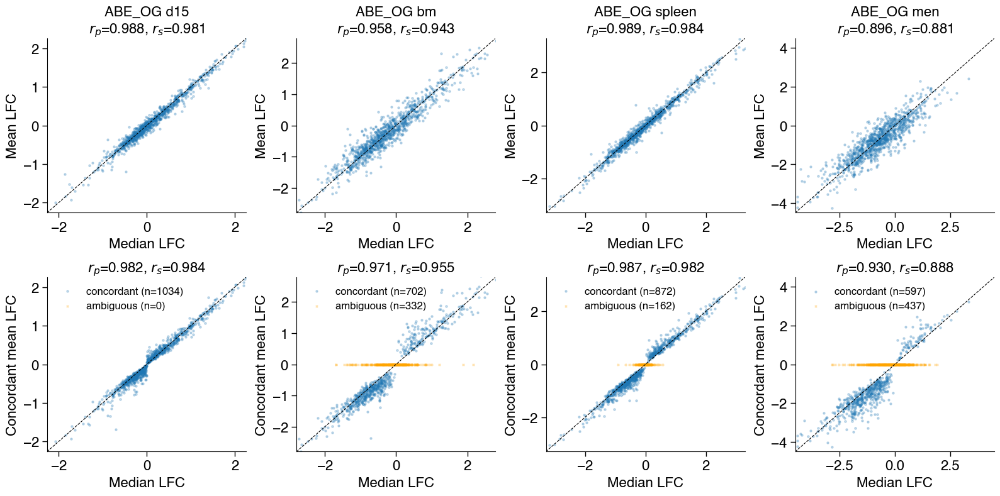

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


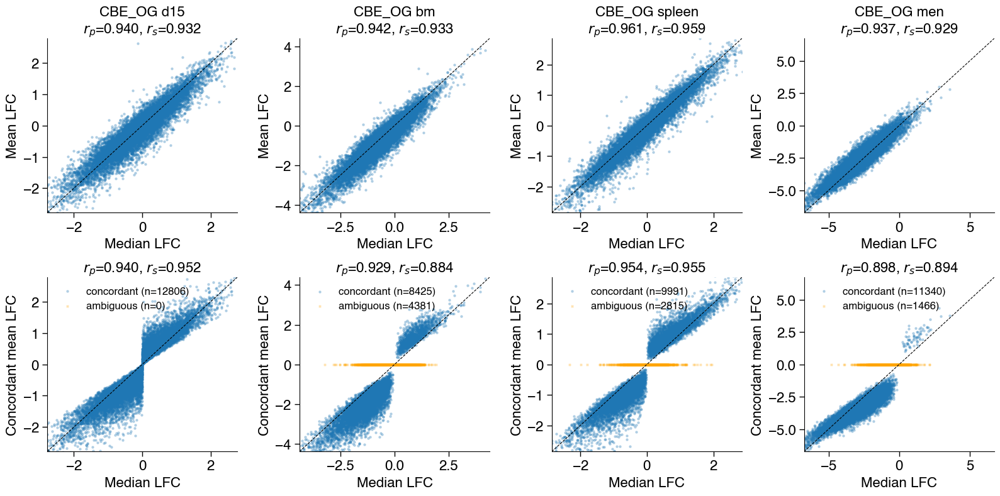

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


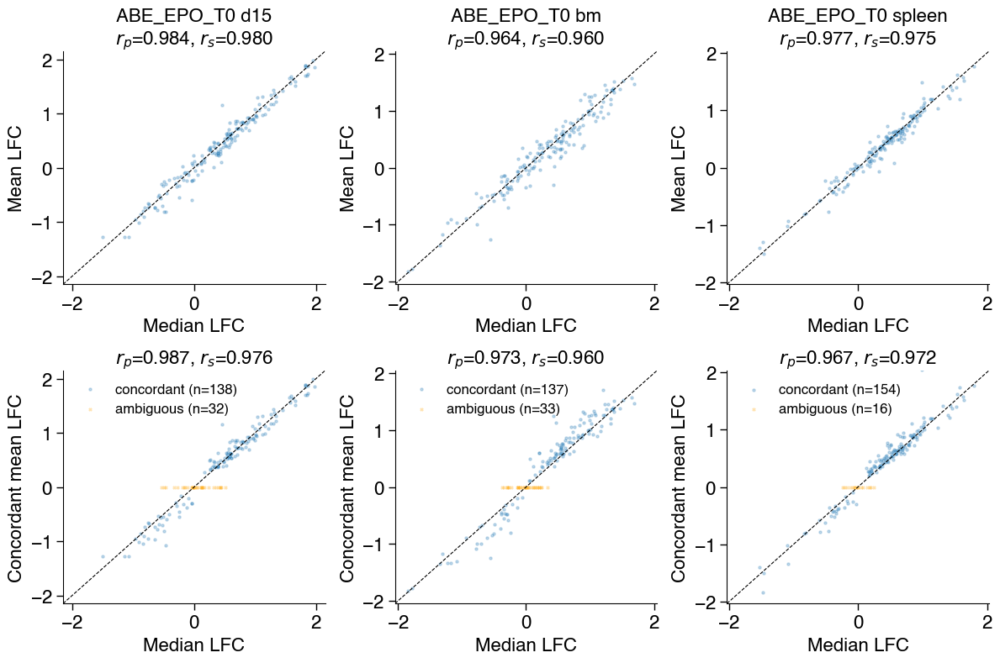

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


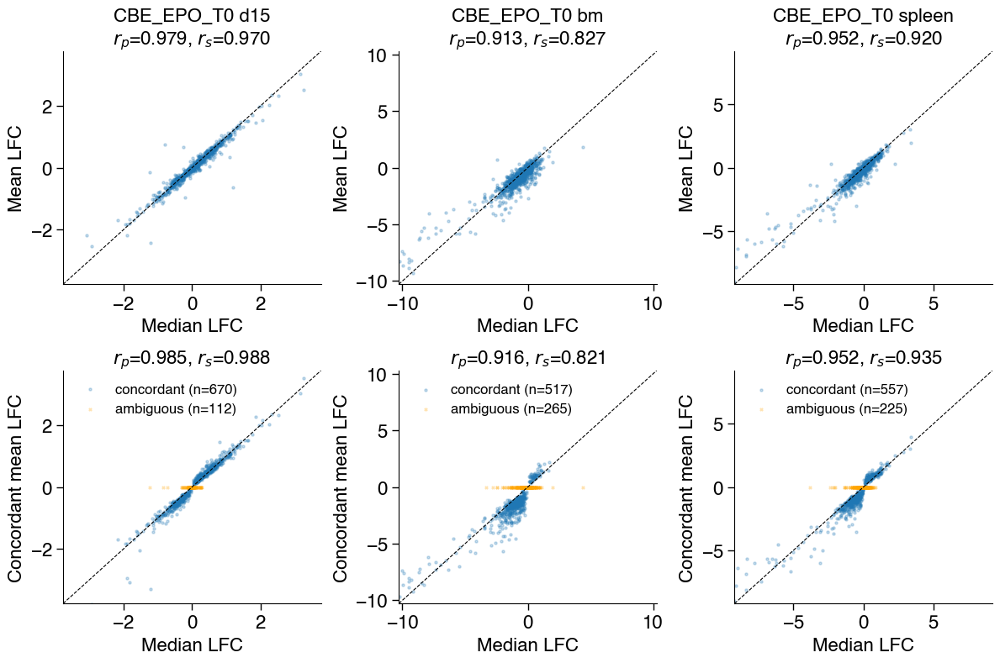

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


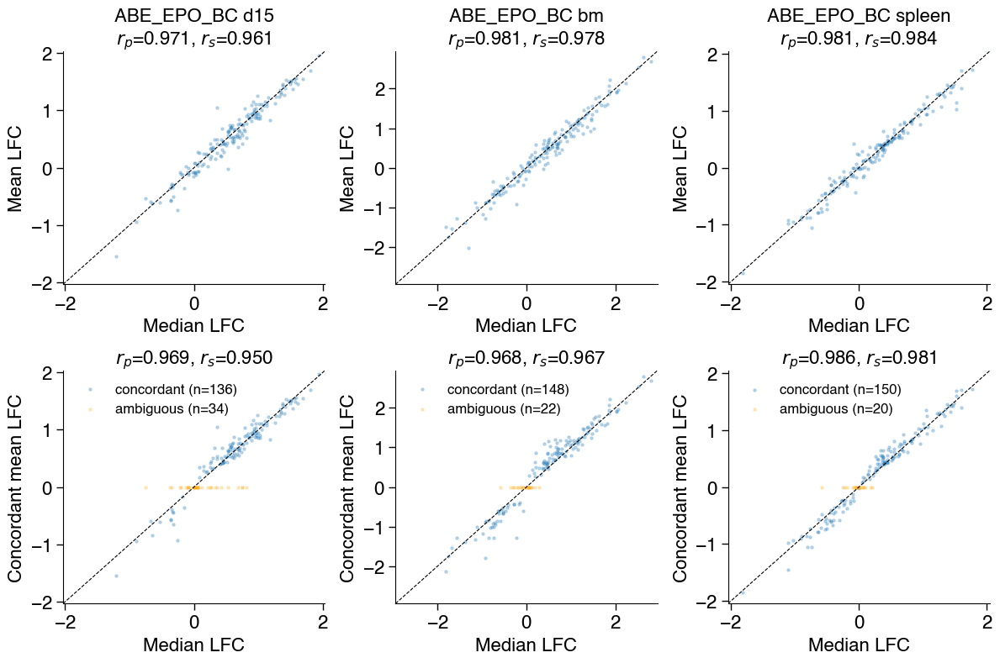

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


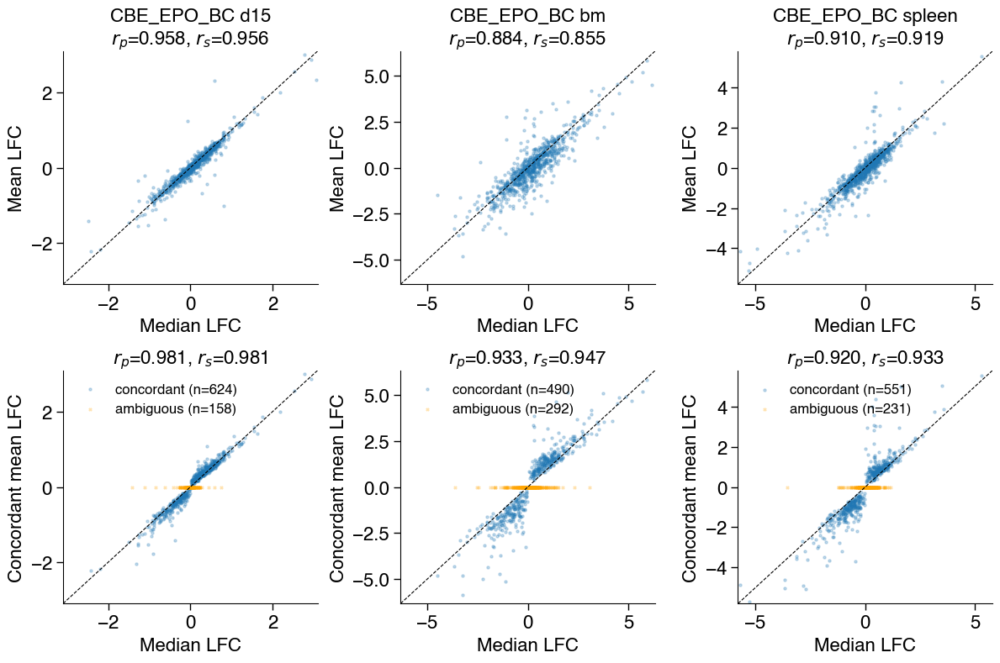

In [88]:
import os as _os
_os.makedirs(BASE + 'figures_final', exist_ok=True)

for screen, conds in [('ABE_OG', conds_og), ('CBE_OG', conds_og),
                       ('ABE_EPO_T0', conds_focused), ('CBE_EPO_T0', conds_focused),
                       ('ABE_EPO_BC', conds_focused), ('CBE_EPO_BC', conds_focused),
]:
    if dfs.get(screen) is None: continue
    fig = plot_effect_size_comparison(dfs[screen], screen, conds)
    fig.savefig(BASE + f'figures_final/effect_size_comparison_{screen}.pdf', bbox_inches='tight')
    plt.show()


# 4. Rank plots (waterfall)

Rank guides by LFC, colored by FDR significance tier and COSMIC role.
Sweep:
- 3 effect sizes: `median`, `avg`, `concordant_mean`
- 2 FDR methods: `fishers`, `stouffers`
- Editing cutoffs: 0%, 10%, 20% (focused screens only — OG uses T0 editing data)

In [114]:
def rank_plot(df, screen_name, conditions,
              effect='median', fdr_method='fishers',
              lfc_cutoff=1.0, is_og=False):
    # Filters: sensor_reads_{cond} >= min_sensor, target_base_edit_perc_{cond} >= 20,
    #          Input_median >= 2  (applied per-condition, matching Analysis_4)
    min_sensor  = 10 if is_og else 100
    edit_cutoff = 20

    FDR_cutoffs = [1e-1, 1e-2, 1e-3, 1e-4]
    size_dict   = {1e-1:15, 1e-2:50, 1e-3:100, 1e-4:180}
    label_dict  = {1e-1:r'FDR < $10^{-1}$', 1e-2:r'FDR < $10^{-2}$',
                   1e-3:r'FDR < $10^{-3}$', 1e-4:r'FDR < $10^{-4}$'}

    base_targ = df[df['classification'] == 'targeting guide'].copy()
    input_ok  = base_targ['Input_median'] >= 2 if 'Input_median' in base_targ.columns else pd.Series(True, index=base_targ.index)

    n = len(conditions)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 8), sharey=True)
    if n == 1: axes = [axes]

    for k, cond in enumerate(conditions):
        lfc_col   = f'LFC_{effect}_{cond}'
        fdr_col   = f'FDR_{cond}_{fdr_method}'
        reads_col = f'sensor_reads_{cond}'
        edit_col  = f'target_base_edit_perc_{cond}'
        if lfc_col not in base_targ.columns or fdr_col not in base_targ.columns:
            continue

        if reads_col in base_targ.columns and edit_col in base_targ.columns:
            guide_ok = input_ok & (base_targ[reads_col] >= min_sensor) & (base_targ[edit_col] >= edit_cutoff)
        else:
            guide_ok = input_ok
        targ = base_targ[guide_ok]

        cc = targ.dropna(subset=[lfc_col]).sort_values(lfc_col, ascending=False).reset_index(drop=True)
        cc['Rank'] = range(1, len(cc)+1)
        ax = axes[k]

        ns = cc[cc[fdr_col] >= FDR_cutoffs[0]]
        ax.scatter(ns['Rank'], ns[lfc_col], color=ns['color'], s=2, alpha=0.07)

        for id1, cut in enumerate(FDR_cutoffs):
            if id1 < len(FDR_cutoffs)-1:
                sig = cc[(cc[fdr_col] < cut) & (cc[fdr_col] >= FDR_cutoffs[id1+1])]
            else:
                sig = cc[cc[fdr_col] < cut]
            ax.scatter(sig['Rank'], sig[lfc_col], color=sig['color'],
                       s=size_dict[cut], label=label_dict[cut],
                       edgecolors='black', linewidths=0.3)

        label_col2 = 'HGVSp_m' if 'HGVSp_m' in cc.columns else 'gRNA_id'
        gene_col   = 'gene_name_m_corrected' if 'gene_name_m_corrected' in cc.columns else 'Gene'
        texts = []
        for _, row in pd.concat([cc.head(10), cc.tail(10)]).iterrows():
            if row[fdr_col] < FDR_cutoffs[0] and abs(row[lfc_col]) > lfc_cutoff:
                t = ax.text(row['Rank'], row[lfc_col],
                            f"{row[gene_col]} {row[label_col2]}", fontsize=16.5)
                t.set_path_effects([PathEffects.withStroke(linewidth=1.5, foreground='white')])
                texts.append(t)
        adjust_text(texts, ax=ax)

        ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','men':'Meninges','d15':'D15','d5':'D5'}.get(cond, cond)
        ax.set_title(cond_label, fontsize=16)
        ax.set_xlabel('gRNA Rank', fontsize=16)
        ax.spines[['top','right']].set_visible(False)
        ax.tick_params(labelsize=16, direction='out', length=6, width=1)
        if k == 0:
            ax.set_ylabel(f'{effect.replace("_"," ").title()} LFC', fontsize=16)
            ax.legend(frameon=False, fontsize=12, loc='lower right')

    min_s_label = f'sensor>={min_sensor}, edit>=20%, input>=2'
    fig.suptitle(f'{screen_name}  |  {effect}  |  {fdr_method}  |  {min_s_label}', fontsize=16, y=1.01)
    fig.tight_layout()
    plt.show()


NameError: name 'PathEffects' is not defined

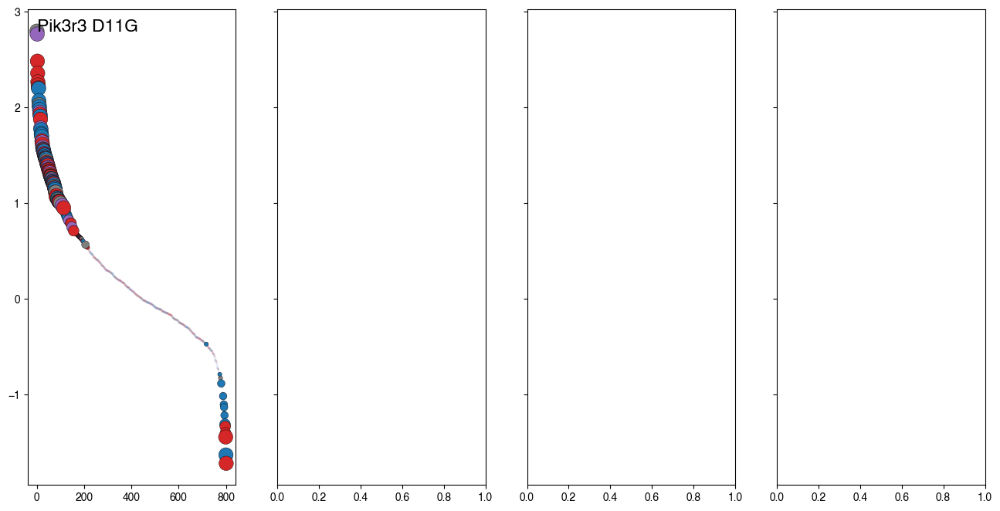

In [115]:
# OG screens
for screen, conds in [('ABE_OG', conds_og), ('CBE_OG', conds_og)]:
    for effect in ['median', 'avg', 'concordant_mean']:
        for fdr_m in ['fishers', 'stouffers']:
            rank_plot(dfs[screen], screen, conds, effect=effect, fdr_method=fdr_m, is_og=True)


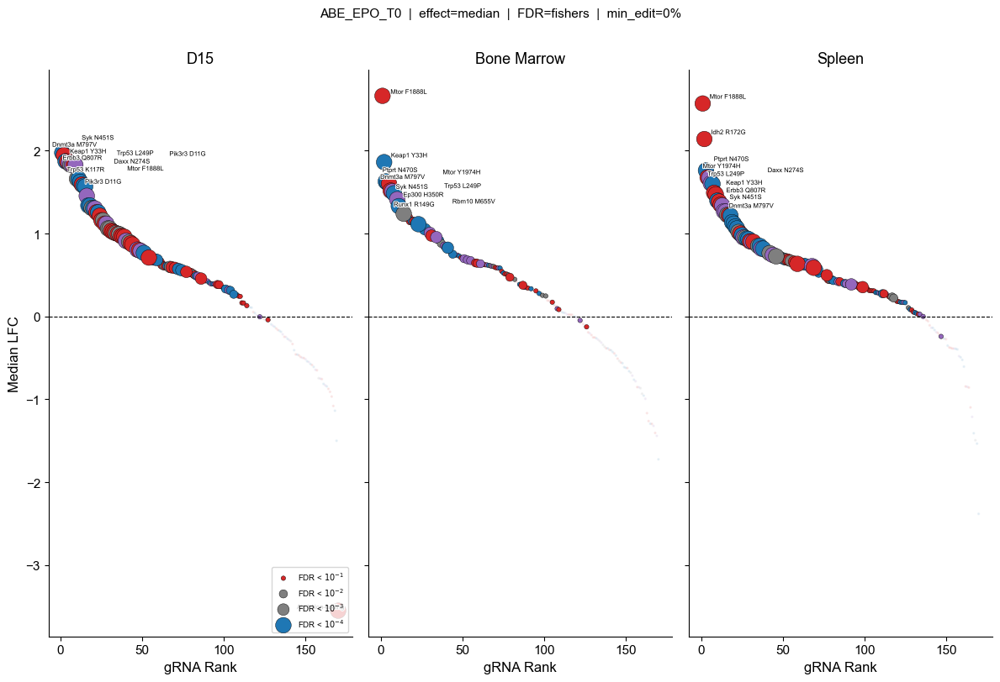

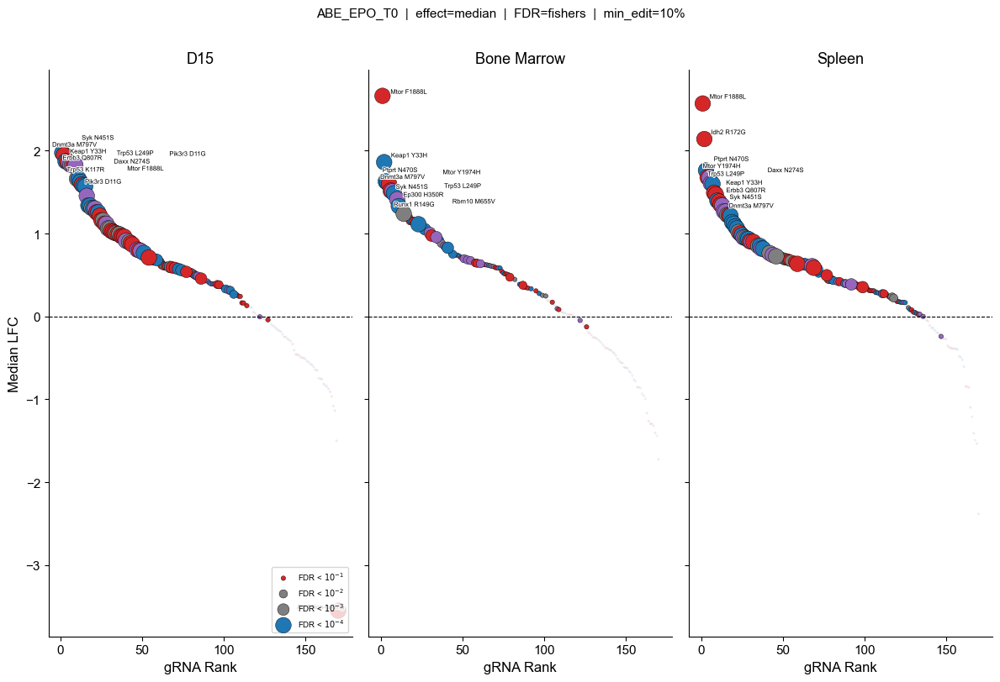

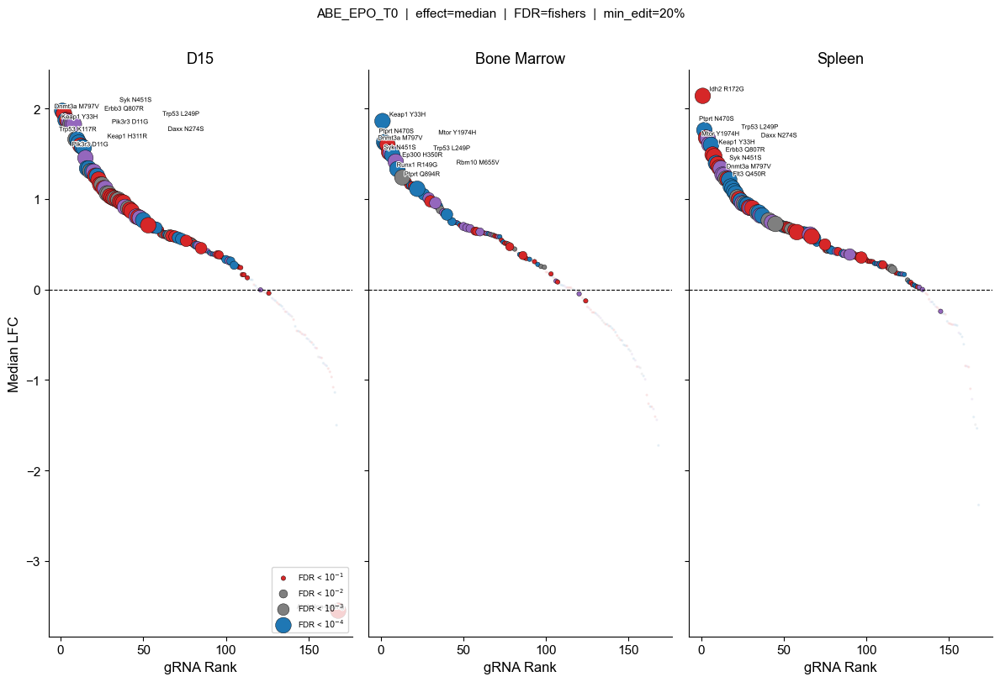

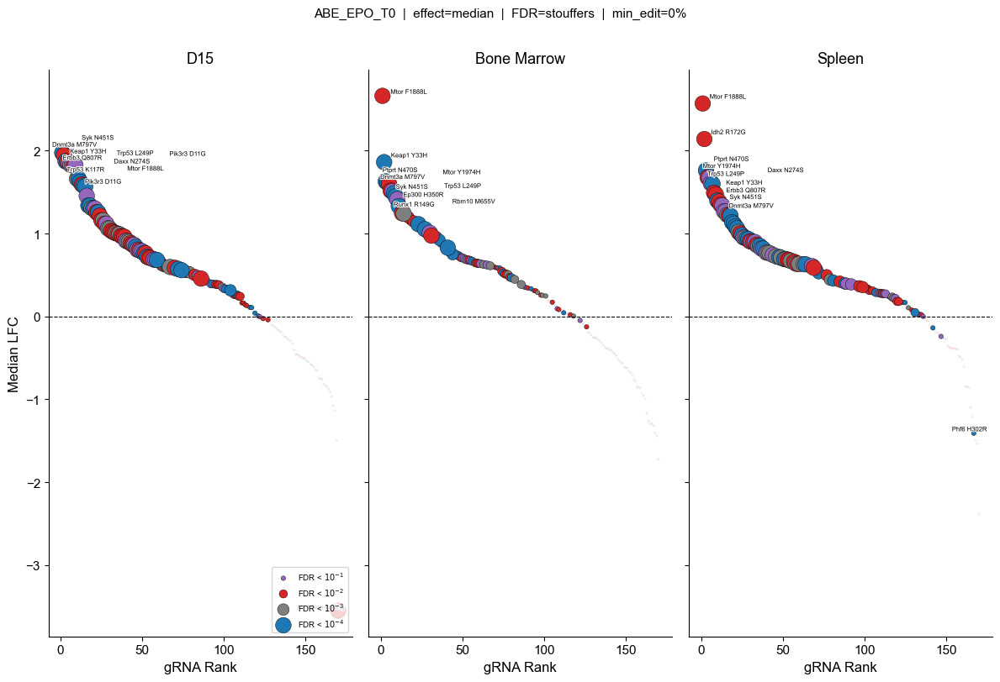

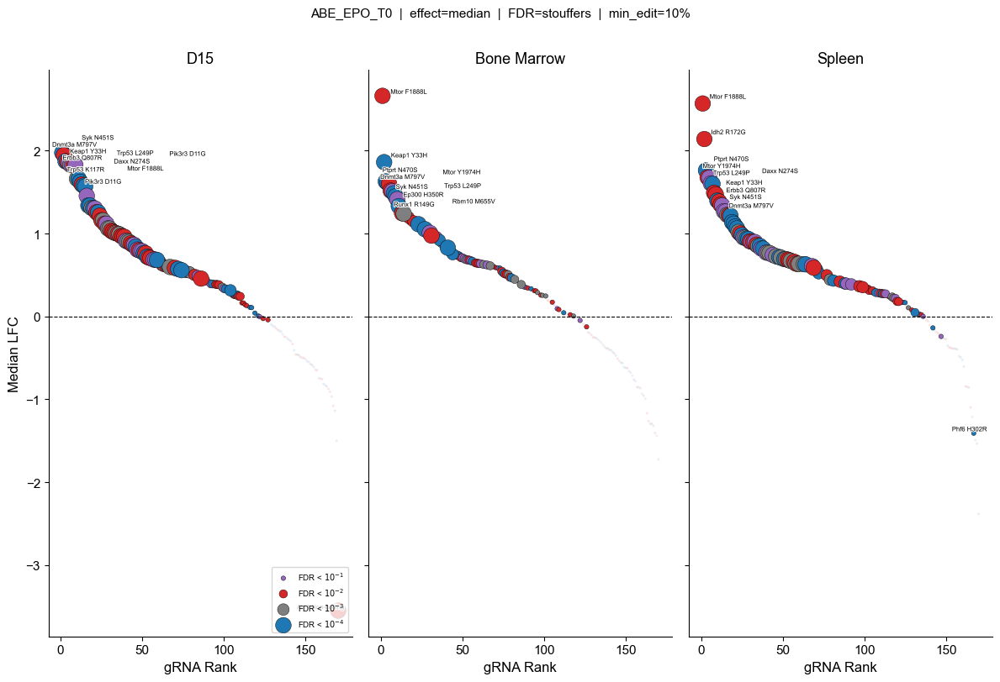

...

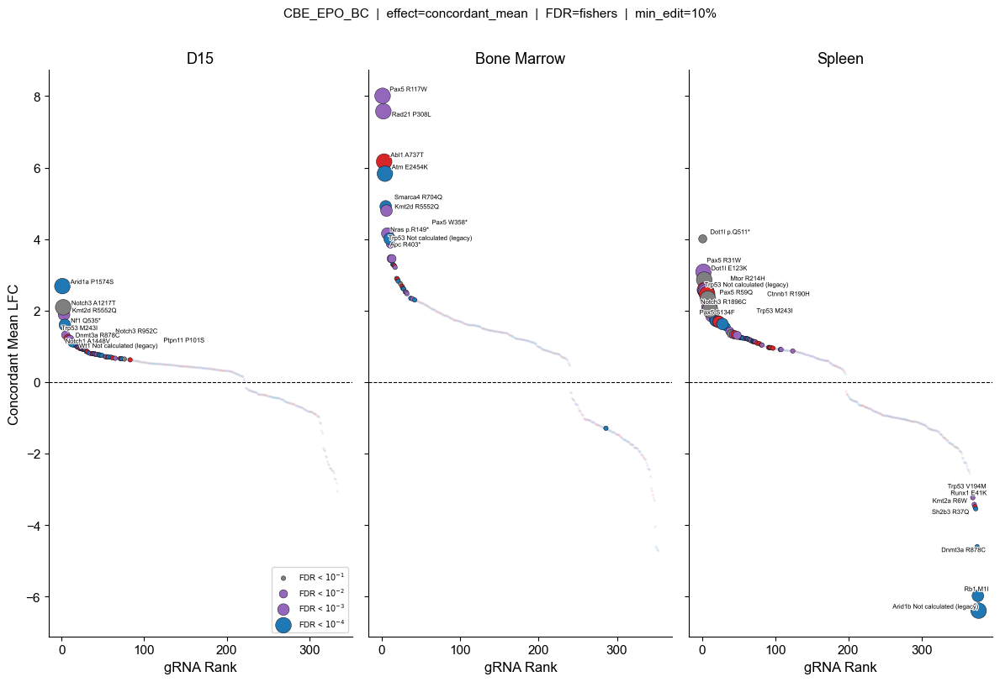

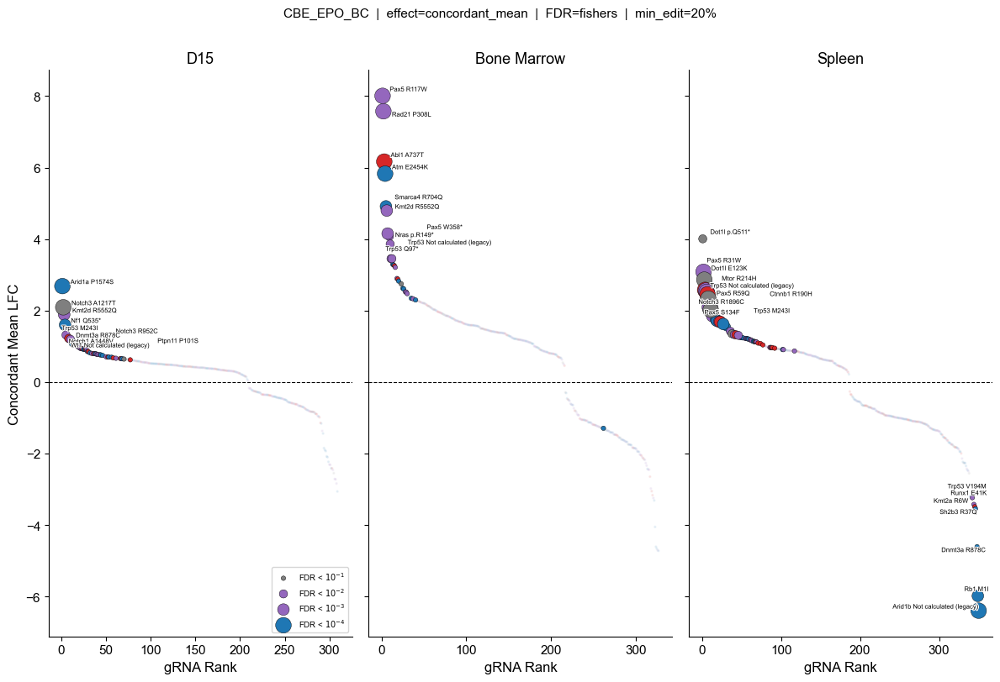

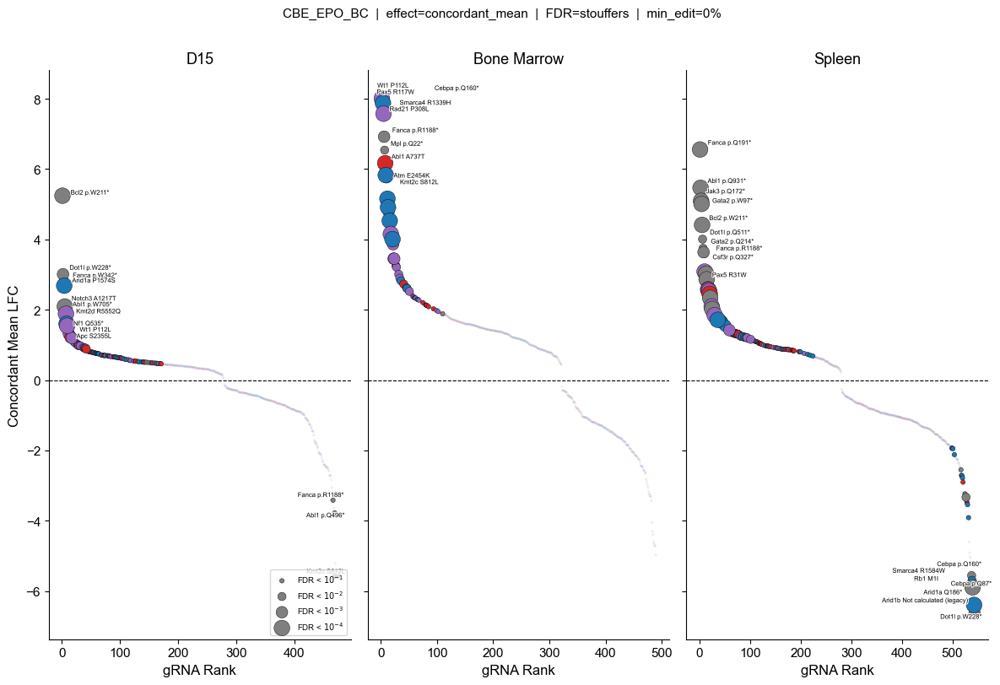

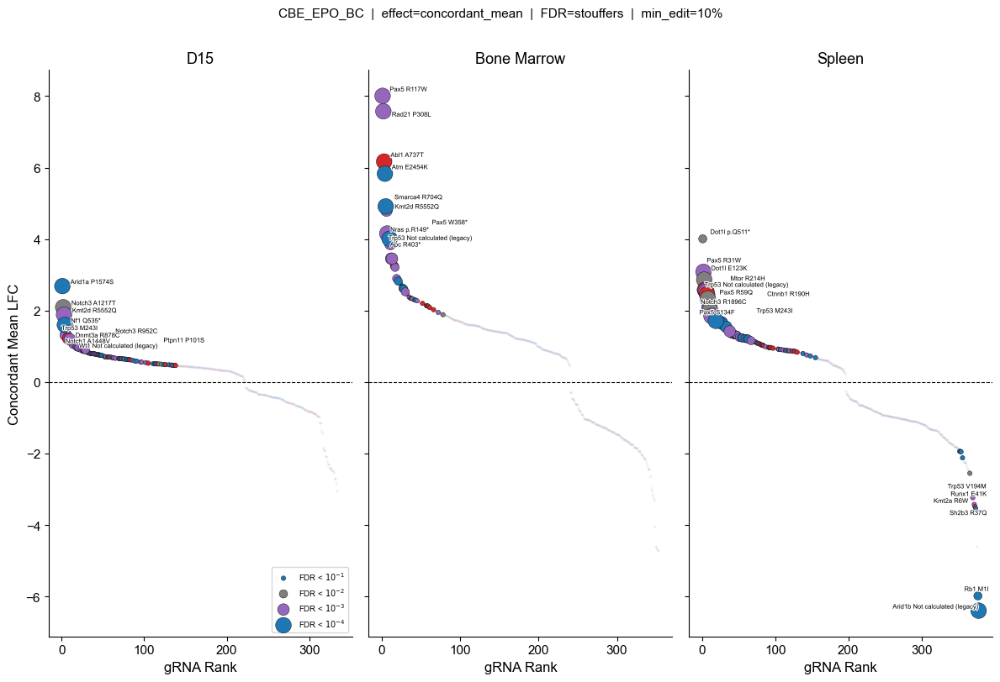

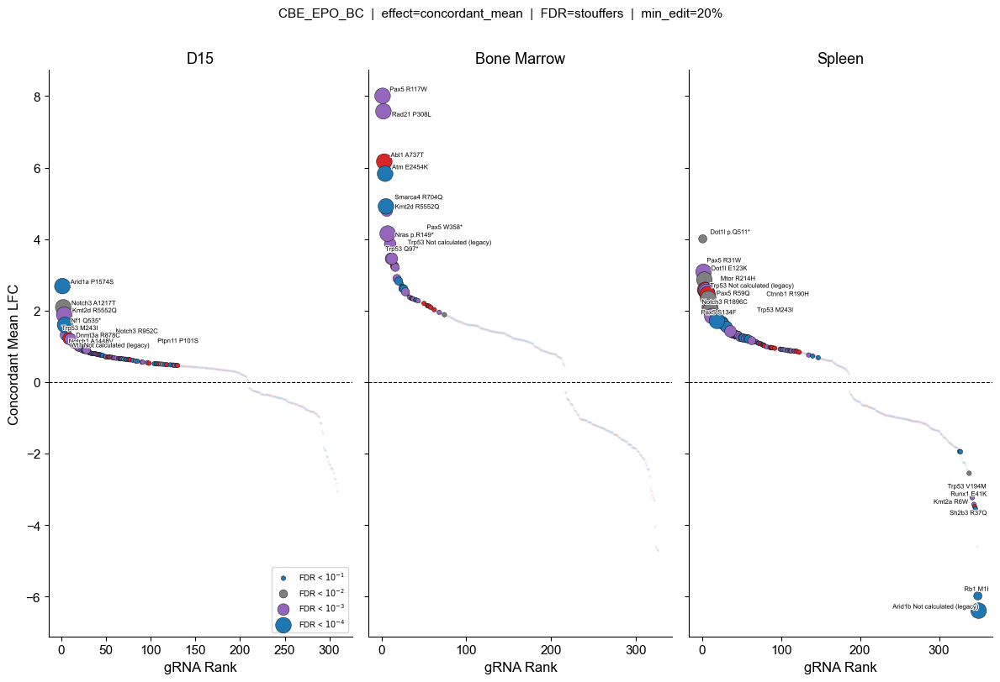

In [ ]:
# Focused EPO screens
for screen, conds in [('ABE_EPO_T0', conds_focused), ('CBE_EPO_T0', conds_focused),
                       ('ABE_EPO_BC', conds_focused), ('CBE_EPO_BC', conds_focused),
]:
    if dfs.get(screen) is None: continue
    for effect in ['median', 'avg', 'concordant_mean']:
        for fdr_m in ['fishers', 'stouffers']:
            rank_plot(dfs[screen], screen, conds, effect=effect, fdr_method=fdr_m, is_og=False)


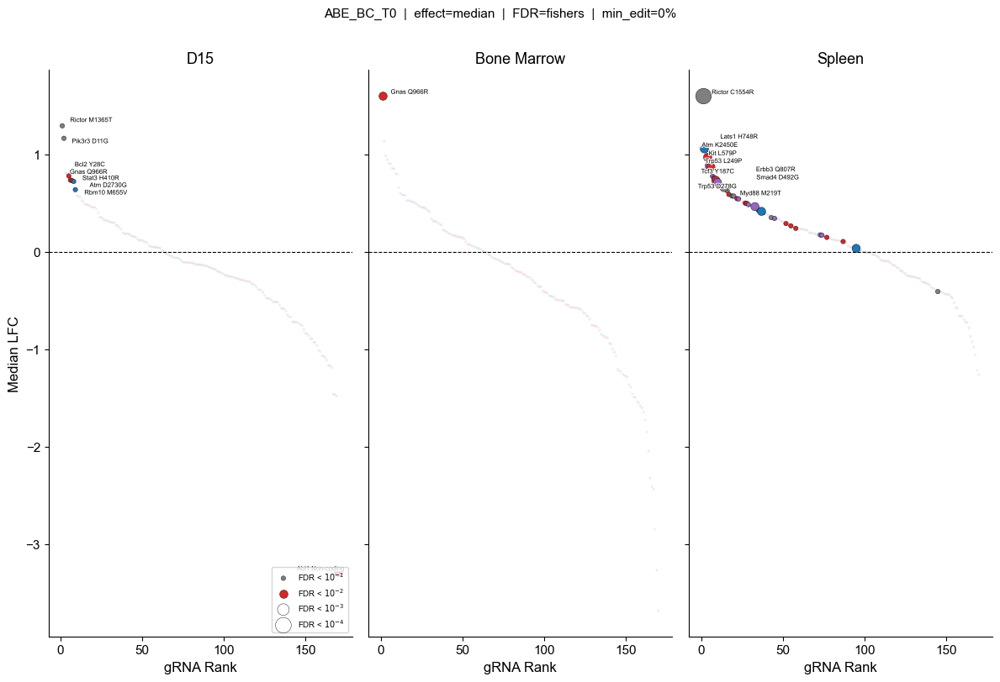

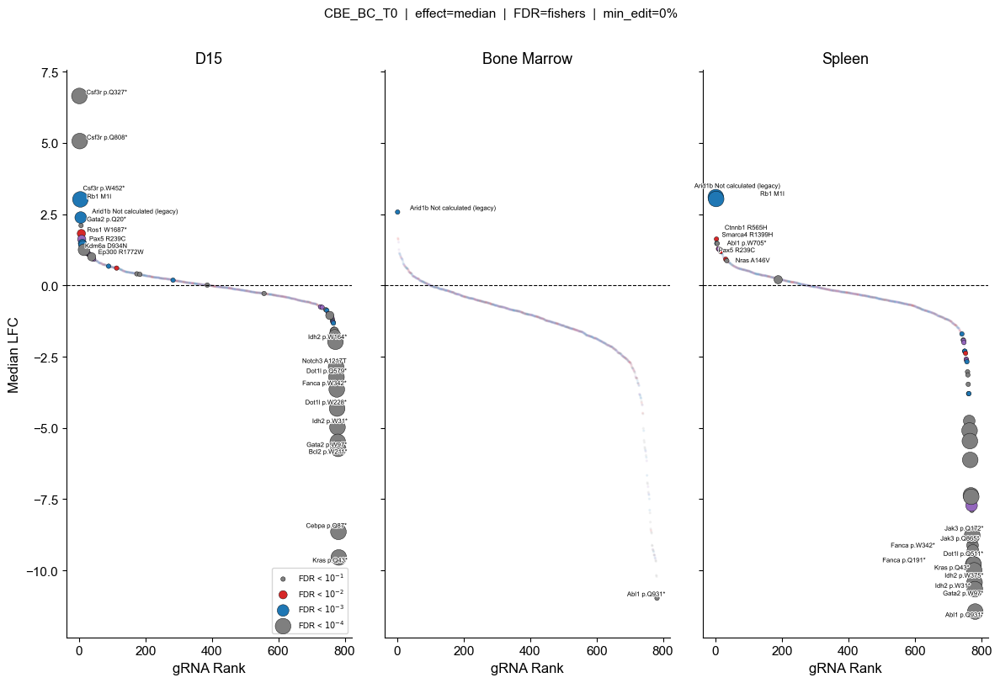

In [ ]:
# BC_T0 null — should be flat
for screen in ['ABE_BC_T0', 'CBE_BC_T0']:
    if dfs.get(screen) is None: continue
    rank_plot(dfs[screen], screen, conds_focused, effect='median', fdr_method='fishers')
# ── Save figure ──────────────────────────────────────────────────────────
# panel = ''  # e.g. '2f'
# fig.savefig(f'figures/{panel}.pdf', bbox_inches='tight')


# 5. Volcano plots

LFC (x) vs -log10(FDR) (y).
Targeting guides colored by FDR gradient (blue, darker = more significant); neutral controls in red; truncation controls in yellow.
Run across all screens × 3 effect sizes × 2 FDR methods.

In [6]:
def volcano_plot(df, screen_name, conditions,
                 effect='median', fdr_method='fishers',
                 fdr_cutoff=0.1, lfc_cutoff=1.0,
                 is_og=False):
    # Filters per Analysis_4 thresholds (applied to targeting guides AND truncation guides):
    #   OG screens:      sensor_reads_{cond} >= 10,  target_base_edit_perc_{cond} >= 20, Input_median >= 2
    #   Focused screens: sensor_reads_{cond} >= 100, target_base_edit_perc_{cond} >= 20, Input_median >= 2
    # Neutral controls (NTC, safe-targeting): no editing filter
    min_sensor  = 10 if is_og else 100
    edit_cutoff = 20

    n = len(conditions)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1: axes = [axes]

    _cmap = plt.cm.Blues

    input_ok = df['Input_median'] >= 2 if 'Input_median' in df.columns else pd.Series(True, index=df.index)

    for k, cond in enumerate(conditions):
        lfc_col   = f'LFC_{effect}_{cond}'
        fdr_col   = f'FDR_{cond}_{fdr_method}'
        reads_col = f'sensor_reads_{cond}'
        edit_col  = f'target_base_edit_perc_{cond}'
        if lfc_col not in df.columns or fdr_col not in df.columns:
            continue
        ax = axes[k]

        if reads_col in df.columns and edit_col in df.columns:
            guide_ok = input_ok & (df[reads_col] >= min_sensor) & (df[edit_col] >= edit_cutoff)
        else:
            guide_ok = input_ok

        targ  = df[(df['classification'] == 'targeting guide') & guide_ok].copy()
        trunc = df[(df['classification'] == 'essential truncation guide') & guide_ok].copy()
        ntc   = df[df['classification'] == 'non-targeting control'].copy()
        stc   = df[df['classification'] == 'safe-targeting control'].copy()

        # Targeting guides — blue FDR gradient
        if len(targ):
            neg_log_fdr = -np.log10(targ[fdr_col].clip(lower=1e-300))
            vmax = max(neg_log_fdr.max(), -np.log10(fdr_cutoff) * 2)
            norm = plt.Normalize(vmin=0, vmax=vmax)
            colors_targ = _cmap(norm(neg_log_fdr))
            ax.scatter(targ[lfc_col], neg_log_fdr,
                       c=colors_targ, s=20, alpha=0.6,
                       linewidths=0, edgecolors='none')

        # Neutral controls — red (no editing filter)
        for ctrl in [ntc, stc]:
            if len(ctrl):
                yvals = -np.log10(ctrl[fdr_col].clip(lower=1e-300))
                ax.scatter(ctrl[lfc_col], yvals,
                           c='#e41a1c', s=30, alpha=0.7,
                           linewidths=0, edgecolors='none', zorder=3)

        # Truncation controls — yellow (same editing filter as targeting guides)
        if len(trunc):
            yvals = -np.log10(trunc[fdr_col].clip(lower=1e-300))
            ax.scatter(trunc[lfc_col], yvals,
                       c='#ffcc00', s=30, alpha=0.8,
                       linewidths=0, edgecolors='none', zorder=3)

        ax.axhline(-np.log10(fdr_cutoff), color='black', linestyle='--', linewidth=0.8)
        ax.axvline( lfc_cutoff, color='grey', linestyle=':', linewidth=0.8)
        ax.axvline(-lfc_cutoff, color='grey', linestyle=':', linewidth=0.8)
        n_hits = int(((targ[fdr_col] < fdr_cutoff) & (targ[lfc_col].abs() > lfc_cutoff)).sum()) if len(targ) else 0
        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','men':'Meninges','d15':'D15'}.get(cond, cond)
        ax.set_title(f'{cond_label}  (n={n_hits} hits)', fontsize=16)
        ax.set_xlabel(f'{effect.replace("_"," ").title()} LFC', fontsize=16)
        ax.spines[['top','right']].set_visible(False)
        ax.tick_params(labelsize=16, direction='out', length=6, width=1)
        if k == 0:
            ax.set_ylabel(f'-log10(FDR {fdr_method})', fontsize=16)

    min_s_label = f'sensor>={min_sensor}, edit>={edit_cutoff}%, input>=2'
    fig.suptitle(f'{screen_name}  |  {effect}  |  {fdr_method}  |  {min_s_label}', fontsize=16, y=1.01)
    fig.tight_layout()
    plt.show()


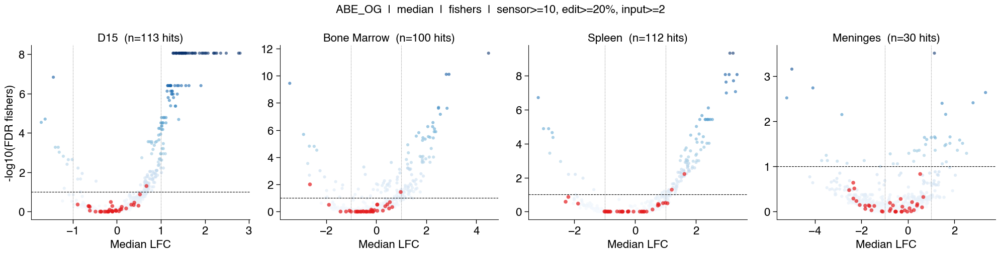

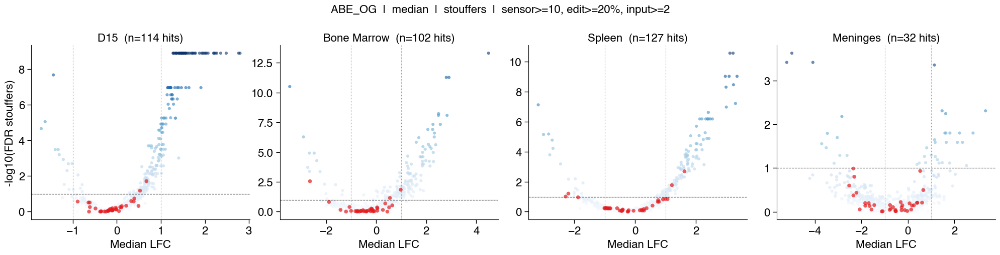

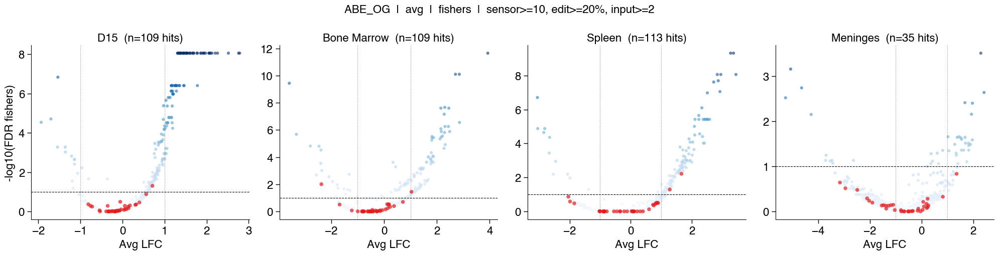

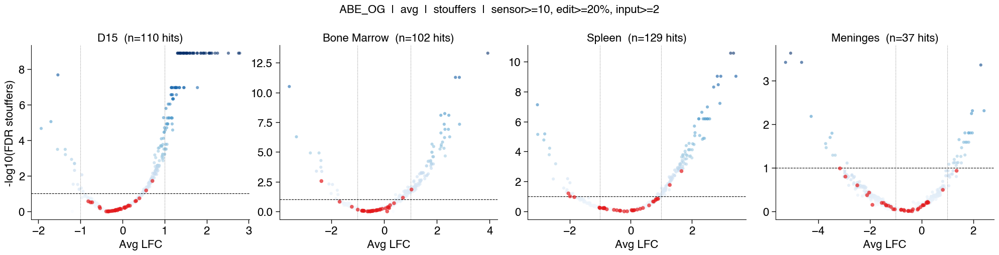

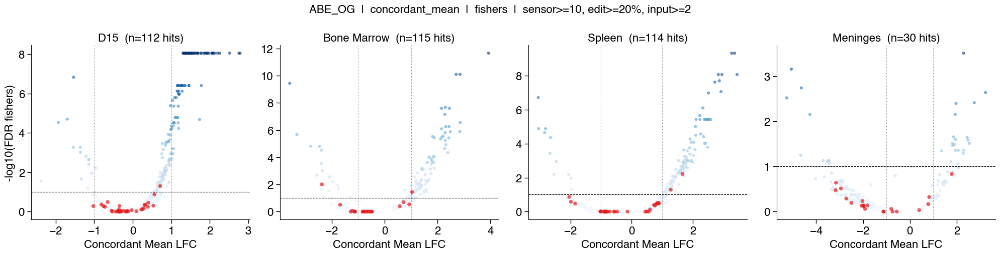

...

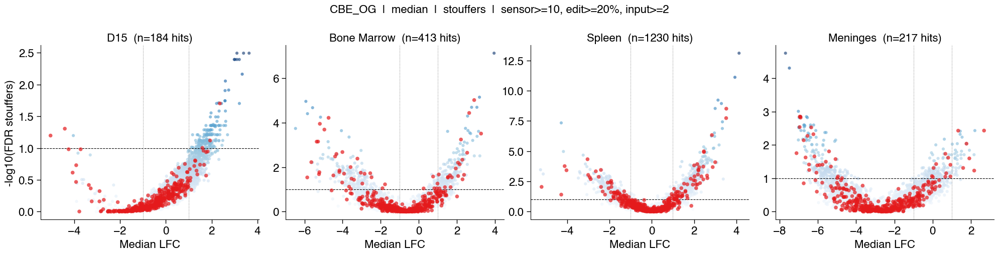

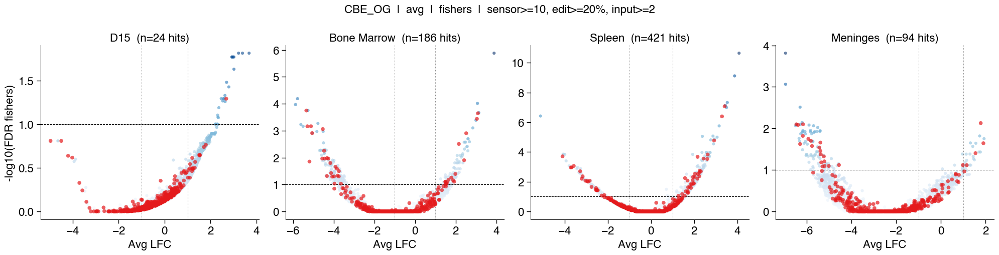

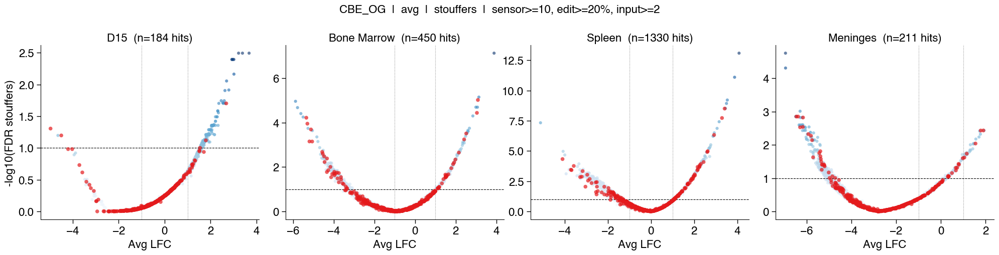

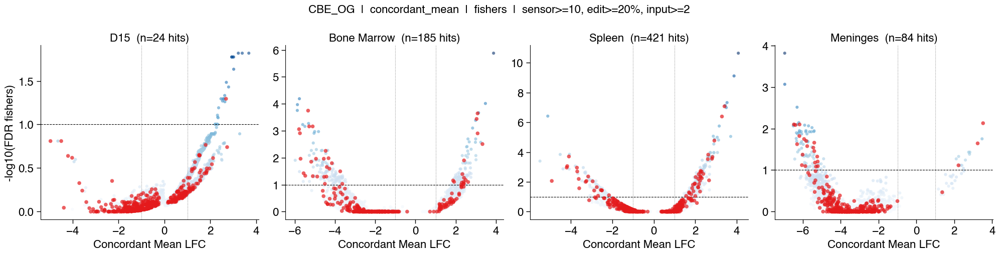

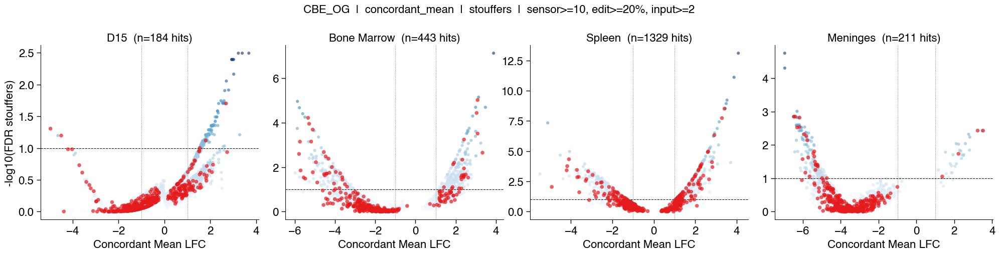

In [7]:
for screen, conds in [('ABE_OG', conds_og), ('CBE_OG', conds_og)]:
    for effect in ['median', 'avg', 'concordant_mean']:
        for fdr_m in ['fishers', 'stouffers']:
            volcano_plot(dfs[screen], screen, conds, effect=effect, fdr_method=fdr_m, is_og=True)


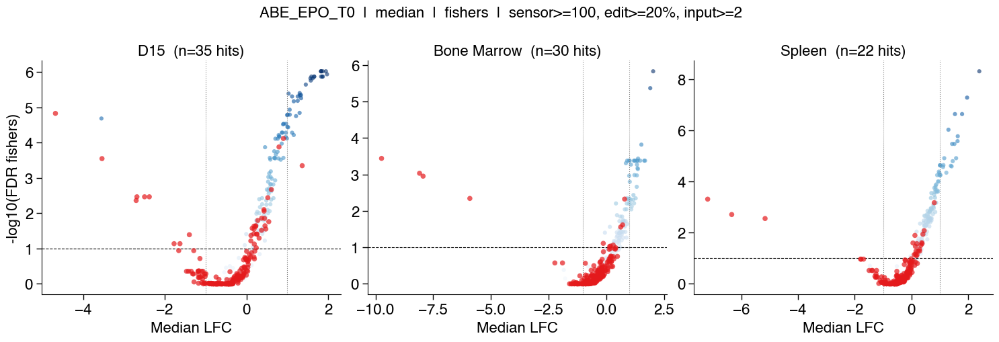

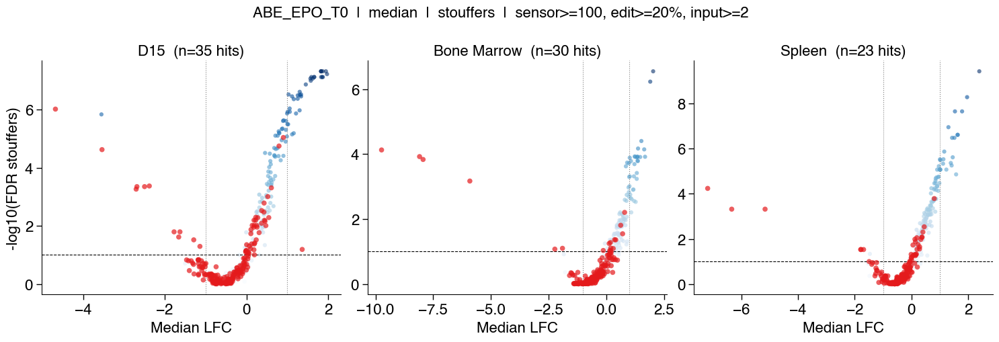

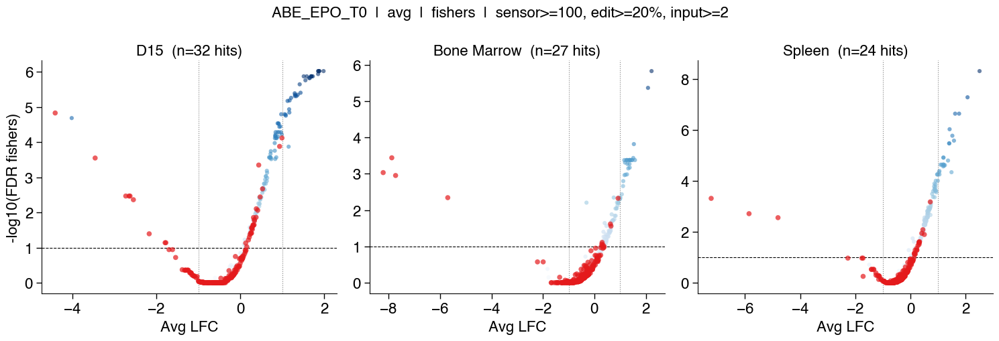

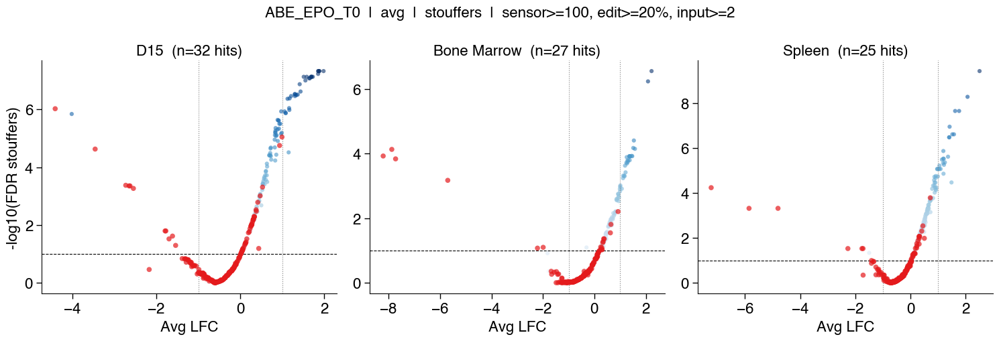

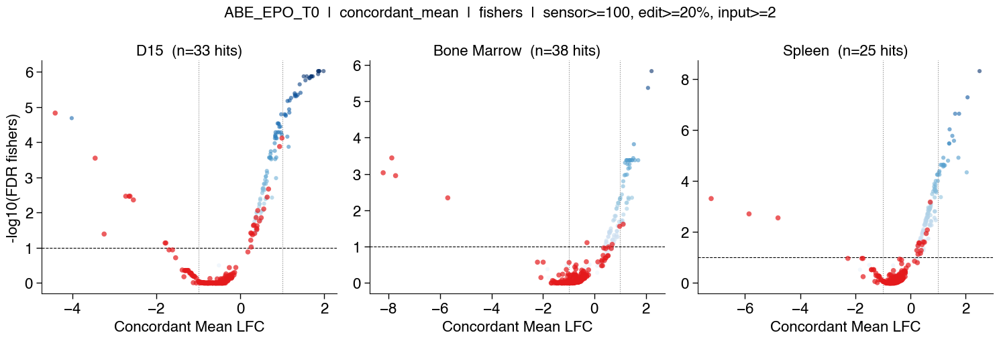

...

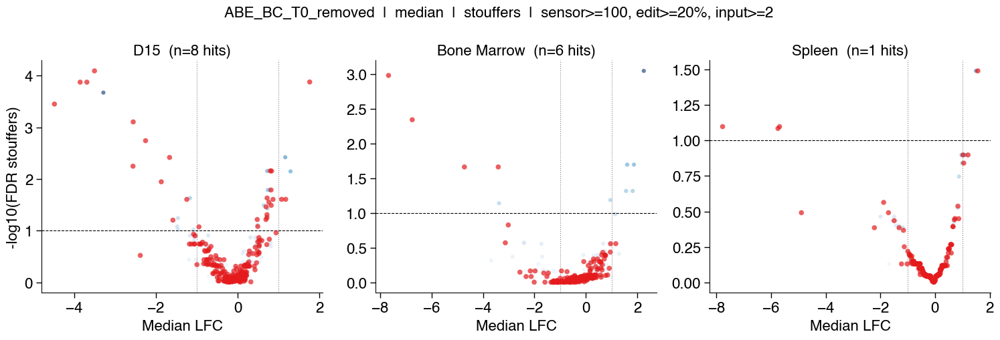

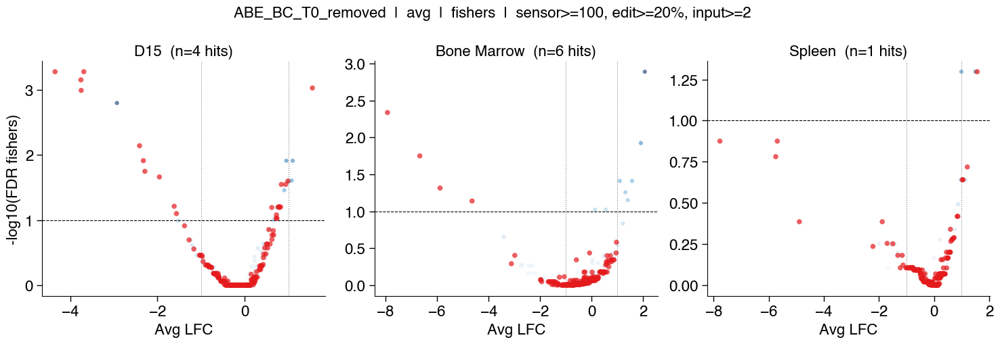

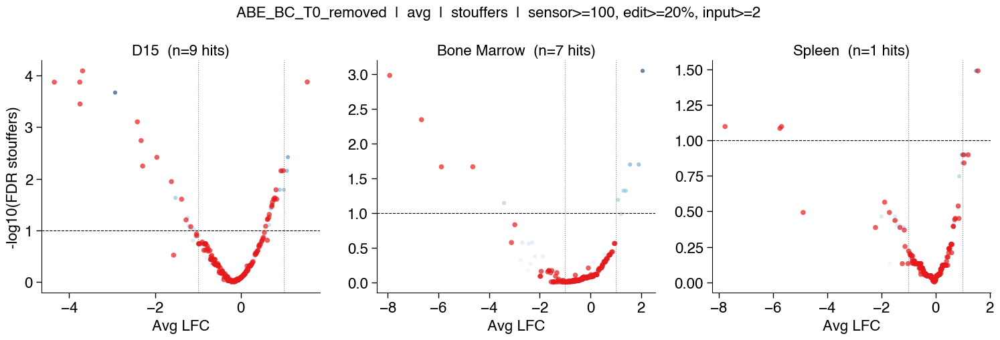

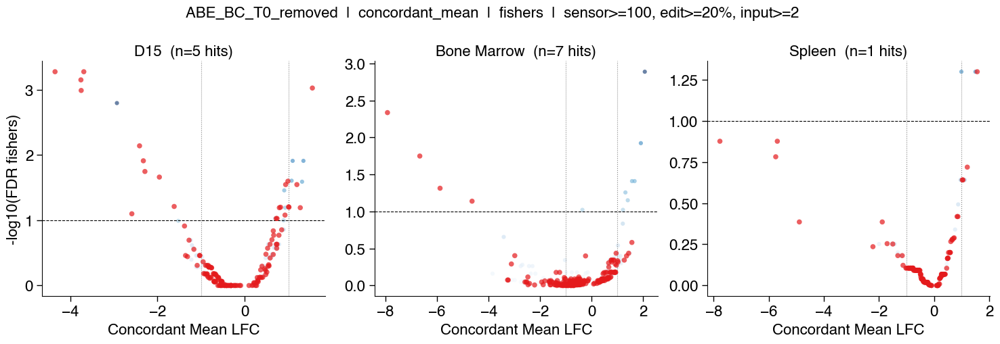

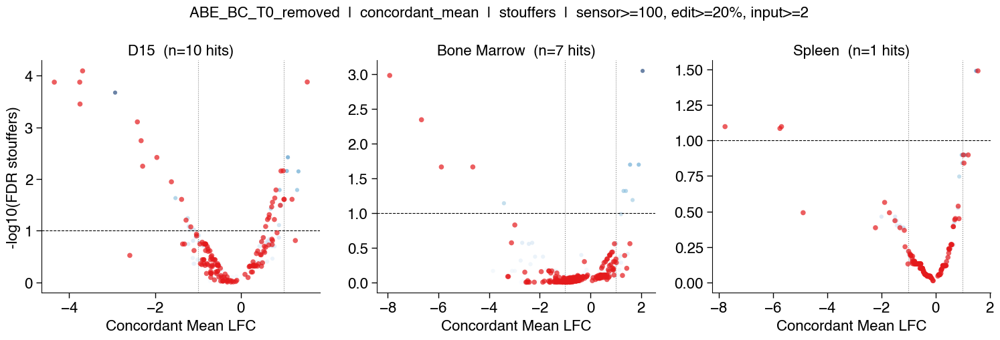

In [8]:
for screen in ['ABE_EPO_T0', 'CBE_EPO_T0', 'ABE_EPO_BC', 'CBE_EPO_BC']:
    if dfs.get(screen) is None: continue
    for effect in ['median', 'avg', 'concordant_mean']:
        for fdr_m in ['fishers', 'stouffers']:
            volcano_plot(dfs[screen], screen, conds_focused, effect=effect, fdr_method=fdr_m, is_og=False)


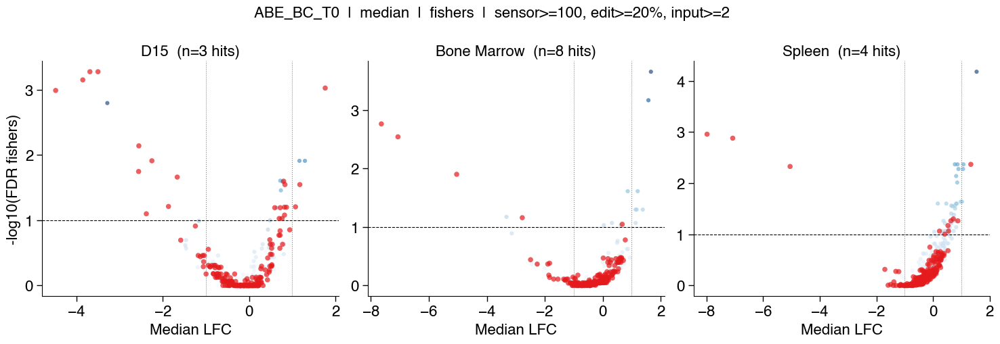

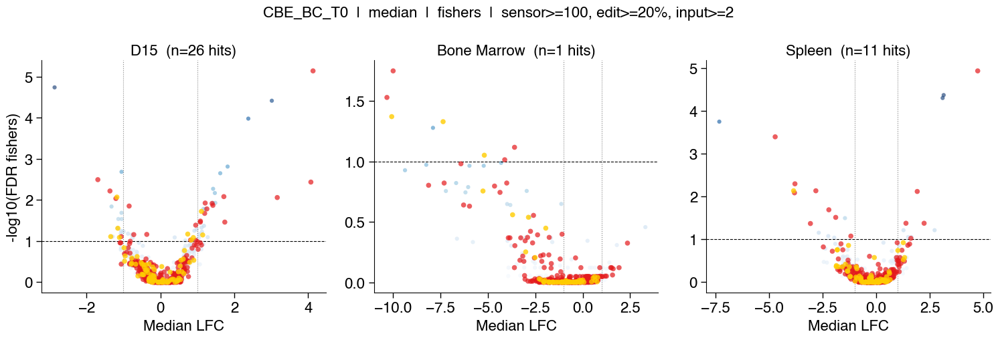

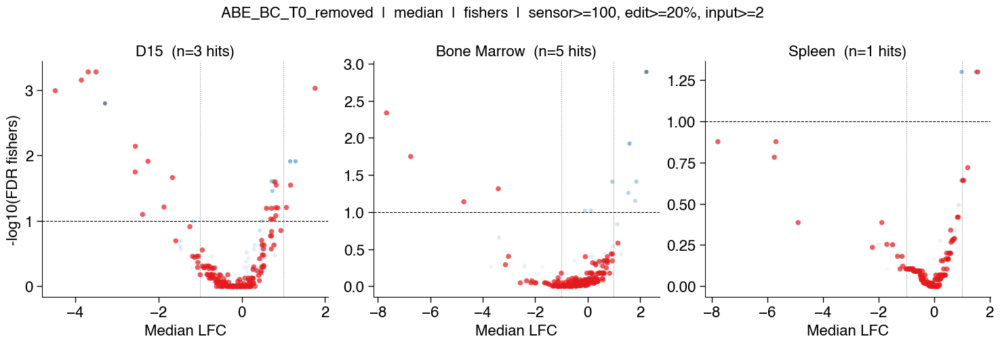

In [9]:
for screen in ['ABE_BC_T0', 'CBE_BC_T0']:
    if dfs.get(screen) is None: continue
    volcano_plot(dfs[screen], screen, conds_focused, effect='median', fdr_method='fishers', is_og=False)


# 7. Hit overlap

- **Fisher vs Stouffer** within each screen and condition
- **T0 vs BC baseline** (ABE_EPO_T0 vs ABE_EPO_BC; CBE_EPO_T0 vs CBE_EPO_BC)
- **Tissue-to-tissue** within each screen (UpSet plot)
- **ABE vs CBE** (focused screens, shared guides)

In [11]:
def get_hits(df, condition, fdr_method='fishers', fdr_cutoff=0.1,
             effect='median', lfc_dir='both', lfc_cutoff=1.0, is_og=False):
    # Filters: sensor_reads_{cond} >= min_sensor, target_base_edit_perc_{cond} >= 20,
    #          Input_median >= 2, |LFC| > lfc_cutoff
    # OG screens use min_sensor=10; focused screens use min_sensor=100
    min_sensor  = 10 if is_og else 100
    edit_cutoff = 20

    targ = df[df['classification'] == 'targeting guide'].copy()

    input_ok = targ['Input_median'] >= 2 if 'Input_median' in targ.columns else pd.Series(True, index=targ.index)
    reads_col = f'sensor_reads_{condition}'
    edit_col  = f'target_base_edit_perc_{condition}'
    if reads_col in targ.columns and edit_col in targ.columns:
        guide_ok = input_ok & (targ[reads_col] >= min_sensor) & (targ[edit_col] >= edit_cutoff)
    else:
        guide_ok = input_ok
    targ = targ[guide_ok]

    fdr_col = f'FDR_{condition}_{fdr_method}'
    lfc_col = f'LFC_{effect}_{condition}'
    if fdr_col not in targ.columns:
        return set()
    sig = targ[(targ[fdr_col] < fdr_cutoff) & (targ[lfc_col].abs() > lfc_cutoff)].dropna(subset=[lfc_col])
    if lfc_dir == 'enrich': sig = sig[sig[lfc_col] > 0]
    elif lfc_dir == 'deplet': sig = sig[sig[lfc_col] < 0]
    return set(sig['gRNA_id'])


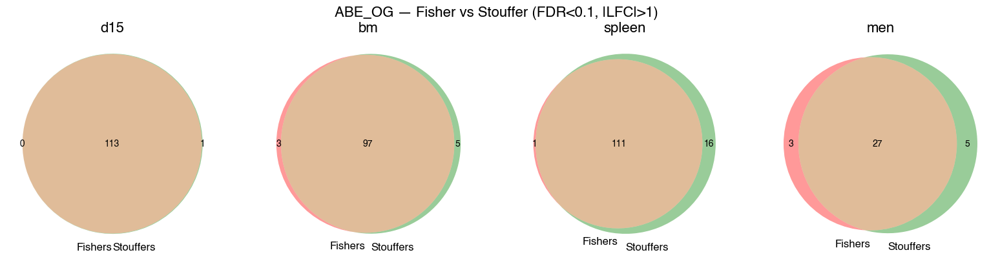

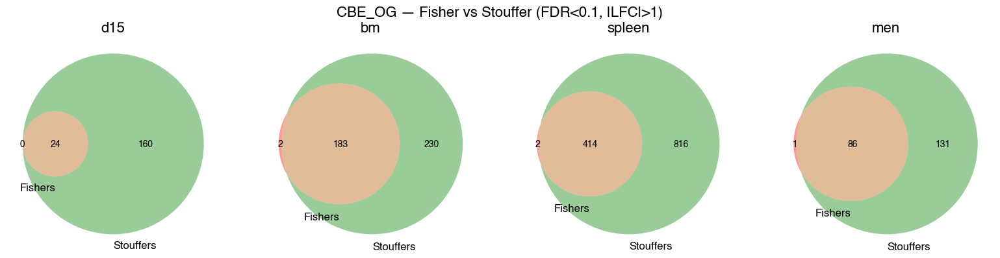

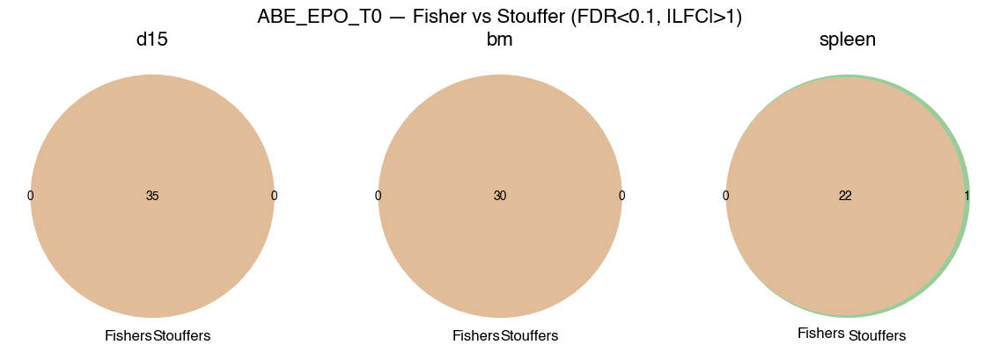

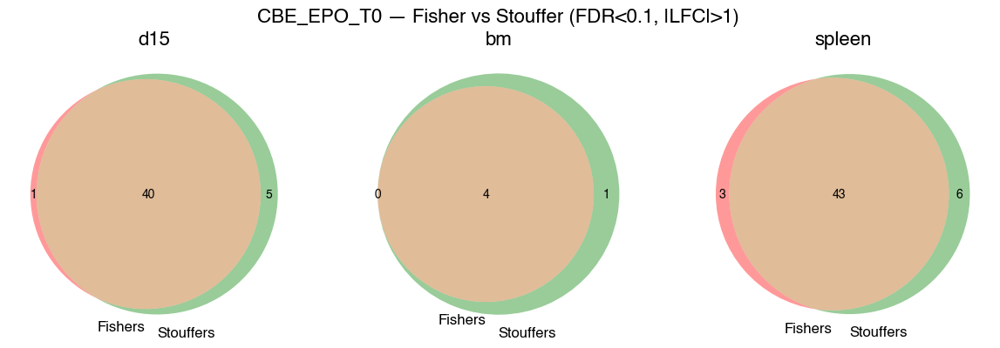

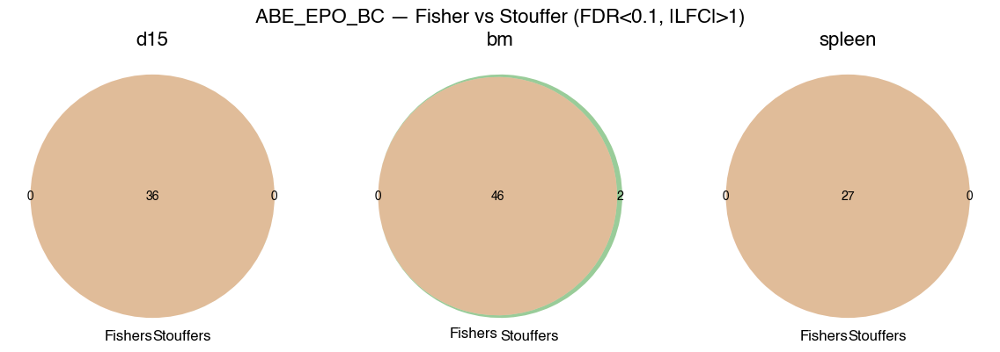

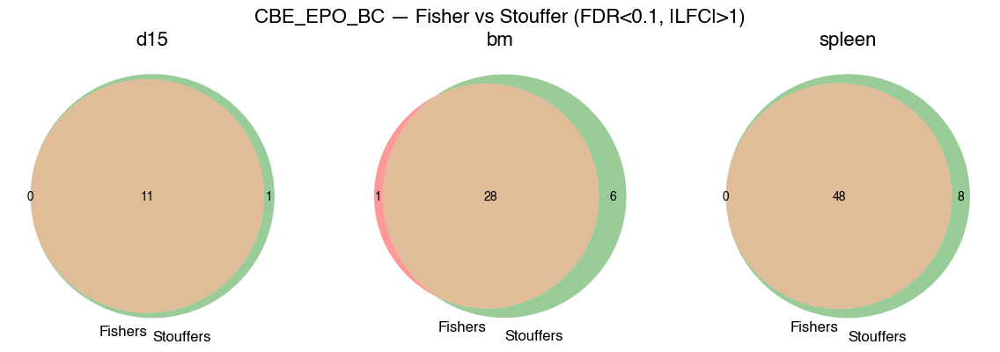

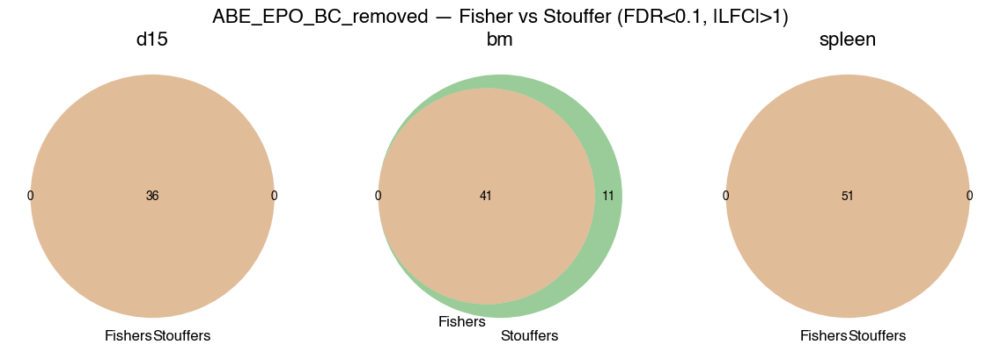

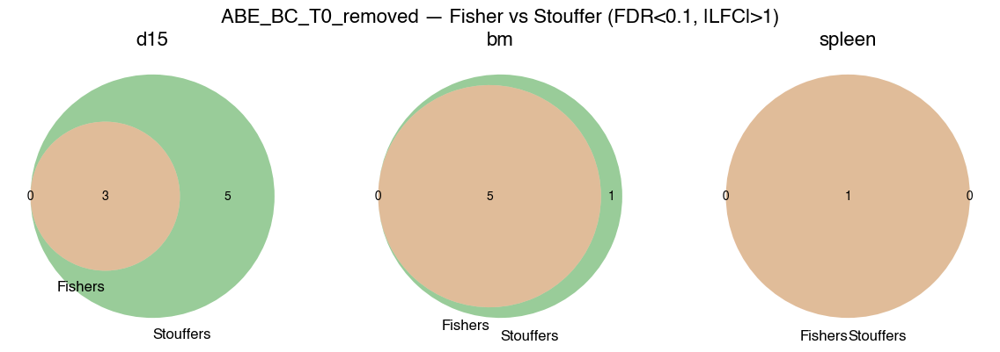

In [12]:
# Fisher vs Stouffer per screen per condition
for screen, conds, og in [('ABE_OG', conds_og, True), ('CBE_OG', conds_og, True),
                            ('ABE_EPO_T0', conds_focused, False), ('CBE_EPO_T0', conds_focused, False),
                            ('ABE_EPO_BC', conds_focused, False), ('CBE_EPO_BC', conds_focused, False),
]:
    if dfs.get(screen) is None: continue
    n = len(conds)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1: axes = [axes]
    for k, cond in enumerate(conds):
        venn2([get_hits(dfs[screen], cond, 'fishers',   is_og=og),
               get_hits(dfs[screen], cond, 'stouffers', is_og=og)],
              set_labels=('Fishers','Stouffers'), ax=axes[k])
        axes[k].set_title(cond, fontsize=16)
    fig.suptitle(f'{screen} — Fisher vs Stouffer (FDR<0.1, |LFC|>1)', fontsize=16)
    fig.tight_layout()
    plt.show()


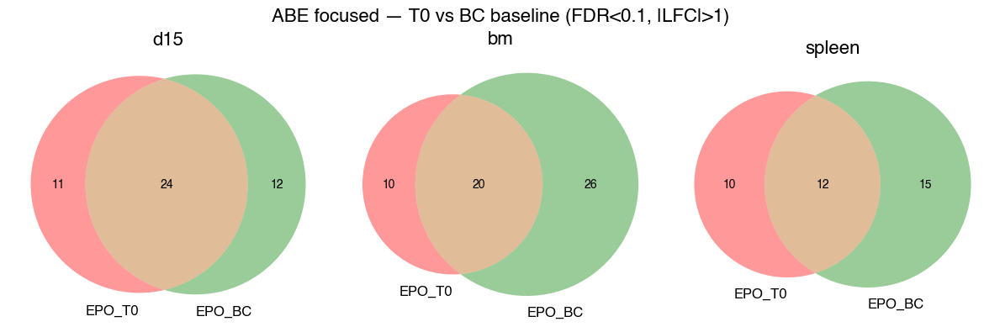

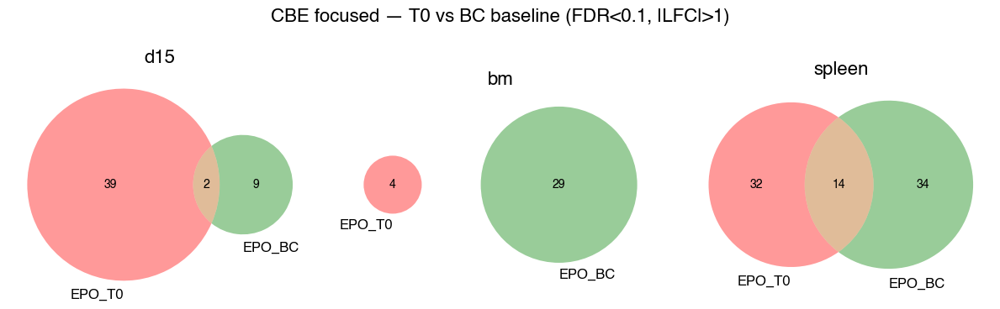

In [ ]:
# T0 vs BC baseline
for editor in ['ABE', 'CBE']:
    n = len(conds_focused)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1: axes = [axes]
    for k, cond in enumerate(conds_focused):
        venn2([get_hits(dfs[f'{editor}_EPO_T0'], cond, 'fishers', is_og=False),
               get_hits(dfs[f'{editor}_EPO_BC'], cond, 'fishers', is_og=False)],
              set_labels=('EPO_T0','EPO_BC'), ax=axes[k])
        axes[k].set_title(cond, fontsize=16)
    fig.suptitle(f'{editor} focused — T0 vs BC baseline (FDR<0.1, |LFC|>1)', fontsize=16)
    fig.tight_layout()
    plt.show()

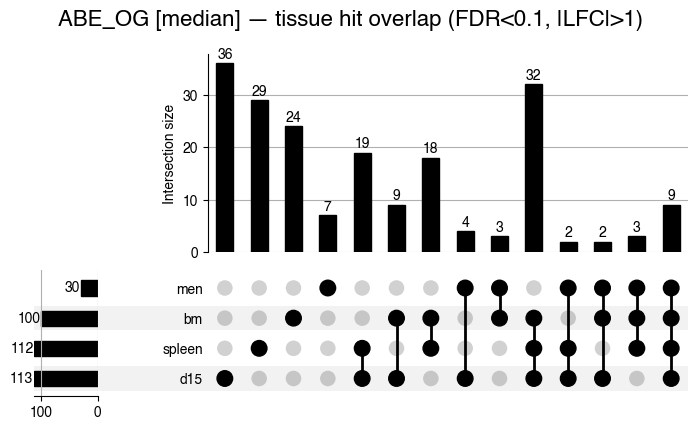

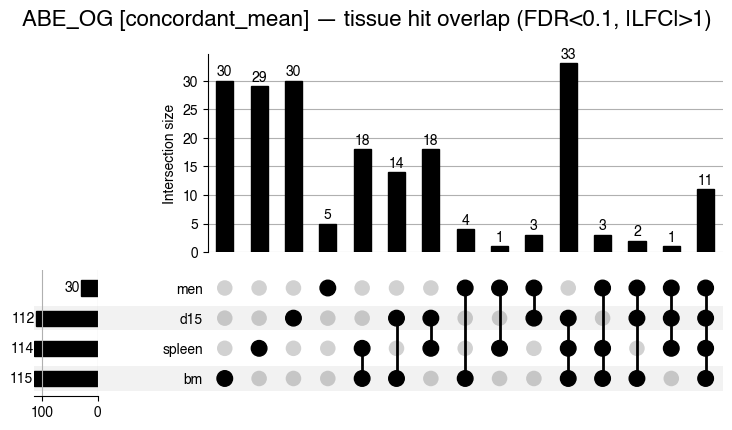

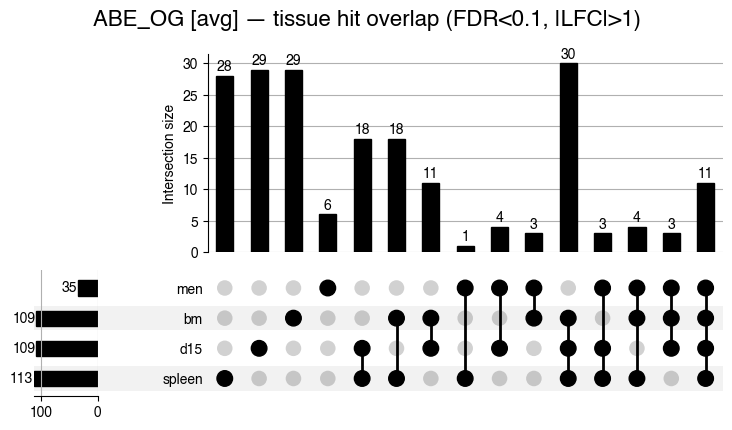

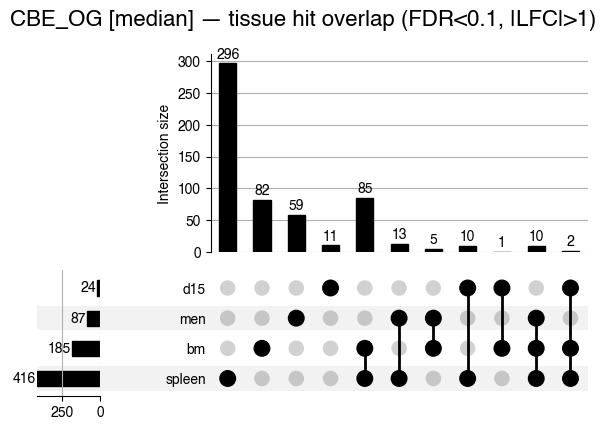

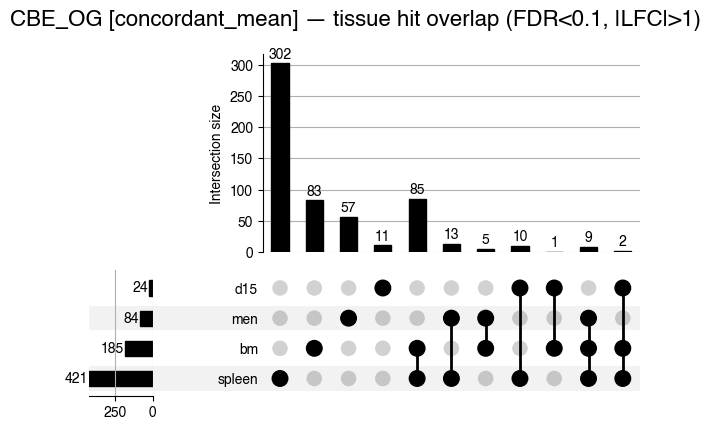

...

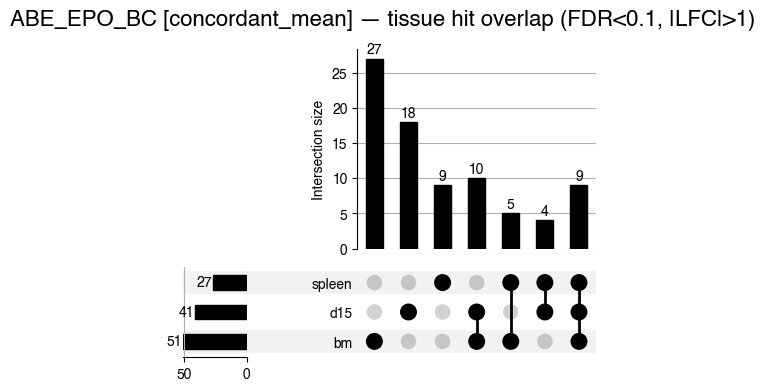

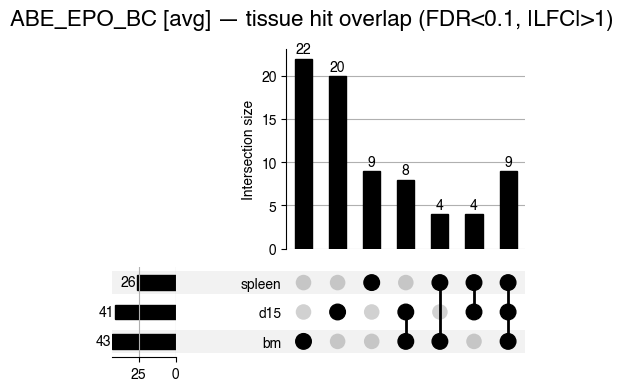

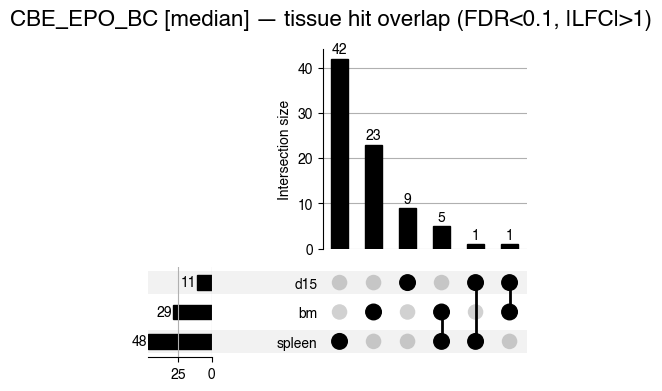

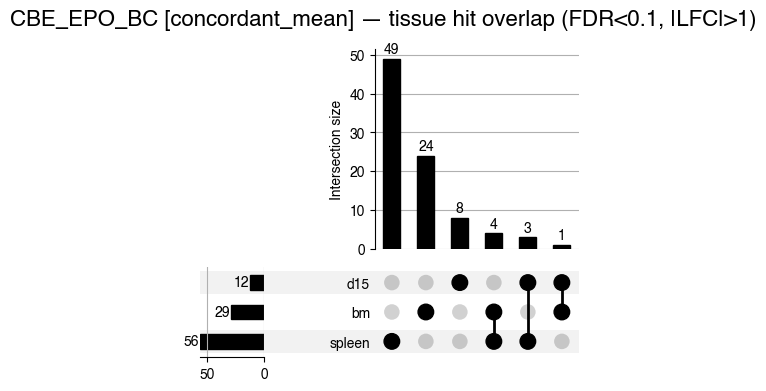

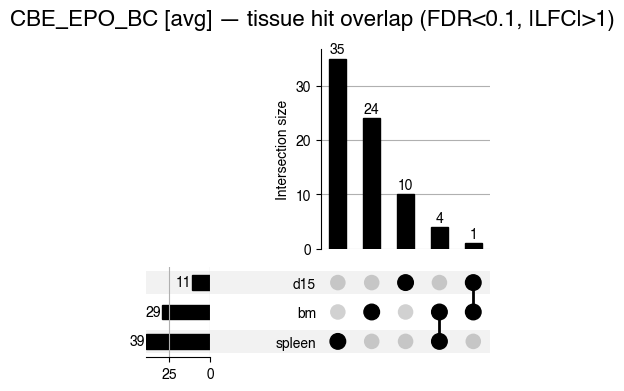

In [161]:
# Tissue-to-tissue UpSet
def upset_tissues(df, screen_name, conditions, fdr_method='fishers', fdr_cutoff=0.1,
                  effects=('median', 'concordant_mean', 'avg'), is_og=False):
    for effect in effects:
        hit_sets = {cond: get_hits(df, cond, fdr_method, fdr_cutoff,
                                   effect=effect, is_og=is_og) for cond in conditions}
        all_guides = set.union(*hit_sets.values()) if any(hit_sets.values()) else set()
        if not all_guides:
            print(f'{screen_name} [{effect}]: no hits'); continue
        membership = pd.DataFrame(
            {cond: [g in hit_sets[cond] for g in all_guides] for cond in conditions},
            index=list(all_guides)
        )
        data = from_indicators(conditions, data=membership)
        fig = plt.figure(figsize=(8, 4))
        UpSet(data, show_counts=True).plot(fig)
        fig.suptitle(f'{screen_name} [{effect}] — tissue hit overlap (FDR<{fdr_cutoff}, |LFC|>1)', fontsize=16)
        plt.show()

for screen, conds, og in [('ABE_OG', conds_og, True), ('CBE_OG', conds_og, True),
                            ('ABE_EPO_T0', conds_focused, False), ('CBE_EPO_T0', conds_focused, False),
                            ('ABE_EPO_BC', conds_focused, False), ('CBE_EPO_BC', conds_focused, False)]:
    upset_tissues(dfs[screen], screen, conds, is_og=og)

## 7b. Tissue-specific hit barplotter (boxplot + stripplot)

Identifies tissue-specific guides (in vitro-specific, in vivo-specific, spleen/BM-specific) using delta-LFC logic (SG figure3), then plots per-replicate LFC as boxplot + stripplot with editing efficiency heatmap on top.


=== Focused EPO (T0-anchored) | effect=median ===
  In vitro-specific  : 6 guides
  In vivo-specific   : 15 guides
  Spleen-specific    : 2 guides
  BM-specific        : 0 guides


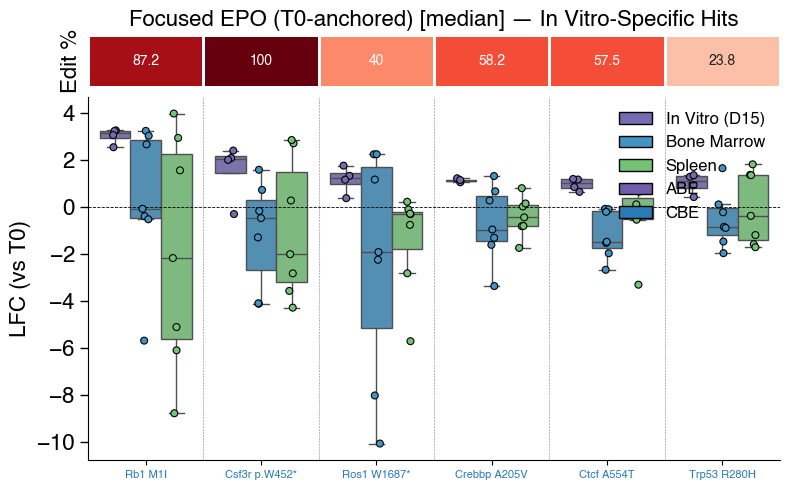

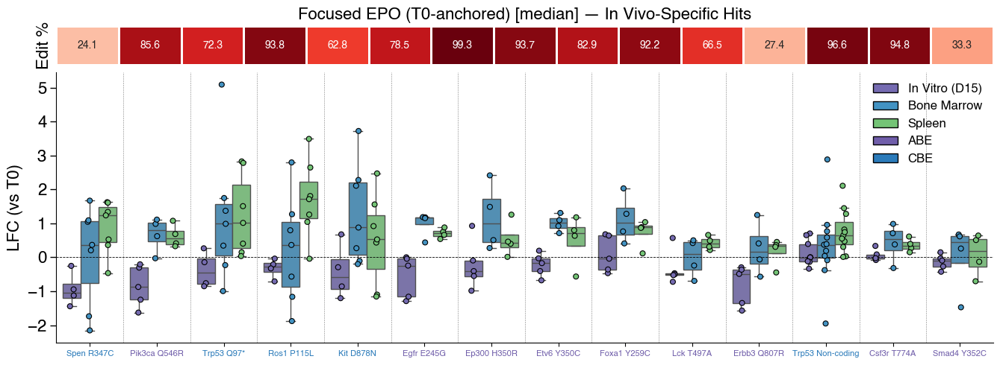

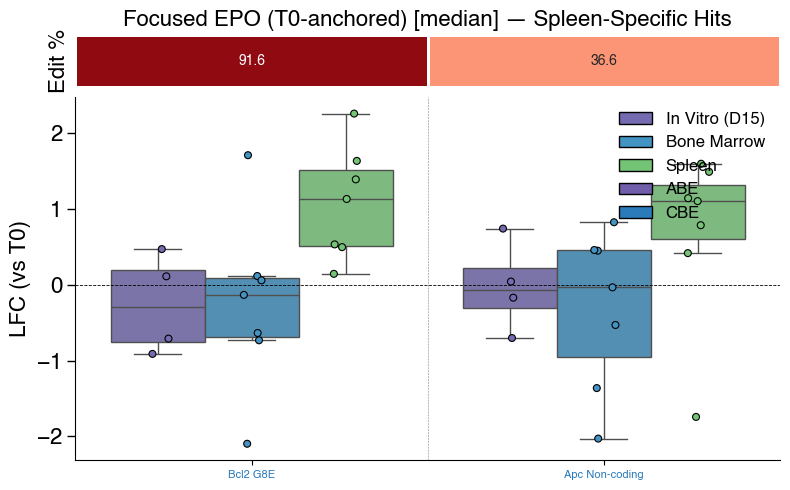

  [Focused EPO (T0-anchored) [median] — BM-Specific Hits] — no hits, skipping

=== Focused EPO (T0-anchored) | effect=concordant_mean ===
  In vitro-specific  : 0 guides
  In vivo-specific   : 7 guides
  Spleen-specific    : 2 guides
  BM-specific        : 1 guides
  [Focused EPO (T0-anchored) [concordant_mean] — In Vitro-Specific Hits] — no hits, skipping


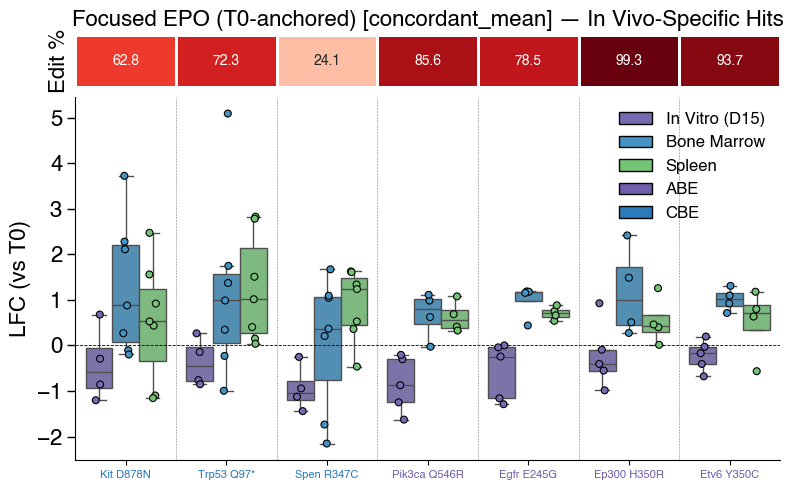

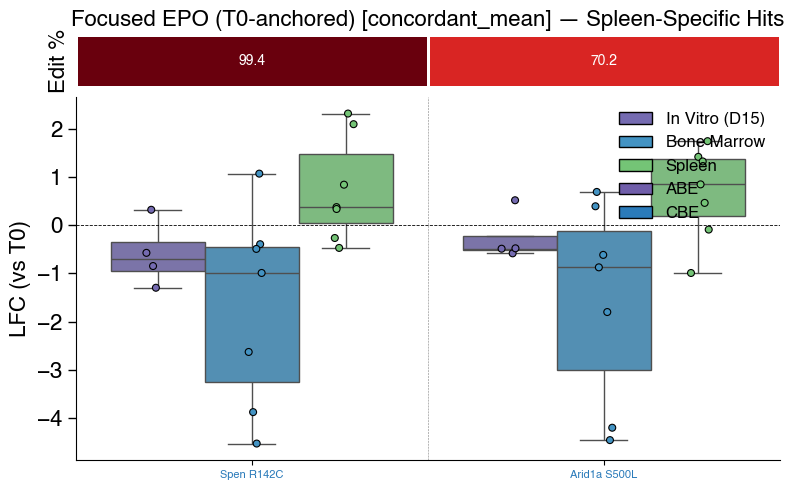

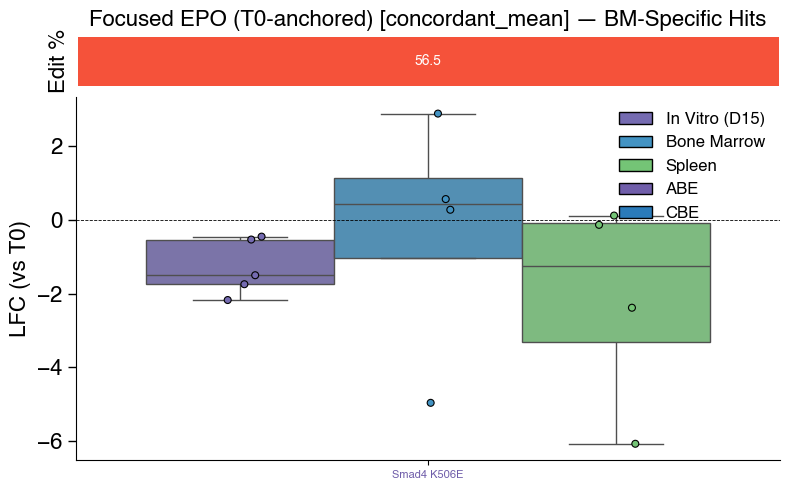


=== Focused EPO (T0-anchored) | effect=avg ===
  In vitro-specific  : 7 guides
  In vivo-specific   : 15 guides
  Spleen-specific    : 1 guides
  BM-specific        : 0 guides


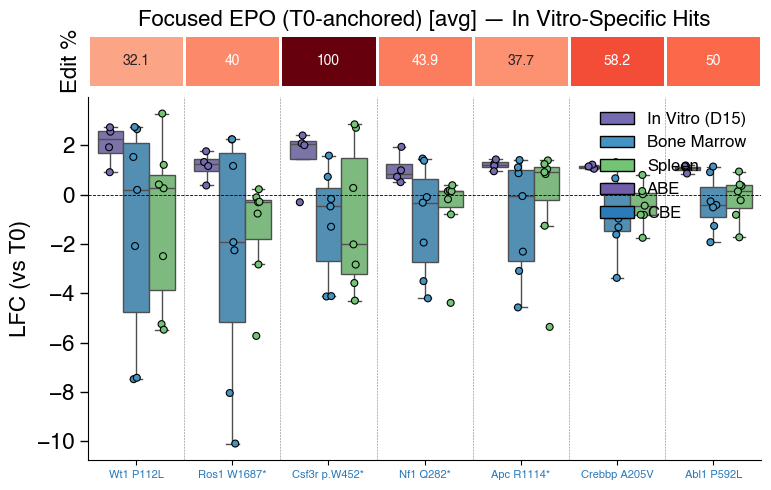

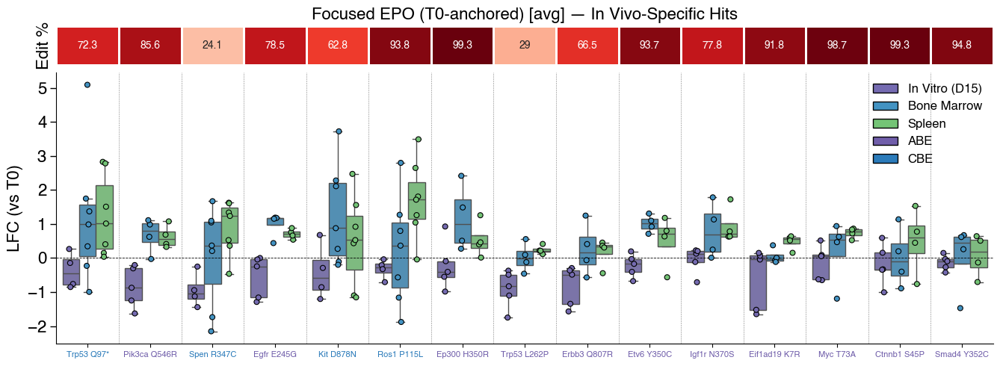

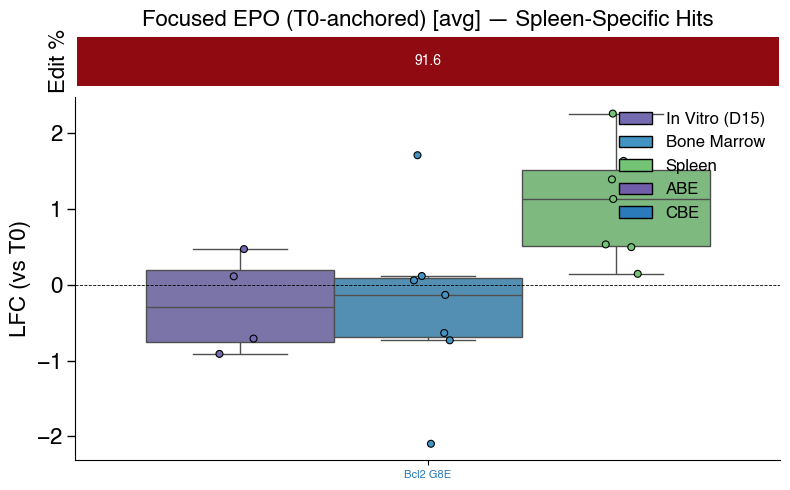

  [Focused EPO (T0-anchored) [avg] — BM-Specific Hits] — no hits, skipping

=== Focused EPO (BC-anchored) | effect=median ===
  In vitro-specific  : 4 guides
  In vivo-specific   : 26 guides
  Spleen-specific    : 5 guides
  BM-specific        : 8 guides


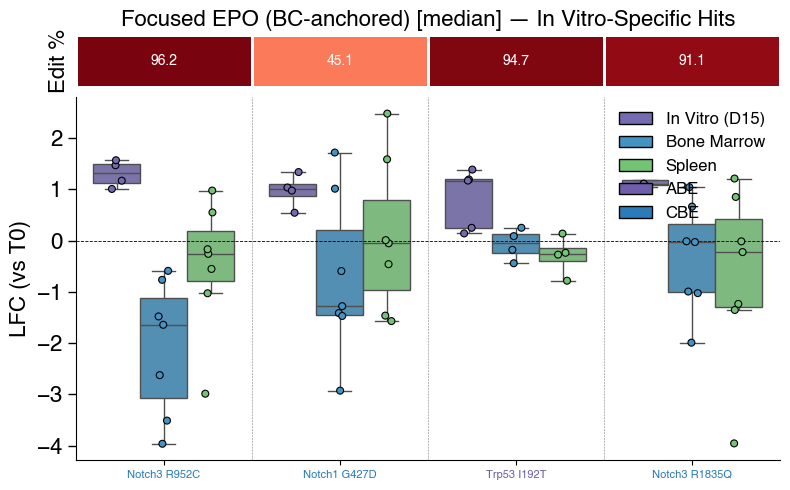

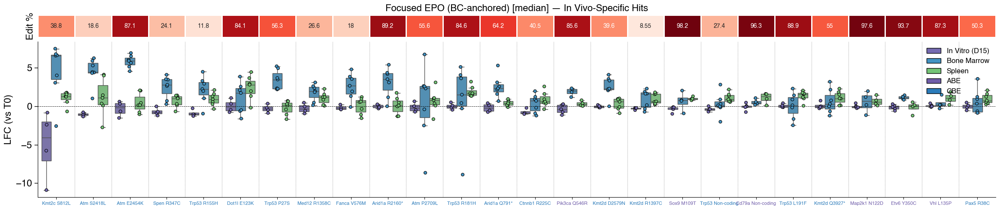

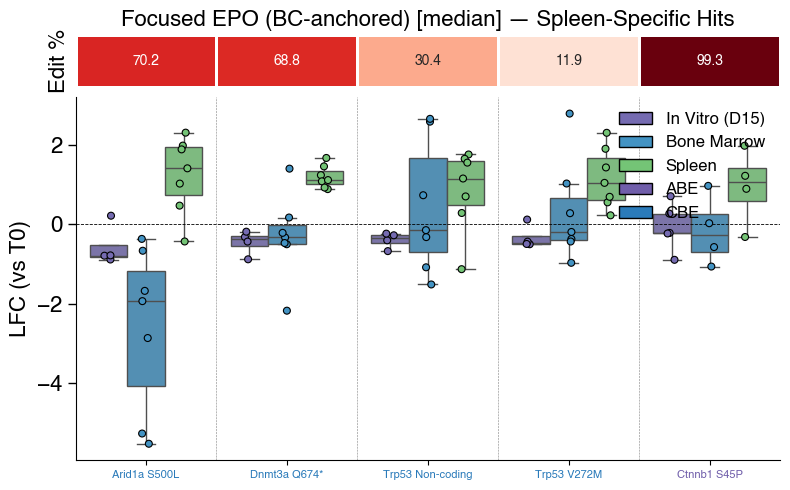

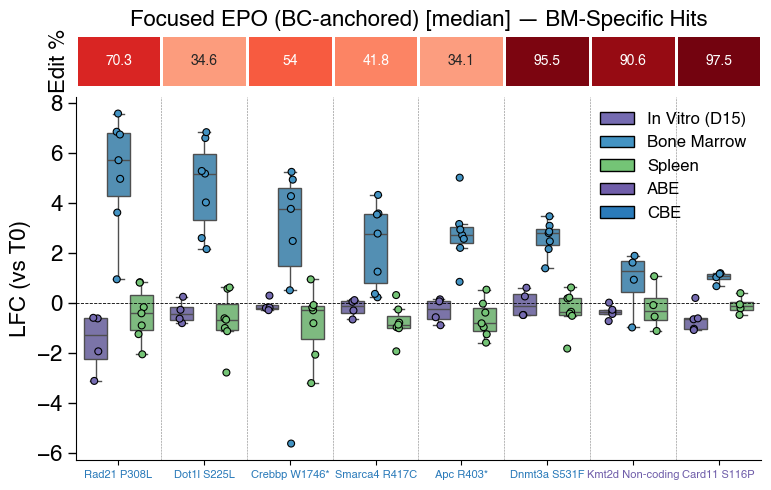


=== Focused EPO (BC-anchored) | effect=concordant_mean ===
  In vitro-specific  : 3 guides
  In vivo-specific   : 7 guides
  Spleen-specific    : 3 guides
  BM-specific        : 5 guides


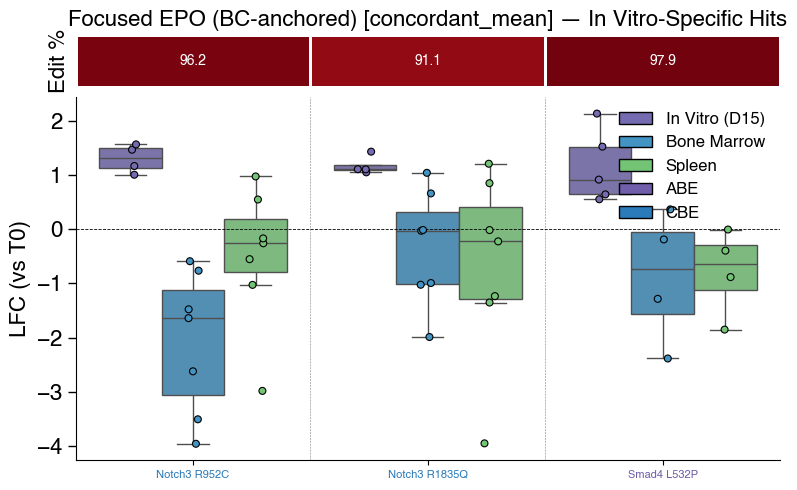

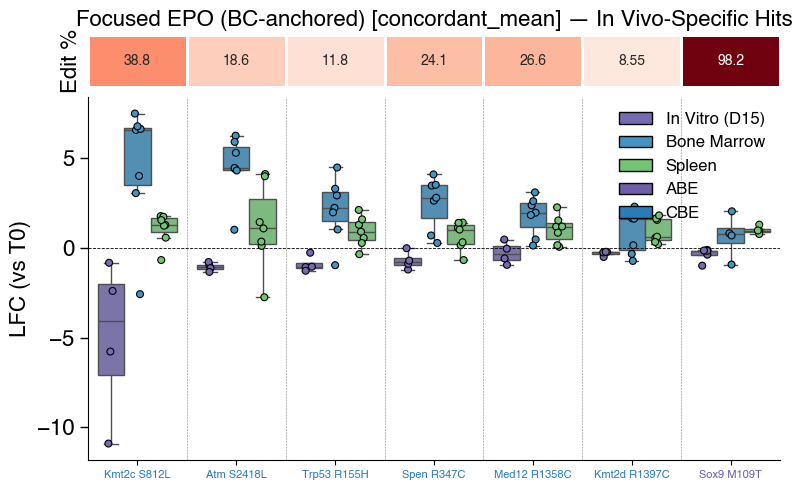

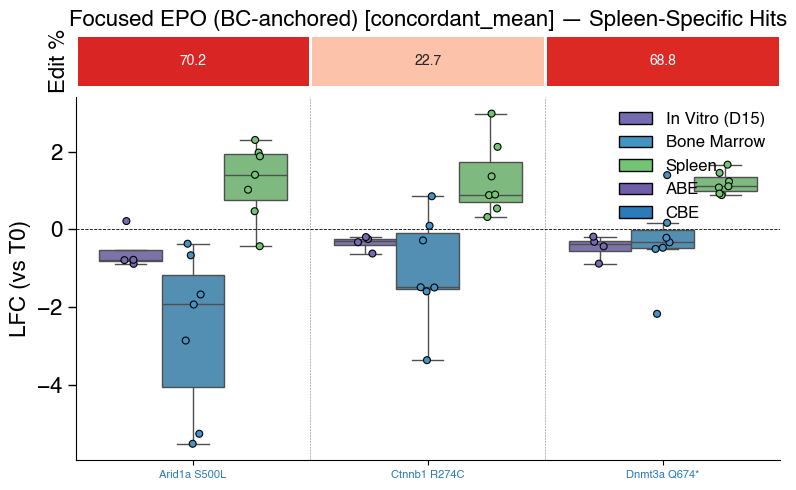

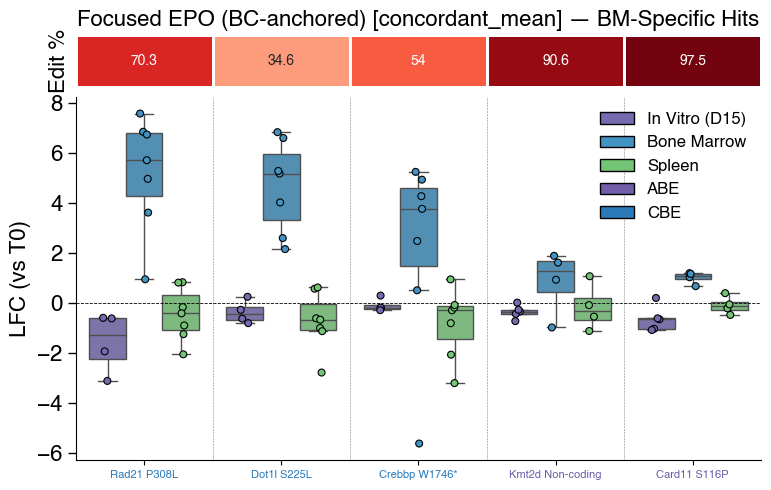


=== Focused EPO (BC-anchored) | effect=avg ===
  In vitro-specific  : 4 guides
  In vivo-specific   : 24 guides
  Spleen-specific    : 4 guides
  BM-specific        : 10 guides


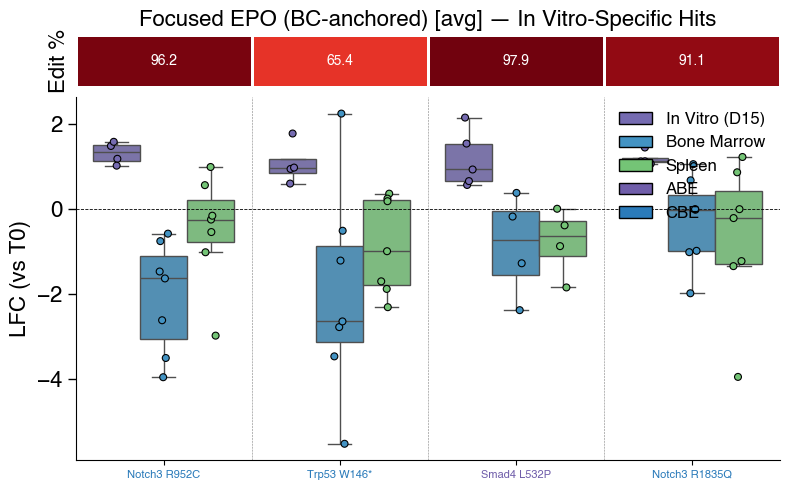

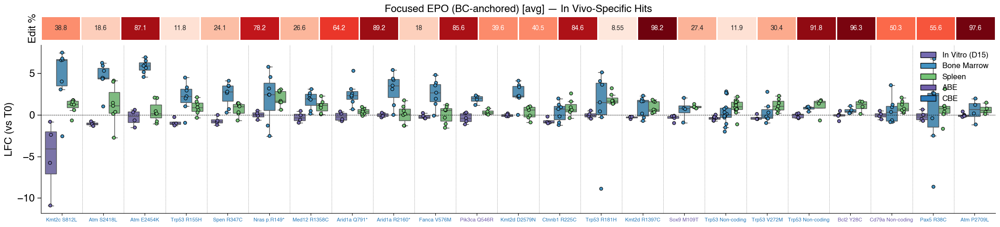

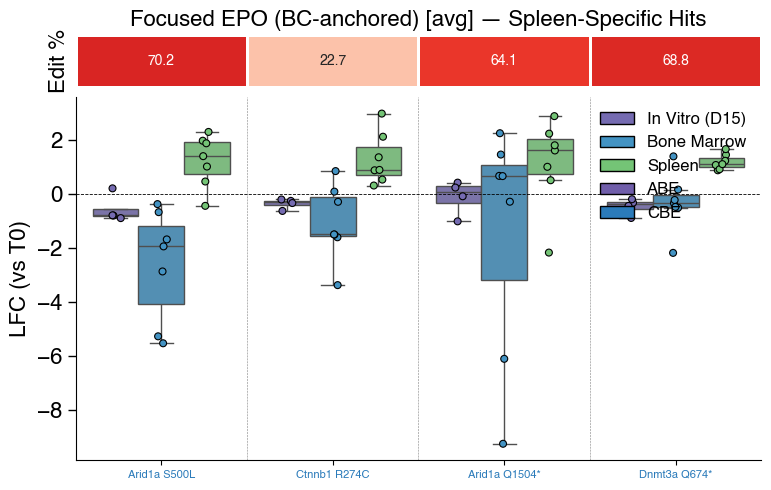

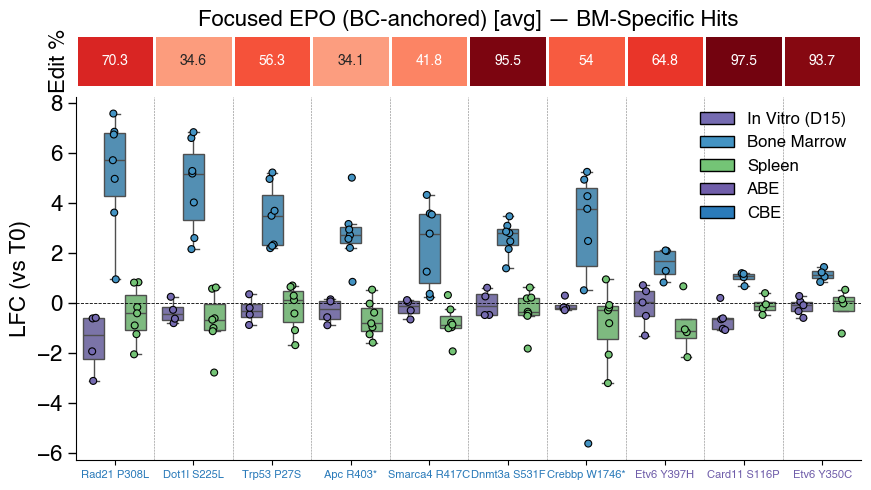


=== OG (T0-anchored) | effect=median ===
  In vitro-specific  : 6 guides
  In vivo-specific   : 17 guides
  Spleen-specific    : 6 guides
  BM-specific        : 2 guides


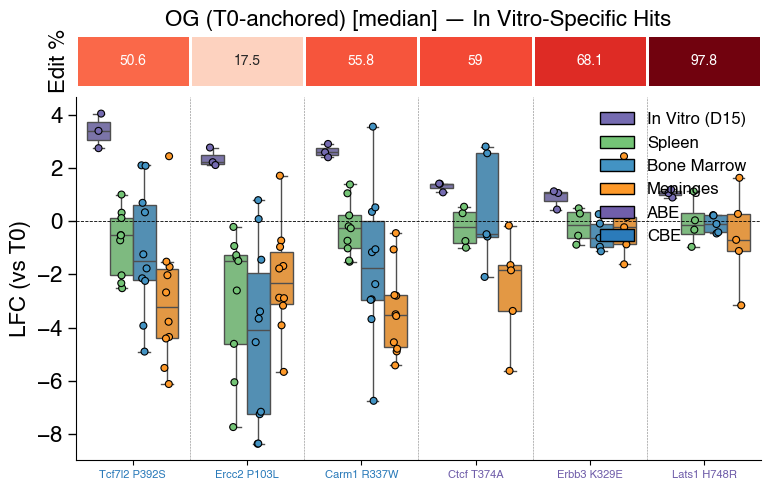

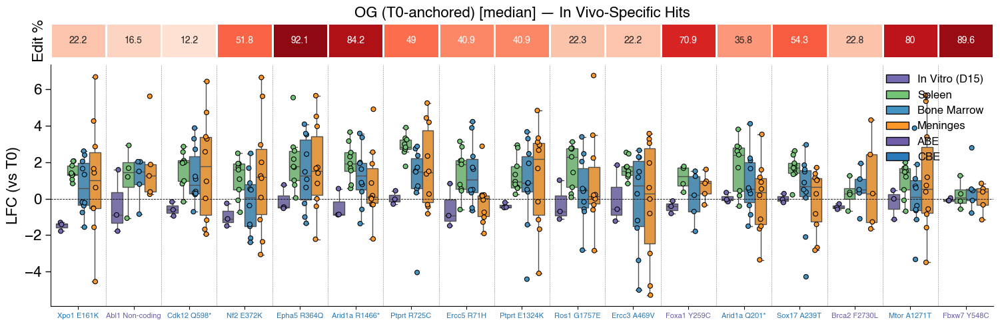

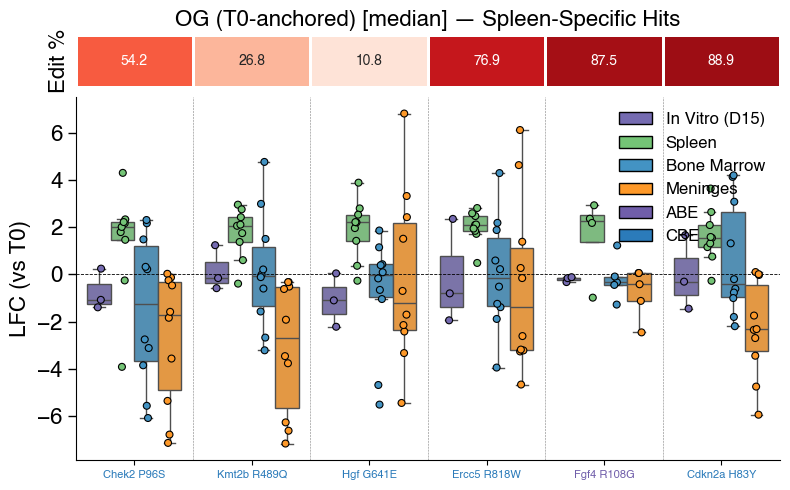

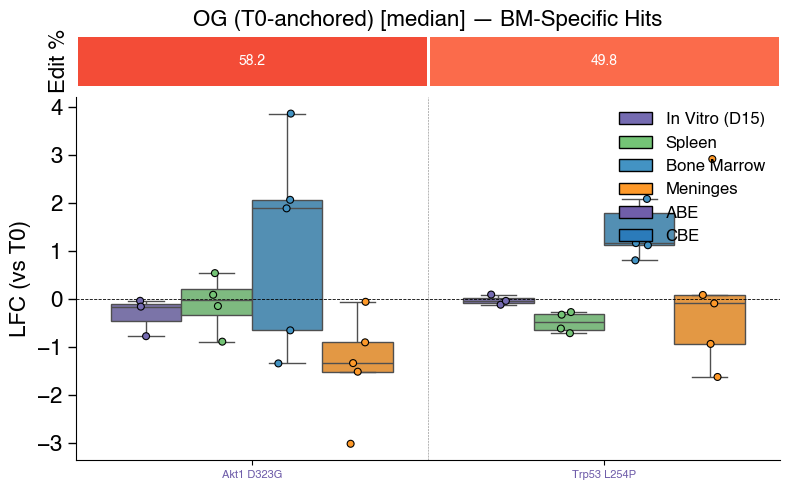


=== OG (T0-anchored) | effect=concordant_mean ===
  In vitro-specific  : 2 guides
  In vivo-specific   : 4 guides
  Spleen-specific    : 2 guides
  BM-specific        : 2 guides


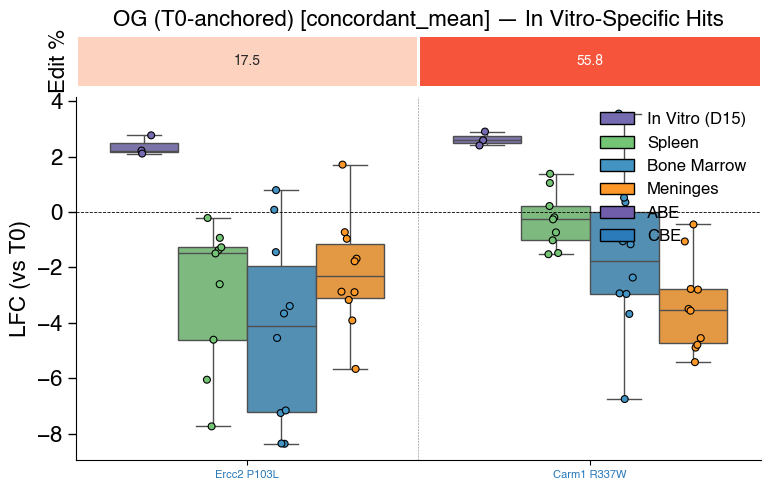

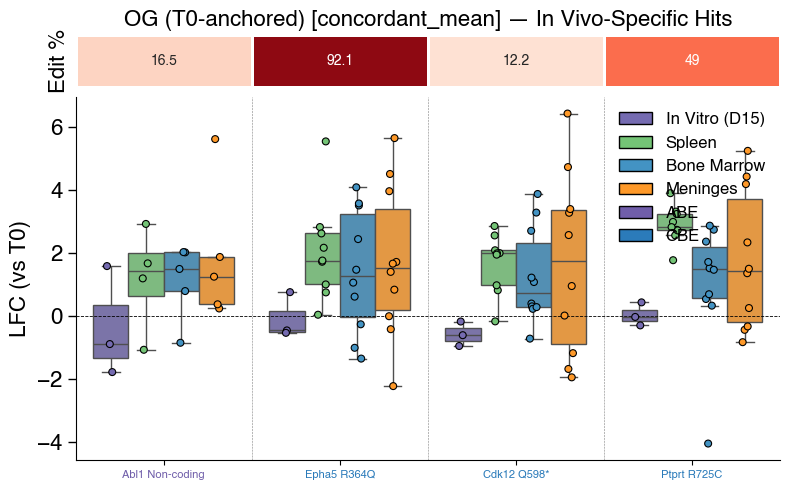

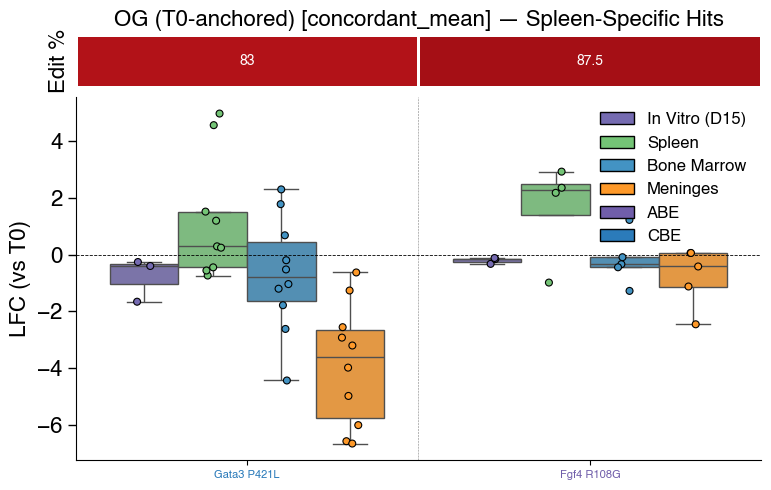

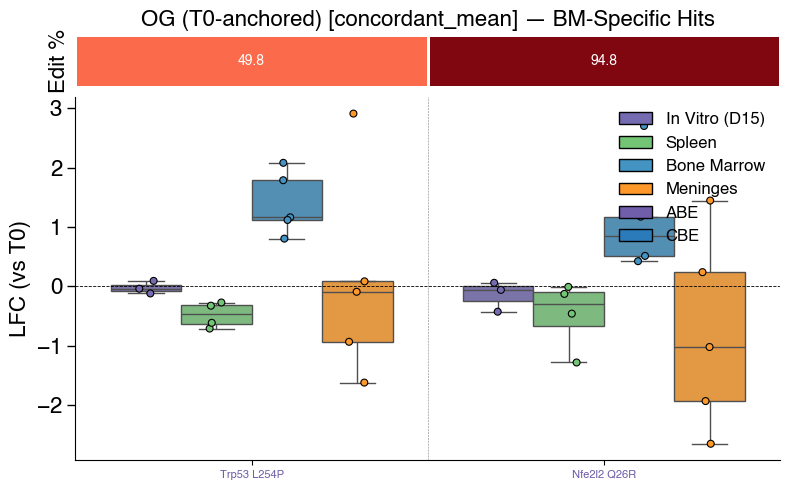


=== OG (T0-anchored) | effect=avg ===
  In vitro-specific  : 6 guides
  In vivo-specific   : 19 guides
  Spleen-specific    : 4 guides
  BM-specific        : 3 guides


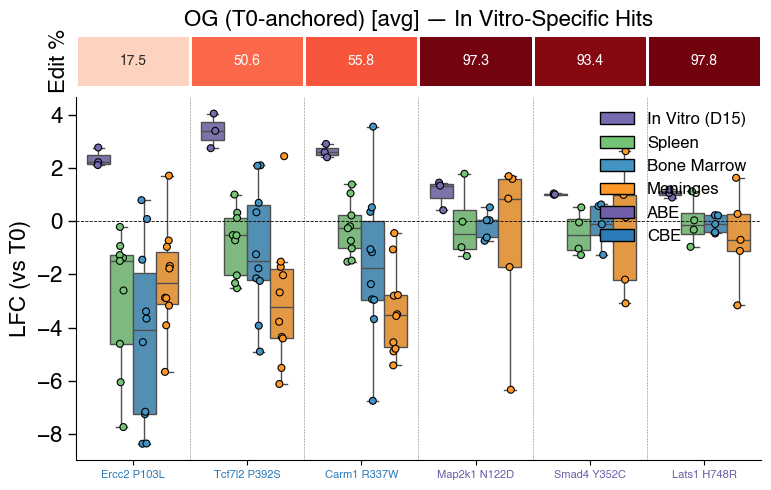

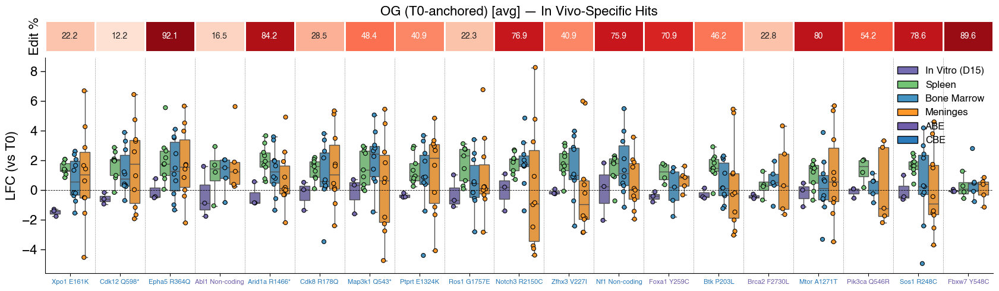

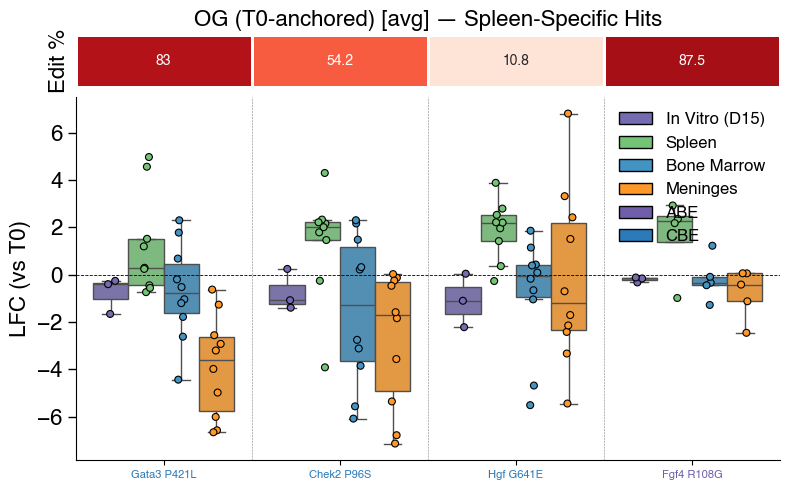

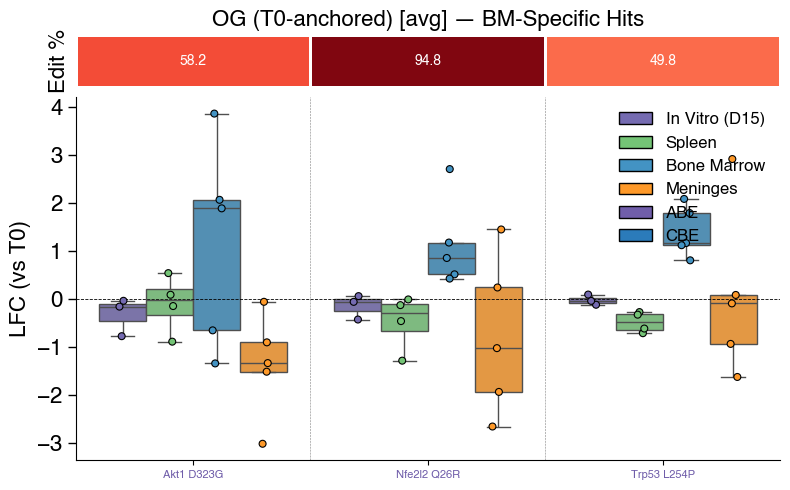

In [162]:
# ── replicate column maps
_ABE_SAMP = {           # focused EPO screens
    'bm':     ['bm1','bm3','bm4','bm5'],
    'spleen': ['spleen1','spleen3','spleen4','spleen5'],
    'd15':    ['d15-rep1','d15-rep2','d15-rep3','d15-rep4','d15-rep5'],
    'd5':     ['d5'],
}
_CBE_SAMP = {
    'bm':     ['bm1','bm3','bm4','bm6','bm7','bm9','bm10'],
    'spleen': ['spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10'],
    'd15':    ['d15-rep1','d15-rep3','d15-rep4','d15-rep5'],
    'd5':     ['d5'],
}
_ABE_SAMP_OG = {        # OG screens
    'bm':     ['bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5'],
    'spleen': ['spleen1','spleen2','spleen3','spleen4'],
    'men':    ['meninges1','meninges2','meninges3','meninges4','meninges5'],
    'd15':    ['d15_rep1','d15_rep2','d15_rep3'],
    'd5':     ['d5_rep1','d5_rep2','d5_rep3'],
}
_CBE_SAMP_OG = {
    'bm':     ['bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5',
               'bonemarrow6','bonemarrow7','bonemarrow8','bonemarrow9','bonemarrow10'],
    'spleen': ['spleen1','spleen2','spleen3','spleen4','spleen5',
               'spleen6','spleen7','spleen8','spleen9'],
    'men':    ['meninges1','meninges2','meninges3','meninges4','meninges5',
               'meninges6','meninges7','meninges8','meninges9','meninges10'],
    'd15':    ['d15_rep1','d15_rep2','d15_rep3'],
    'd5':     ['d5_rep1','d5_rep2','d5_rep3'],
}
_TISSUE_COLOR = {
    'd15':    '#756bb1',
    'spleen': '#74c476',
    'bm':     '#4393c3',
    'men':    '#fe9929',
    'd5':     '#bcbddc',
}
_TISSUE_LABEL = {'d15':'In Vitro (D15)', 'spleen':'Spleen', 'bm':'Bone Marrow',
                 'men':'Meninges', 'd5':'D5'}
_EDITOR_COLOR = {'ABE': purples[4], 'CBE': blues[4]}


def tissue_barplotter(subset_df, title='', figwidth=14, figheight=5,
                      plot_tissues=('d15','spleen','bm'), editor_col='Editor',
                      is_og=False, screen_key=None):
    df = subset_df.reset_index(drop=True).copy()

    xlabs = []
    for _, row in df.iterrows():
        mg = str(row.get('gene_name_m_corrected', row.get('Gene', '')))
        mv = str(row.get('HGVSp_m', ''))
        hv = str(row.get('HGVSp_h', ''))
        if hv.startswith('p.'): hv = hv[2:]
        if mv == 'Not calculated (legacy)': mv = hv
        xlabs.append(f'{mg} {mv}')

    records = []
    for _, row in df.iterrows():
        editor = row.get(editor_col, 'ABE')
        if is_og:
            samp_dict = _ABE_SAMP_OG if editor == 'ABE' else _CBE_SAMP_OG
        else:
            samp_dict = _ABE_SAMP if editor == 'ABE' else _CBE_SAMP
        mg = str(row.get('gene_name_m_corrected', row.get('Gene', '')))
        mv = str(row.get('HGVSp_m', ''))
        hv = str(row.get('HGVSp_h', ''))
        if hv.startswith('p.'): hv = hv[2:]
        if mv == 'Not calculated (legacy)': mv = hv
        label = f'{mg} {mv}'
        for tissue in plot_tissues:
            for rep_col in samp_dict.get(tissue, []):
                if rep_col in row.index:
                    records.append({'gRNA_id': row['gRNA_id'],
                                    'Mutation': label,
                                    'Tissue': tissue,
                                    'LFC': row[rep_col]})
    plot_df = pd.DataFrame(records)
    if plot_df.empty:
        print('No data to plot.'); return

    edit_vals = []
    for _, row in df.iterrows():
        vals = [row.get(f'target_base_edit_perc_{t}', np.nan) for t in plot_tissues]
        edit_vals.append(np.nanmean(vals))

    fig, ax = plt.subplots(2, 1, figsize=(figwidth, figheight),
                           height_ratios=[1, 7], sharex=False)
    sns.heatmap([np.array(edit_vals)], ax=ax[0], cbar=False, cmap='Reds',
                linewidth=1, annot=True, annot_kws={'fontsize': 10},
                vmin=0, vmax=100, fmt='.3g')
    ax[0].set_xticks([]); ax[0].set_yticks([])
    ax[0].set_ylabel('Edit %', fontsize=16)

    palette = [_TISSUE_COLOR[t] for t in plot_tissues]
    order   = list(plot_df['Mutation'].unique())
    sns.boxplot(data=plot_df, x='Mutation', y='LFC', hue='Tissue',
                ax=ax[1], order=order, palette=palette,
                hue_order=list(plot_tissues), showfliers=False, legend=False)
    sns.stripplot(data=plot_df, x='Mutation', y='LFC', hue='Tissue',
                  ax=ax[1], order=order, palette=palette,
                  hue_order=list(plot_tissues),
                  dodge=True, edgecolor='black', linewidth=0.8, size=5, legend=False)

    ax[1].set_xticklabels(xlabs, fontsize=8)
    ax[1].set_xlabel('')
    ax[1].set_ylabel('LFC (vs T0)', fontsize=16)
    ax[1].spines[['top','right']].set_visible(False)
    ax[1].tick_params(axis='y', labelsize=16, direction='out', length=6, width=1)
    ax[1].axhline(0, linestyle='--', color='black', linewidth=0.6)
    for k in range(len(df) - 1):
        ax[1].axvline(k + 0.5, linestyle='--', color='black', linewidth=0.4, alpha=0.5)

    editors = list(df[editor_col]) if editor_col in df.columns else ['ABE'] * len(df)
    for idx, tick in enumerate(ax[1].get_xticklabels()):
        tick.set_color(_EDITOR_COLOR.get(editors[idx], 'black'))

    tissue_handles = [Patch(facecolor=_TISSUE_COLOR[t], edgecolor='black', label=_TISSUE_LABEL[t])
                      for t in plot_tissues]
    editor_handles = [Patch(facecolor=_EDITOR_COLOR[e], edgecolor='black', label=e)
                      for e in ['ABE', 'CBE']]
    ax[1].legend(frameon=False, handles=tissue_handles + editor_handles,
                 loc='upper right', fontsize=12)
    ax[0].set_title(title, fontsize=16, fontweight='bold')
    fig.tight_layout()
    fig.subplots_adjust(hspace=0.05)
    plt.show()


def tissue_specific_hits(abe_key, cbe_key, screen_label,
                         conditions=('d15','spleen','bm'),
                         fdr_method='fishers', fdr_cutoff=0.1,
                         effects=('median', 'concordant_mean', 'avg'),
                         lfc_cutoff=1.0, min_sensor=100, min_edit=20, min_input=2,
                         max_guides_per_category=20, is_og=False):
    abe = dfs[abe_key].copy(); abe['Editor'] = 'ABE'
    cbe = dfs[cbe_key].copy(); cbe['Editor'] = 'CBE'
    combined = pd.concat([abe, cbe], ignore_index=True)

    targ = combined[combined['classification'] == 'targeting guide'].copy()
    in_conds = list(conditions)
    edit_cols   = [f'target_base_edit_perc_{c}' for c in in_conds if f'target_base_edit_perc_{c}' in targ.columns]
    sensor_cols = [f'sensor_reads_{c}'           for c in in_conds if f'sensor_reads_{c}'           in targ.columns]
    if edit_cols:
        targ = targ[(targ[edit_cols]   >= min_edit  ).any(axis=1)]
    if sensor_cols:
        targ = targ[(targ[sensor_cols] >= min_sensor).any(axis=1)]
    if 'Input_median' in targ.columns:
        targ = targ[targ['Input_median'] >= min_input]

    invivo_conds = [c for c in in_conds if c != 'd15']

    def fdr(c): return f'FDR_{c}_{fdr_method}'

    for effect in effects:
        def lfc(c): return f'LFC_{effect}_{c}'

        for c in in_conds:
            others = [lfc(o) for o in in_conds if o != c]
            if all(col in targ.columns for col in [lfc(c)] + others):
                targ[f'd_{effect}_{c}'] = targ[lfc(c)] - targ[others].mean(axis=1)

        # category 1: in vitro specific
        mask_iv = (targ[lfc('d15')] > lfc_cutoff) & (targ[fdr('d15')] < fdr_cutoff)
        for c in invivo_conds:
            if lfc(c) in targ.columns:
                mask_iv &= (targ[lfc(c)] < 0)
        invitro_hits = targ[mask_iv].sort_values(f'd_{effect}_d15', ascending=False)

        # category 2: in vivo specific
        mask_vivo = (targ[lfc('d15')] < 0)
        for c in invivo_conds:
            if lfc(c) in targ.columns:
                mask_vivo &= (targ[lfc(c)] > 0)
        fdr_vivo = pd.Series(False, index=targ.index)
        for c in invivo_conds:
            if fdr(c) in targ.columns:
                fdr_vivo |= (targ[fdr(c)] < fdr_cutoff)
        invivo_hits = targ[mask_vivo & fdr_vivo].sort_values(f'd_{effect}_d15', ascending=True)

        # category 3: spleen-specific
        mask_sp = ((targ[lfc('spleen')] > lfc_cutoff) & (targ[fdr('spleen')] < fdr_cutoff)
                   & (targ[lfc('d15')] < 0))
        if 'bm' in in_conds and lfc('bm') in targ.columns:
            mask_sp &= (targ[lfc('bm')] <= 0)
        spleen_hits = targ[mask_sp].sort_values(f'd_{effect}_spleen', ascending=False)

        # category 4: bm-specific
        mask_bm = pd.Series(False, index=targ.index)
        if 'bm' in in_conds and lfc('bm') in targ.columns:
            mask_bm = ((targ[lfc('bm')] > lfc_cutoff) & (targ[fdr('bm')] < fdr_cutoff)
                       & (targ[lfc('d15')] < 0) & (targ[lfc('spleen')] <= 0))
        d_bm_col = f'd_{effect}_bm'
        bm_hits = targ[mask_bm].sort_values(d_bm_col, ascending=False) if (mask_bm.any() and d_bm_col in targ.columns) else targ[mask_bm]

        print(f'\n=== {screen_label} | effect={effect} ===')
        print(f'  In vitro-specific  : {len(invitro_hits)} guides')
        print(f'  In vivo-specific   : {len(invivo_hits)} guides')
        print(f'  Spleen-specific    : {len(spleen_hits)} guides')
        print(f'  BM-specific        : {len(bm_hits)} guides')

        w_scale = 0.9
        for subset, title in [
            (invitro_hits,                          f'{screen_label} [{effect}] — In Vitro-Specific Hits'),
            (invivo_hits,                           f'{screen_label} [{effect}] — In Vivo-Specific Hits'),
            (spleen_hits[:max_guides_per_category], f'{screen_label} [{effect}] — Spleen-Specific Hits'),
            (bm_hits[:max_guides_per_category],     f'{screen_label} [{effect}] — BM-Specific Hits'),
        ]:
            if len(subset) == 0:
                print(f'  [{title}] — no hits, skipping'); continue
            fw = max(8, w_scale * len(subset))
            tissue_barplotter(subset, title=title, figwidth=fw,
                              plot_tissues=tuple(in_conds), is_og=is_og,
                              screen_key=abe_key)


# ── run: focused EPO (T0 and BC) + OG (T0)
for abe_k, cbe_k, label, conds, og in [
    ('ABE_EPO_T0', 'CBE_EPO_T0', 'Focused EPO (T0-anchored)', conds_focused, False),
    ('ABE_EPO_BC', 'CBE_EPO_BC', 'Focused EPO (BC-anchored)', conds_focused, False),
    ('ABE_OG',     'CBE_OG',     'OG (T0-anchored)',          ('d15','spleen','bm','men'), True),
]:
    if dfs.get(abe_k) is None or dfs.get(cbe_k) is None: continue
    tissue_specific_hits(abe_k, cbe_k, label, conditions=conds, is_og=og)

# 8. Tissue-specificity — cross-tissue LFC correlation

Pearson correlation heatmap and pairwise scatter of guide-level LFC across tissues.
How much do BM, spleen, and meninges (OG) share the same hits?

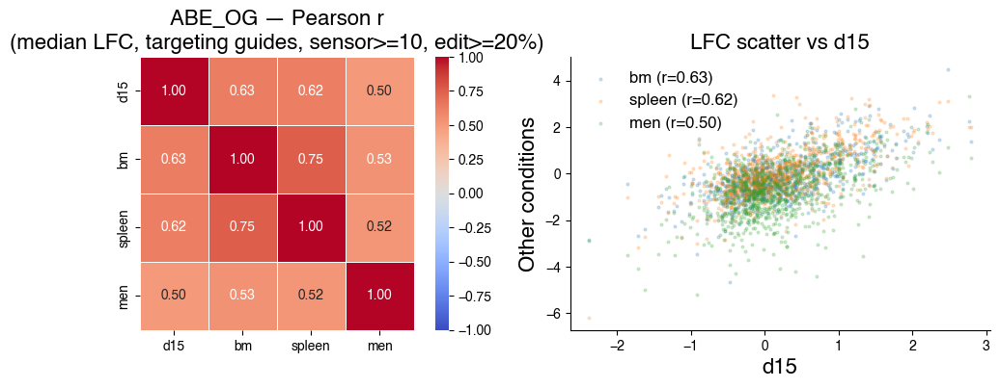

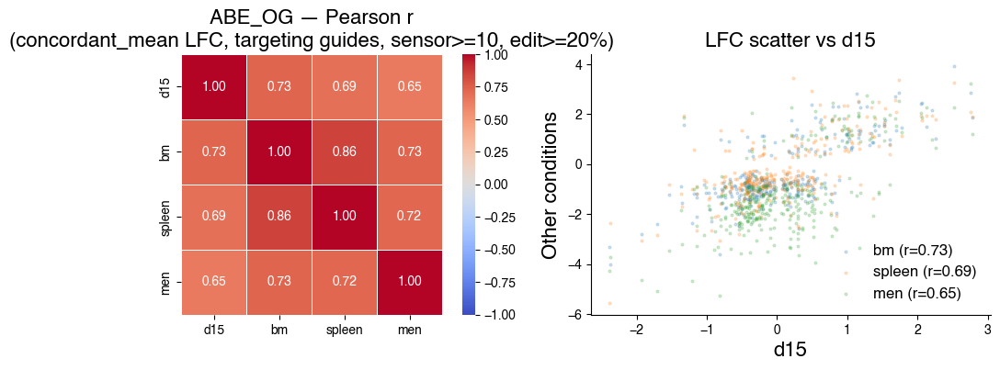

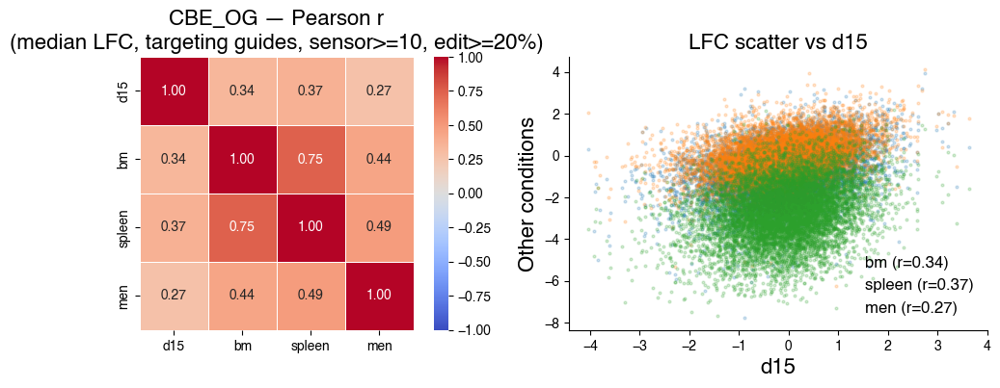

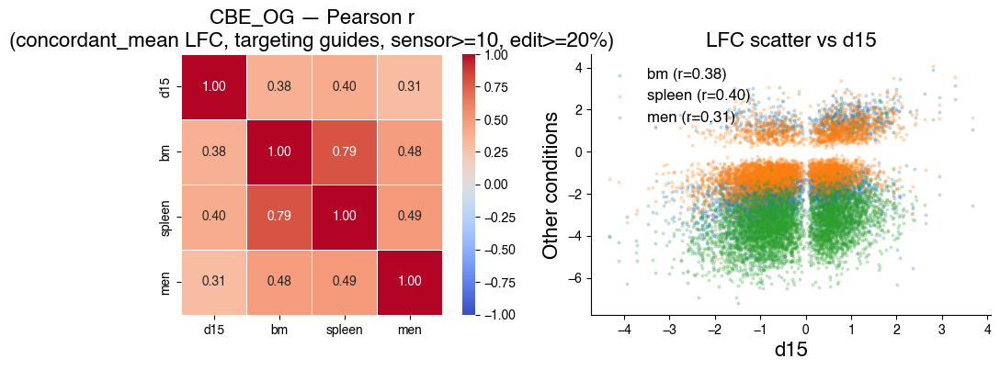

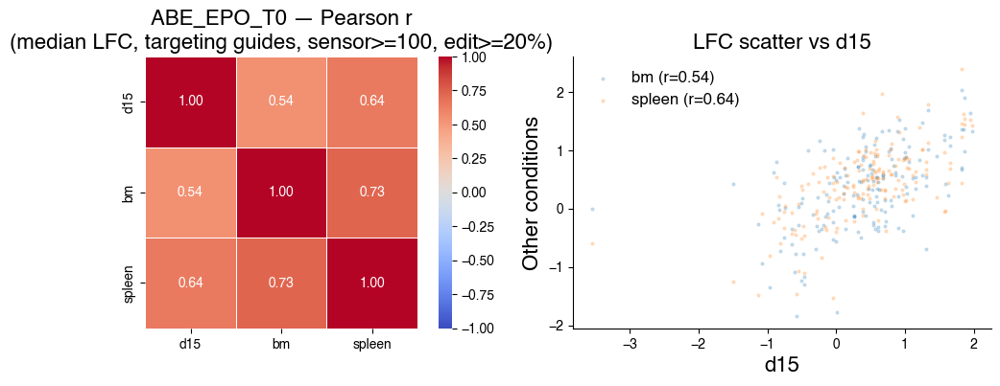

...

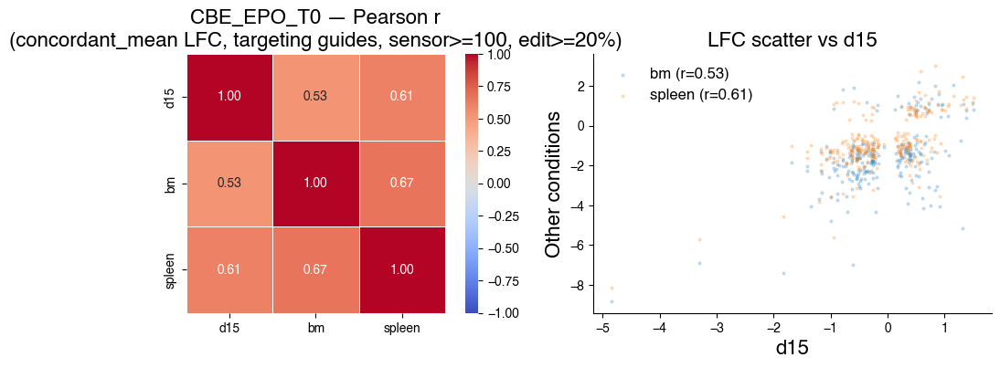

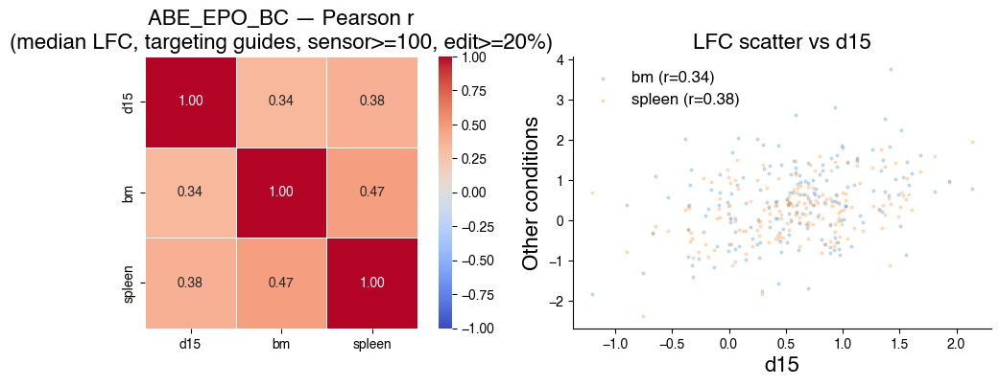

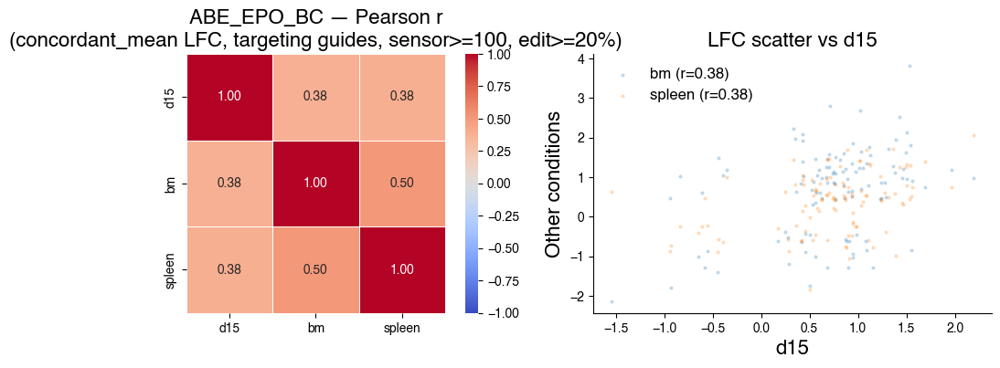

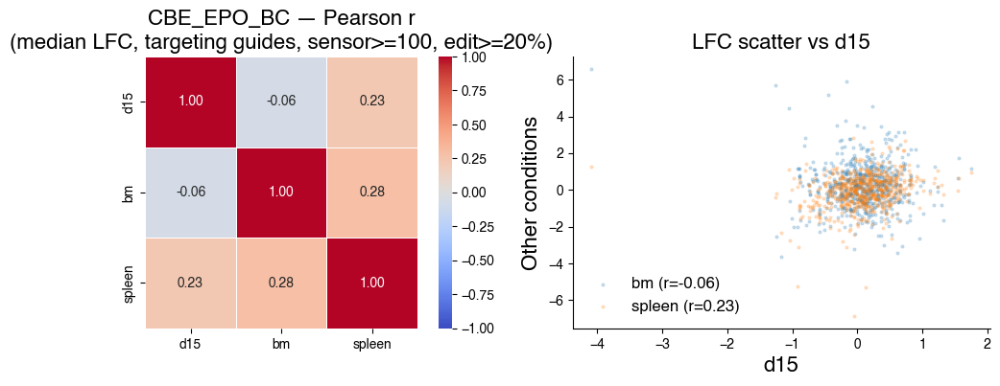

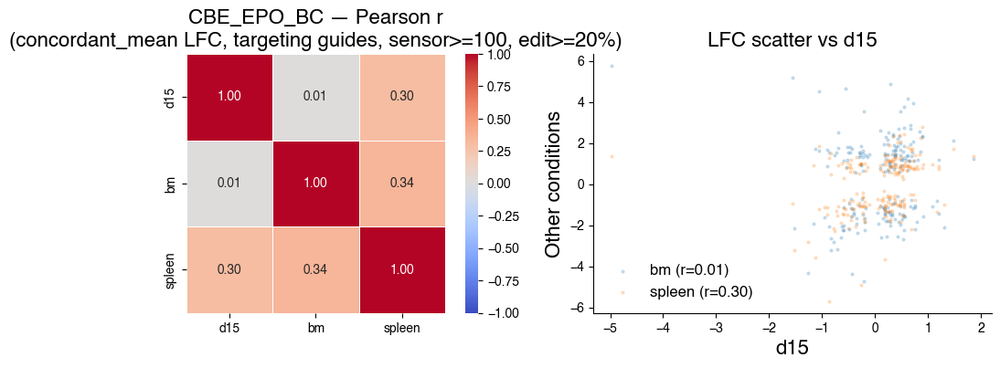

In [127]:
def tissue_correlation(df, screen_name, conditions, effect='median', is_og=False):
    min_sensor  = 10 if is_og else 100
    edit_cutoff = 20

    targ     = df[df['classification'] == 'targeting guide'].copy()
    input_ok = targ['Input_median'] >= 2 if 'Input_median' in targ.columns else pd.Series(True, index=targ.index)

    # Use the union of guides passing filter in any condition
    any_ok = pd.Series(False, index=targ.index)
    for cond in conditions:
        rc = f'sensor_reads_{cond}'; ec = f'target_base_edit_perc_{cond}'
        if rc in targ.columns and ec in targ.columns:
            any_ok |= (input_ok & (targ[rc] >= min_sensor) & (targ[ec] >= edit_cutoff))
        else:
            any_ok |= input_ok
    targ = targ[any_ok]

    lfc_cols = [f'LFC_{effect}_{c}' for c in conditions if f'LFC_{effect}_{c}' in targ.columns]
    sub = targ[lfc_cols].dropna()
    sub.columns = [c.replace(f'LFC_{effect}_','') for c in sub.columns]
    if sub.shape[1] < 2: return

    corr = sub.corr(method='pearson')
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
                ax=axes[0], square=True, linewidths=0.5, vmin=-1, vmax=1)
    axes[0].set_title(f'{screen_name} — Pearson r\n({effect} LFC, targeting guides, sensor>={min_sensor}, edit>=20%)', fontsize=16)

    ref = sub.columns[0]
    for other in sub.columns[1:]:
        r, _ = scipy.stats.pearsonr(sub[ref].dropna(), sub[other].dropna())
        axes[1].scatter(sub[ref], sub[other], s=4, alpha=0.2, label=f'{other} (r={r:.2f})')
    axes[1].set_xlabel(ref, fontsize=16); axes[1].set_ylabel('Other conditions', fontsize=16)
    axes[1].legend(frameon=False, fontsize=12); axes[1].spines[['top','right']].set_visible(False)
    axes[1].set_title(f'LFC scatter vs {ref}', fontsize=16)
    fig.tight_layout(); plt.show()

for screen, conds, og in [('ABE_OG', conds_og, True), ('CBE_OG', conds_og, True),
                            ('ABE_EPO_T0', conds_focused, False), ('CBE_EPO_T0', conds_focused, False),
                            ('ABE_EPO_BC', conds_focused, False), ('CBE_EPO_BC', conds_focused, False),
]:
    if dfs.get(screen) is None: continue
    for effect in ['median', 'concordant_mean']:
        tissue_correlation(dfs[screen], screen, conds, effect=effect, is_og=og)


# 9. EPO vs BC null validation

Key validation: guides significant in EPO screen should NOT be significant in BC_T0.
Scatter EPO LFC vs BC LFC for each condition, colored by significance category:
- **Green**: EPO only → likely editing-dependent
- **Red**: Both → guide-intrinsic (off-target toxicity, sequence dropout) — should be excluded from null dist
- **Orange**: BC only → spurious noise
- **Grey**: Neither

In [128]:
def epo_vs_bc_scatter(epo_key, bc_key, label, conditions,
                       effect='median', fdr_method='fishers', fdr_cutoff=0.1, lfc_cutoff=1.0):
    # Focused screens only → min_sensor=100, edit>=20%, input>=2
    min_sensor  = 100
    edit_cutoff = 20

    epo_df = dfs[epo_key]; bc_df = dfs[bc_key]
    n = len(conditions)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1: axes = [axes]

    for k, cond in enumerate(conditions):
        lfc = f'LFC_{effect}_{cond}'
        fdr = f'FDR_{cond}_{fdr_method}'
        rc  = f'sensor_reads_{cond}'
        ec  = f'target_base_edit_perc_{cond}'

        def filter_df(df):
            t = df[df['classification'] == 'targeting guide'].copy()
            input_ok = t['Input_median'] >= 2 if 'Input_median' in t.columns else pd.Series(True, index=t.index)
            if rc in t.columns and ec in t.columns:
                ok = input_ok & (t[rc] >= min_sensor) & (t[ec] >= edit_cutoff)
            else:
                ok = input_ok
            return t[ok][['gRNA_id', lfc, fdr]]

        epo_f = filter_df(epo_df).rename(columns={lfc:'lfc_epo', fdr:'fdr_epo'})
        bc_f  = filter_df(bc_df).rename(columns={lfc:'lfc_bc',  fdr:'fdr_bc'})
        targ  = pd.merge(epo_f, bc_f, on='gRNA_id').dropna()

        epo_sig = (targ['fdr_epo'] < fdr_cutoff) & (targ['lfc_epo'].abs() > lfc_cutoff)
        bc_sig  = (targ['fdr_bc']  < fdr_cutoff) & (targ['lfc_bc'].abs()  > lfc_cutoff)

        cats = {
            'EPO only (editing-dep.)': (epo_sig & ~bc_sig,  '#4dac26'),
            'Both (guide-intrinsic?)': (epo_sig & bc_sig,   '#d01c8b'),
            'BC only':                 (~epo_sig & bc_sig,  '#f1a340'),
            'Neither':                 (~epo_sig & ~bc_sig, 'lightgrey'),
        }
        ax = axes[k]
        for lab, (mask, col) in cats.items():
            sub = targ[mask]
            ax.scatter(sub['lfc_epo'], sub['lfc_bc'], c=col, s=10, alpha=0.6,
                       label=f'{lab} (n={len(sub)})', zorder=3 if lab != 'Neither' else 1)

        lim = max(targ[['lfc_epo','lfc_bc']].abs().max().max(), 1) * 1.05
        ax.plot([-lim,lim],[-lim,lim],'k--',linewidth=0.8)
        ax.axhline(0,color='grey',linewidth=0.5); ax.axvline(0,color='grey',linewidth=0.5)
        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','d15':'D15'}.get(cond, cond)
        ax.set_title(cond_label, fontsize=16)
        ax.set_xlabel('EPO screen LFC', fontsize=16); ax.set_ylabel('BC screen LFC', fontsize=16)
        ax.legend(frameon=False, fontsize=12); ax.spines[['top','right']].set_visible(False)
        ax.tick_params(labelsize=16, direction='out', length=6, width=1)

    fig.suptitle(f'{label} — EPO vs BC  |  FDR<{fdr_cutoff}, |LFC|>{lfc_cutoff}', fontsize=16, y=1.01)
    fig.tight_layout(); plt.show()


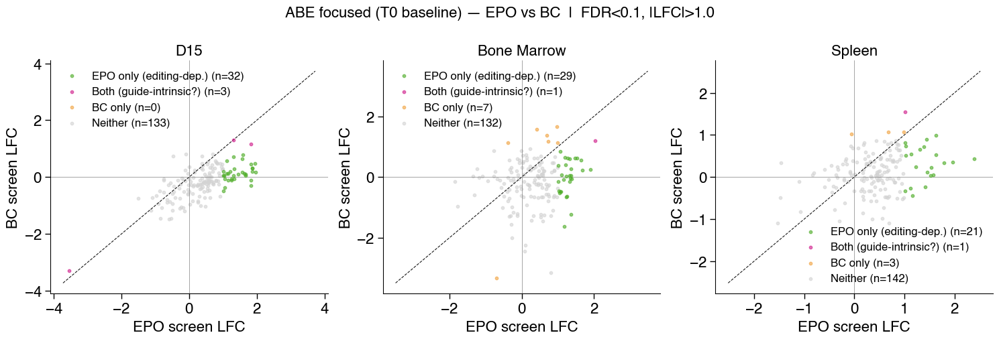

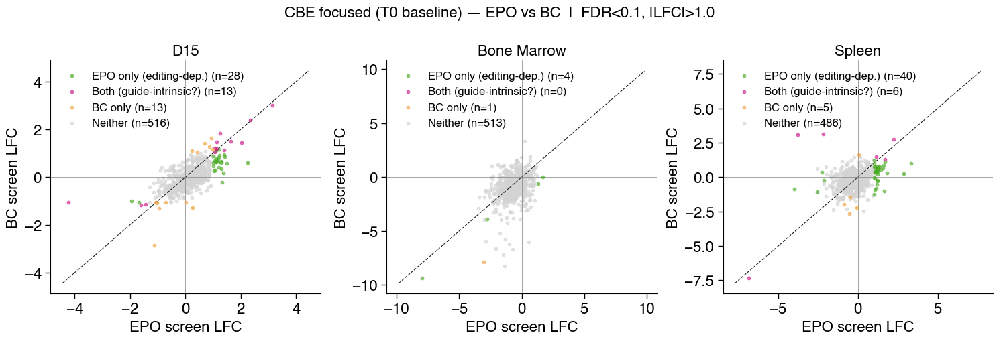

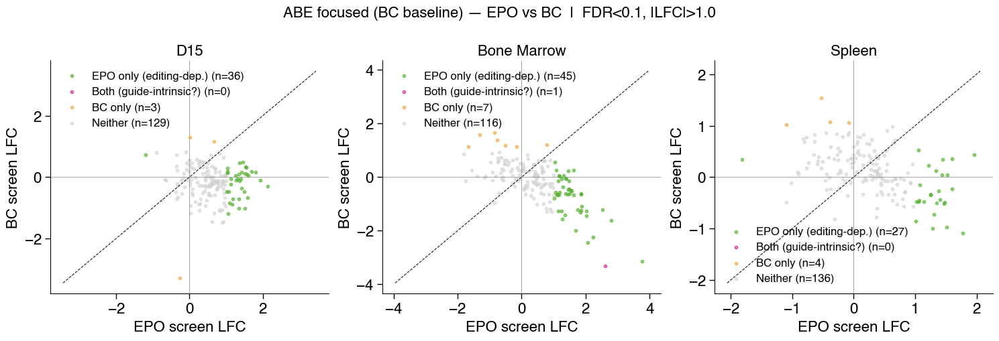

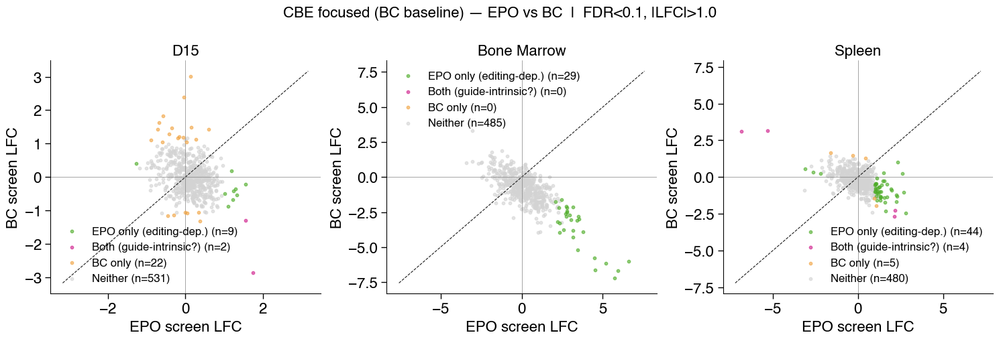

In [129]:
epo_vs_bc_scatter('ABE_EPO_T0', 'ABE_BC_T0', 'ABE focused (T0 baseline)', conds_focused)
epo_vs_bc_scatter('CBE_EPO_T0', 'CBE_BC_T0', 'CBE focused (T0 baseline)', conds_focused)
epo_vs_bc_scatter('ABE_EPO_BC', 'ABE_BC_T0', 'ABE focused (BC baseline)', conds_focused)
epo_vs_bc_scatter('CBE_EPO_BC', 'CBE_BC_T0', 'CBE focused (BC baseline)', conds_focused)
# ── Save figure ──────────────────────────────────────────────────────────
# panel = ''  # e.g. '2f'
# fig.savefig(f'figures/{panel}.pdf', bbox_inches='tight')


# 10. Quick hit tables

In [130]:
def hit_table(df, screen_name, conditions,
              effect='median', fdr_method='fishers', fdr_cutoff=0.1,
              lfc_cutoff=1.0, is_og=False, n_show=20):
    # Filters: sensor_reads_{cond} >= min_sensor, target_base_edit_perc_{cond} >= 20,
    #          Input_median >= 2, |LFC| > lfc_cutoff
    min_sensor  = 10 if is_og else 100
    edit_cutoff = 20

    targ = df[df['classification'] == 'targeting guide'].copy()
    input_ok = targ['Input_median'] >= 2 if 'Input_median' in targ.columns else pd.Series(True, index=targ.index)

    for cond in conditions:
        lfc_col   = f'LFC_{effect}_{cond}'
        fdr_col   = f'FDR_{cond}_{fdr_method}'
        reads_col = f'sensor_reads_{cond}'
        edit_col  = f'target_base_edit_perc_{cond}'
        if lfc_col not in targ.columns: continue

        if reads_col in targ.columns and edit_col in targ.columns:
            guide_ok = input_ok & (targ[reads_col] >= min_sensor) & (targ[edit_col] >= edit_cutoff)
        else:
            guide_ok = input_ok
        sub = targ[guide_ok]

        sig = sub[(sub[fdr_col] < fdr_cutoff) & (sub[lfc_col].abs() > lfc_cutoff)].sort_values(lfc_col, ascending=False)

        gene_col  = 'gene_name_m_corrected' if 'gene_name_m_corrected' in sig.columns else 'Gene'
        label_col = 'HGVSp_m' if 'HGVSp_m' in sig.columns else 'gRNA_id'
        cols = [gene_col, label_col, lfc_col, fdr_col, edit_col]
        cols = [c for c in cols if c in sig.columns]
        if 'Role in Cancer' in sig.columns: cols.append('Role in Cancer')

        print(f'\n=== {screen_name} | {cond} | {effect} | FDR={fdr_method} | n_sig={len(sig)} ===')
        print('--- TOP ENRICHED ---')
        print(sig.head(n_show)[cols].to_string(index=False))
        print('--- TOP DEPLETED ---')
        print(sig.tail(n_show)[cols].to_string(index=False))

# OG
hit_table(dfs['ABE_OG'], 'ABE_OG', conds_og, is_og=True)
hit_table(dfs['CBE_OG'], 'CBE_OG', conds_og, is_og=True)



=== ABE_OG | d15 | median | FDR=fishers | n_sig=113 ===
--- TOP ENRICHED ---
gene_name_m_corrected    HGVSp_m  LFC_median_d15  FDR_d15_fishers  target_base_edit_perc_d15 Role in Cancer
               Pik3r3       D11G        2.797752     8.779418e-09                  58.865248      Undefined
                 Daxx      N274S        2.765991     8.779418e-09                  94.473559   Oncogene/TSG
                  Syk      N451S        2.483826     8.779418e-09                  77.977920       Oncogene
                 Raf1      R391G        2.357751     8.779418e-09                  97.921478       Oncogene
                  Myc       T73A        2.267804     8.779418e-09                  92.617450       Oncogene
                  Ret      K809E        2.234323     8.779418e-09                  80.253165       Oncogene
                Erbb3      Q807R        2.206274     8.779418e-09                  98.257656       Oncogene
                Keap1       Y33H        2.198222     8.779

In [131]:
# OG screens
hit_table(dfs['ABE_OG'], 'ABE_OG', conds_og, is_og=True)
hit_table(dfs['CBE_OG'], 'CBE_OG', conds_og, is_og=True)

# Focused EPO screens
for screen, conds in [('ABE_EPO_T0', conds_focused), ('CBE_EPO_T0', conds_focused),
                       ('ABE_EPO_BC', conds_focused), ('CBE_EPO_BC', conds_focused),
]:
    if dfs.get(screen) is None: continue
    hit_table(dfs[screen], screen, conds, is_og=False)



=== ABE_OG | d15 | median | FDR=fishers | n_sig=113 ===
--- TOP ENRICHED ---
gene_name_m_corrected    HGVSp_m  LFC_median_d15  FDR_d15_fishers  target_base_edit_perc_d15 Role in Cancer
               Pik3r3       D11G        2.797752     8.779418e-09                  58.865248      Undefined
                 Daxx      N274S        2.765991     8.779418e-09                  94.473559   Oncogene/TSG
                  Syk      N451S        2.483826     8.779418e-09                  77.977920       Oncogene
                 Raf1      R391G        2.357751     8.779418e-09                  97.921478       Oncogene
                  Myc       T73A        2.267804     8.779418e-09                  92.617450       Oncogene
                  Ret      K809E        2.234323     8.779418e-09                  80.253165       Oncogene
                Erbb3      Q807R        2.206274     8.779418e-09                  98.257656       Oncogene
                Keap1       Y33H        2.198222     8.779

# 10. Gene-level summary

Aggregate guide-level hits to gene level.
For each gene: number of significant guides, best (most extreme) LFC, fraction of guides that are hits.
Useful for identifying genes with consistent multi-guide evidence.

In [132]:
def gene_summary(df, screen_name, conditions,
                 effect='median', fdr_method='fishers',
                 fdr_cutoff=0.1, lfc_cutoff=1.0, is_og=False, min_guides_hit=1):
    # Same sensor/edit/input filters as get_hits
    min_sensor  = 10 if is_og else 100
    edit_cutoff = 20

    targ     = df[df['classification'] == 'targeting guide'].copy()
    input_ok = targ['Input_median'] >= 2 if 'Input_median' in targ.columns else pd.Series(True, index=targ.index)
    gene_col = 'gene_name_m_corrected' if 'gene_name_m_corrected' in targ.columns else 'Gene'

    for cond in conditions:
        lfc_col   = f'LFC_{effect}_{cond}'
        fdr_col   = f'FDR_{cond}_{fdr_method}'
        reads_col = f'sensor_reads_{cond}'
        edit_col  = f'target_base_edit_perc_{cond}'
        if lfc_col not in targ.columns: continue

        if reads_col in targ.columns and edit_col in targ.columns:
            guide_ok = input_ok & (targ[reads_col] >= min_sensor) & (targ[edit_col] >= edit_cutoff)
        else:
            guide_ok = input_ok
        sub = targ[guide_ok].dropna(subset=[lfc_col, fdr_col])

        sub = sub.copy()
        sub['is_hit'] = (sub[fdr_col] < fdr_cutoff) & (sub[lfc_col].abs() > lfc_cutoff)

        g = sub.groupby(gene_col).agg(
            n_guides      = (lfc_col, 'count'),
            n_hits        = ('is_hit', 'sum'),
            best_lfc      = (lfc_col, lambda x: x.loc[x.abs().idxmax()]),
            mean_lfc      = (lfc_col, 'mean'),
            best_fdr      = (fdr_col, 'min'),
        ).reset_index()
        g['frac_hit'] = g['n_hits'] / g['n_guides']
        g = g[g['n_hits'] >= min_guides_hit].sort_values('best_lfc')

        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','men':'Meninges','d15':'D15'}.get(cond, cond)
        print(f'\n=== {screen_name} | {cond_label} | {effect} | FDR={fdr_method} | n_genes={len(g)} ===')
        print(g.to_string(index=False))

for screen, conds, og in [('ABE_OG', conds_og, True), ('CBE_OG', conds_og, True),
                            ('ABE_EPO_T0', conds_focused, False), ('CBE_EPO_T0', conds_focused, False),
                            ('ABE_EPO_BC', conds_focused, False), ('CBE_EPO_BC', conds_focused, False)]:
    gene_summary(dfs[screen], screen, conds, is_og=og)



=== ABE_OG | D15 | median | FDR=fishers | n_genes=60 ===
gene_name_m_corrected  n_guides  n_hits  best_lfc  mean_lfc     best_fdr  frac_hit
               Ctnnb1         7       3 -1.716539 -0.879877 1.463236e-07  0.428571
                 Ctcf         8       2 -1.628378 -0.047745 3.921814e-07  0.250000
                 Braf         6       1 -1.396787 -0.289894 5.333968e-04  0.166667
                  Vhl        10       2 -1.308271 -0.239205 9.505916e-04  0.200000
              Smarca4         5       2 -1.215105 -0.518939 1.526041e-03  0.400000
                Traf7         1       1 -1.194182 -1.194182 6.487001e-02  1.000000
                Stk11         3       1 -1.101984 -0.433454 2.269960e-03  0.333333
               Setbp1         3       1  1.017489  0.503760 6.613976e-05  0.333333
                 Fat1         2       1  1.018523  0.380561 3.072506e-05  0.500000
                 Phf6         2       1  1.023896  0.314073 4.444124e-05  0.500000
                 Irs1        

# 11. NT control FDR calibration

Check whether the FDR is well-calibrated by looking at the distribution of p-values for non-targeting controls.
Under the null, p-values should be uniform. A spike near 0 indicates inflation.

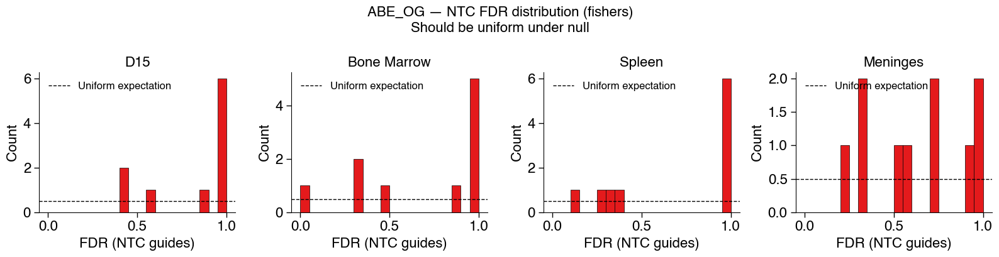

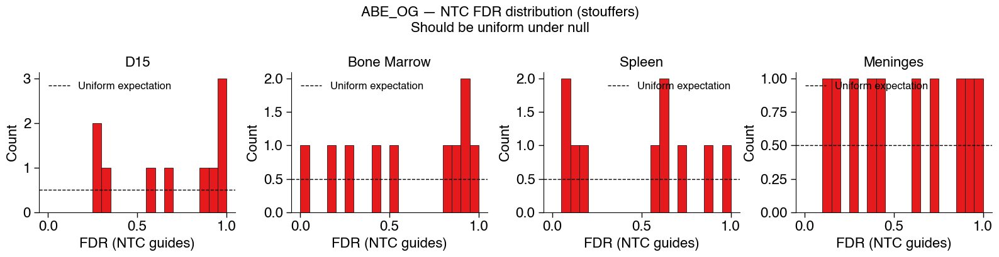

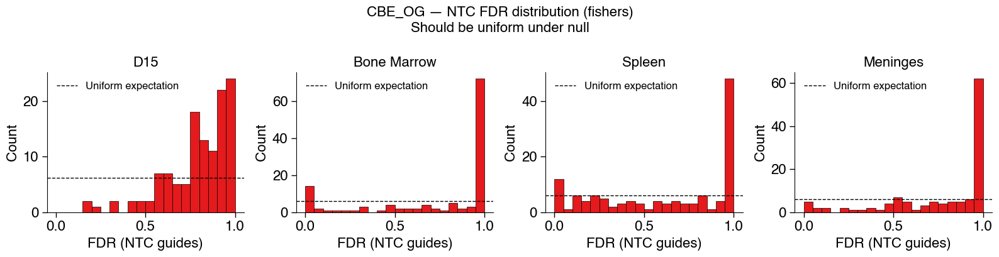

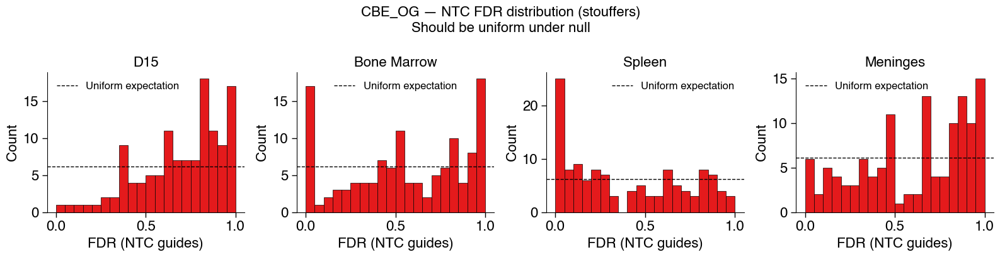

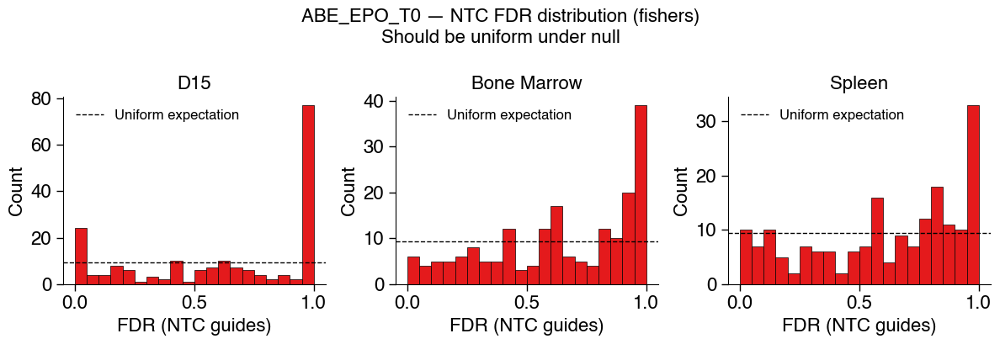

...

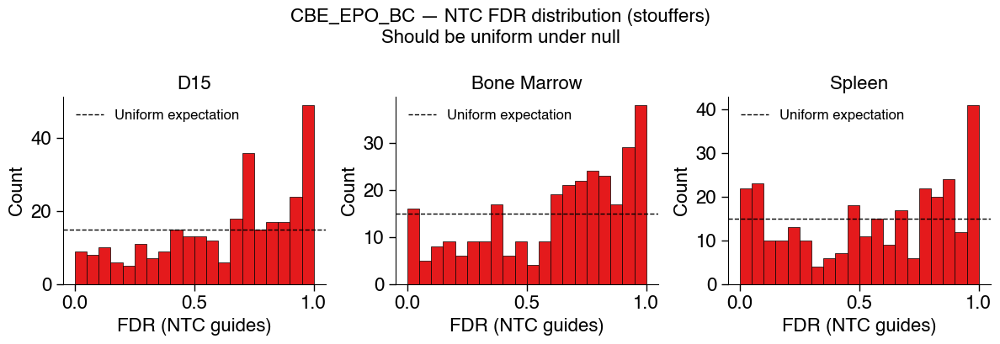

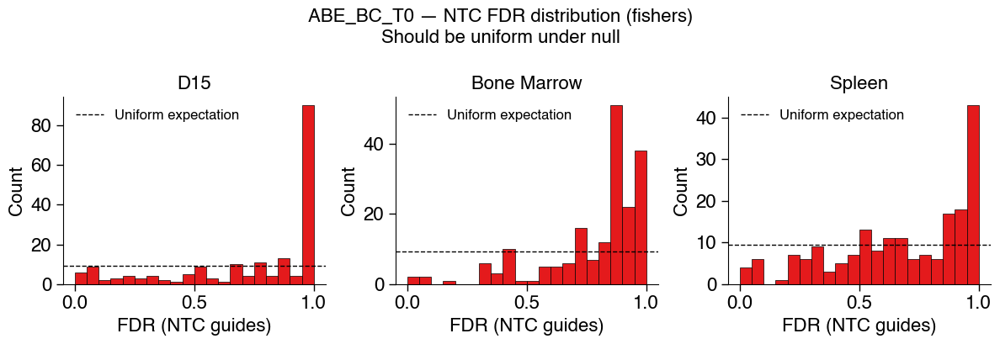

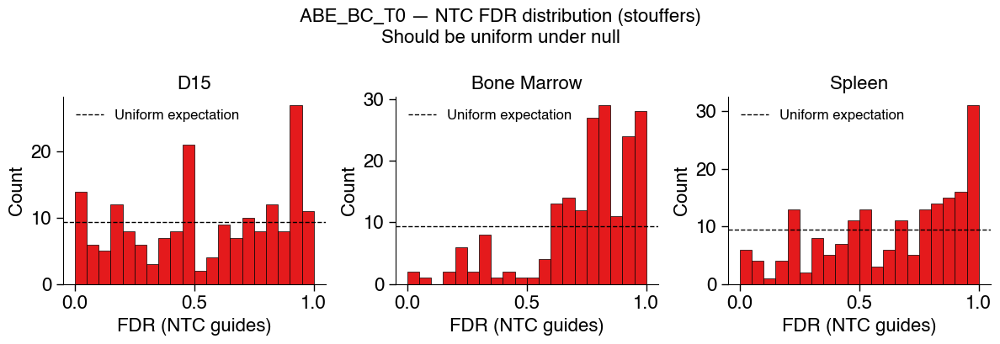

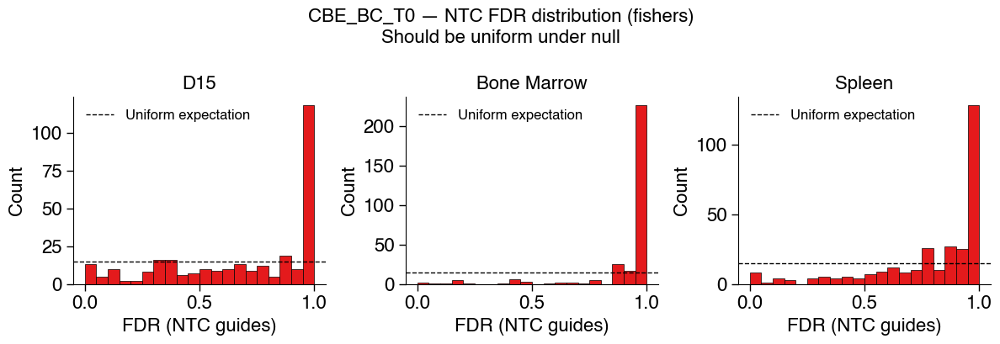

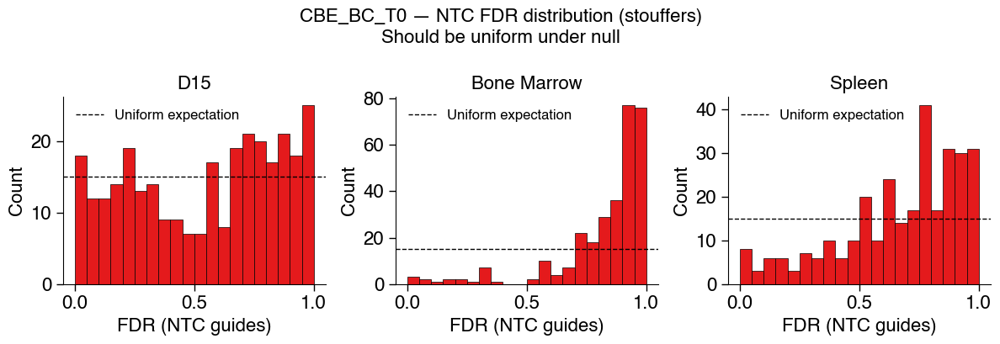

In [133]:
def nt_calibration(df, screen_name, conditions, fdr_method='fishers'):
    ntc = df[df['classification'] == 'non-targeting control'].copy()
    if len(ntc) == 0:
        print(f'{screen_name}: no NTC guides'); return

    n = len(conditions)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1: axes = [axes]

    for k, cond in enumerate(conditions):
        fdr_col = f'FDR_{cond}_{fdr_method}'
        if fdr_col not in ntc.columns: continue
        pvals = ntc[fdr_col].dropna()
        ax = axes[k]
        ax.hist(pvals, bins=20, range=(0,1), color='#e41a1c', edgecolor='black', linewidth=0.5)
        ax.axhline(len(pvals)/20, color='black', linestyle='--', linewidth=1, label='Uniform expectation')
        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','men':'Meninges','d15':'D15'}.get(cond, cond)
        ax.set_title(cond_label, fontsize=16)
        ax.set_xlabel('FDR (NTC guides)', fontsize=16)
        ax.set_ylabel('Count', fontsize=16)
        ax.legend(frameon=False, fontsize=12)
        ax.spines[['top','right']].set_visible(False)
        ax.tick_params(labelsize=16, direction='out', length=6, width=1)

    fig.suptitle(f'{screen_name} — NTC FDR distribution ({fdr_method})\nShould be uniform under null', fontsize=16, y=1.01)
    fig.tight_layout(); plt.show()

for screen in ['ABE_OG','CBE_OG','ABE_EPO_T0','CBE_EPO_T0','ABE_EPO_BC','CBE_EPO_BC','ABE_BC_T0','CBE_BC_T0']:
    for fdr_m in ['fishers','stouffers']:
        nt_calibration(dfs[screen], screen, conds_og if 'OG' in screen else conds_focused, fdr_method=fdr_m)


# 12. ABE vs CBE hit overlap

For OG and focused screens: which genes/guides are hits in both editors?
Shared hits across editors suggest the fitness effect is mutation-dependent (not editor-dependent).

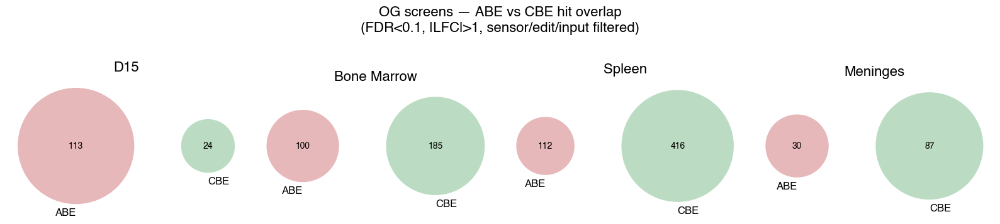

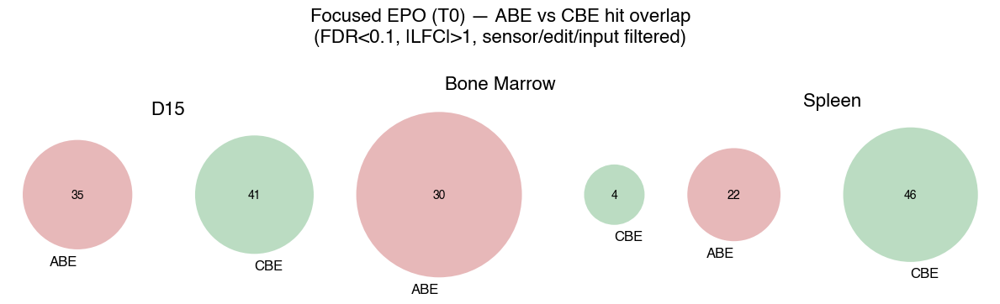

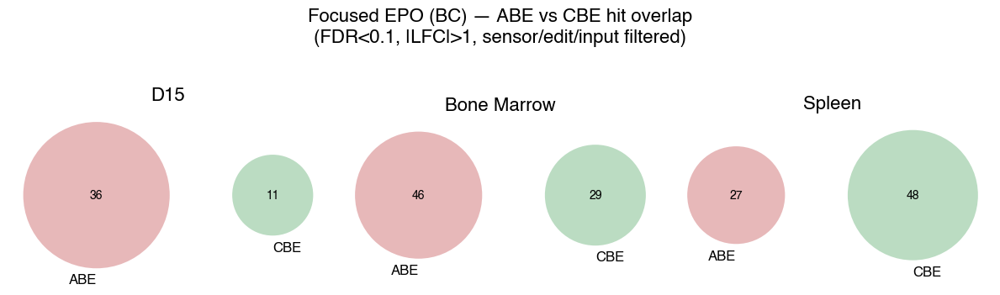

In [134]:
from matplotlib_venn import venn2

def abe_cbe_overlap(abe_key, cbe_key, conditions, label, is_og=False):
    n = len(conditions)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1: axes = [axes]

    for k, cond in enumerate(conditions):
        abe_hits = get_hits(dfs[abe_key], cond, is_og=is_og)
        cbe_hits = get_hits(dfs[cbe_key], cond, is_og=is_og)
        venn2([abe_hits, cbe_hits], set_labels=('ABE','CBE'), ax=axes[k])
        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','men':'Meninges','d15':'D15'}.get(cond, cond)
        axes[k].set_title(cond_label, fontsize=16)
        shared = abe_hits & cbe_hits
        if shared:
            # Map gRNA_id → gene name for shared hits
            gene_col = 'gene_name_m_corrected' if 'gene_name_m_corrected' in dfs[abe_key].columns else 'Gene'
            shared_genes = dfs[abe_key][dfs[abe_key]['gRNA_id'].isin(shared)][gene_col].unique()
            print(f'{label} | {cond_label} | shared hits: {sorted(shared_genes)}')

    fig.suptitle(f'{label} — ABE vs CBE hit overlap\n(FDR<0.1, |LFC|>1, sensor/edit/input filtered)', fontsize=16)
    fig.tight_layout(); plt.show()

abe_cbe_overlap('ABE_OG',     'CBE_OG',     conds_og,      'OG screens',      is_og=True)
abe_cbe_overlap('ABE_EPO_T0', 'CBE_EPO_T0', conds_focused, 'Focused EPO (T0)', is_og=False)
abe_cbe_overlap('ABE_EPO_BC', 'CBE_EPO_BC', conds_focused, 'Focused EPO (BC)', is_og=False)


# 13. CBE NGG PAM filter

CBE editing efficiency is highest with NGG PAM guides.
Analysis_4 and Analysis_7 both restrict CBE hit calling to NGG PAM guides.
Here we build the NGG PAM guide lists for use in downstream analyses.

In [135]:
# Build NGG PAM guide sets for CBE
LIB_FOCUSED = pd.read_csv(BASE + 'NGS-scripts/STEP3_generate_config_file/FINAL_focused_library.csv')
LIB_OG      = pd.read_csv(BASE + 'MBESv2_CORRECTED.csv')

_ngg_pams = ['AGG', 'TGG', 'CGG', 'GGG']

# Focused CBE NGG guides
_cbe_focused_ngg = set(
    LIB_FOCUSED[(LIB_FOCUSED['Editor'] == 'CBE') &
                (LIB_FOCUSED['PAM'].fillna('').isin(_ngg_pams))]['gRNA_id']
)

# OG CBE NGG guides (PAM_NGN column)
_cbe_og_ngg = set(
    LIB_OG[(LIB_OG['Editor'] == 'CBE') &
            (LIB_OG['PAM_NGN'].fillna('').isin(_ngg_pams))]['gRNA_id']
)

print(f'Focused CBE total: {len(LIB_FOCUSED[LIB_FOCUSED["Editor"]=="CBE"])}, NGG: {len(_cbe_focused_ngg)}')
print(f'OG CBE total:      {len(LIB_OG[LIB_OG["Editor"]=="CBE"])}, NGG: {len(_cbe_og_ngg)}')


Focused CBE total: 1257, NGG: 0
OG CBE total:      13242, NGG: 3532


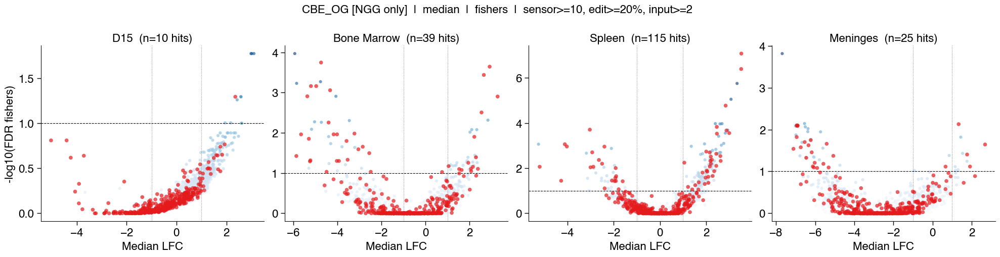

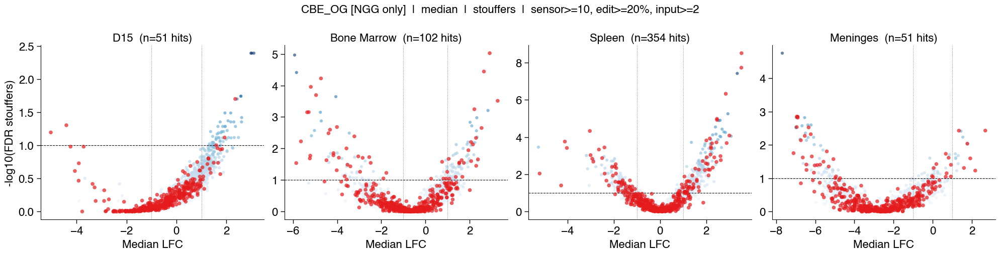

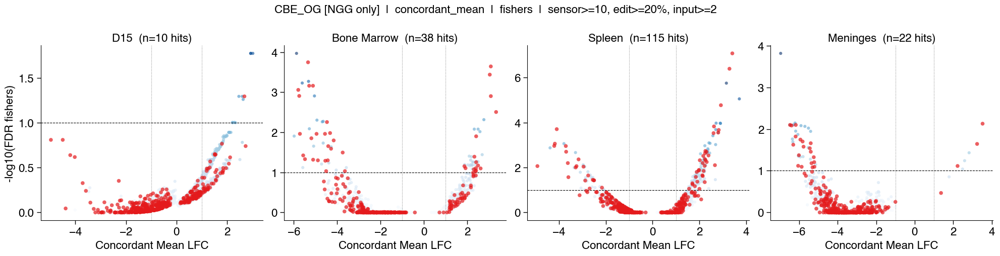

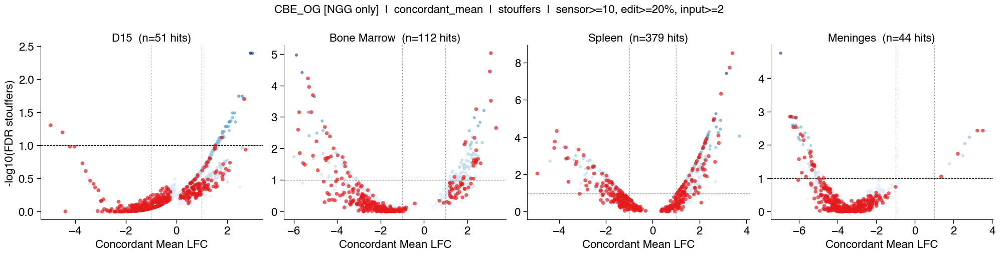

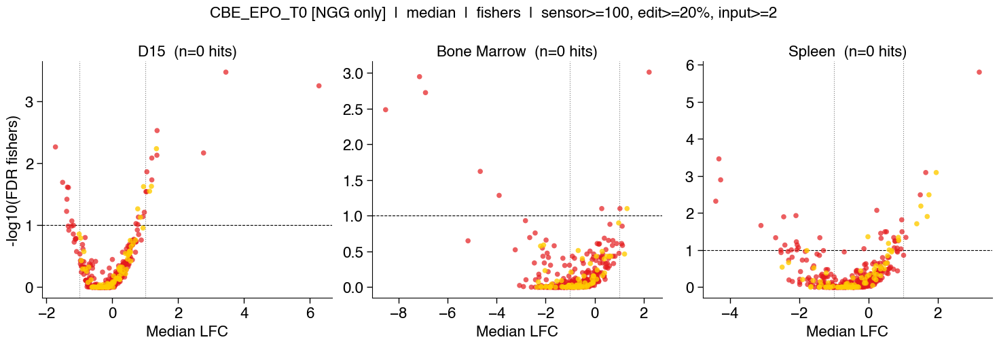

...

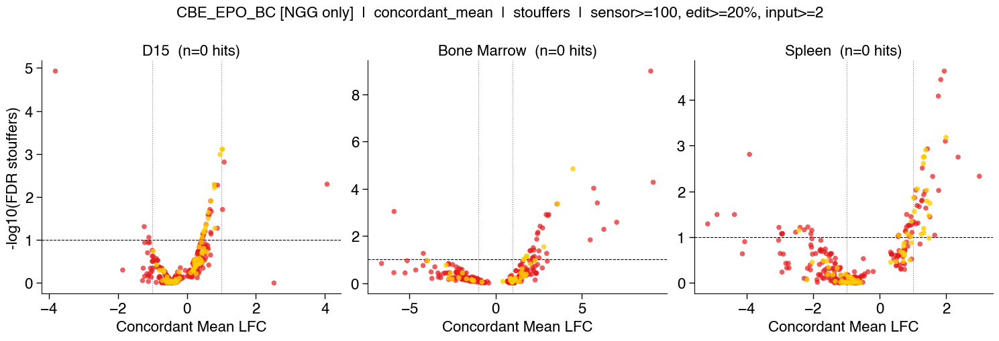

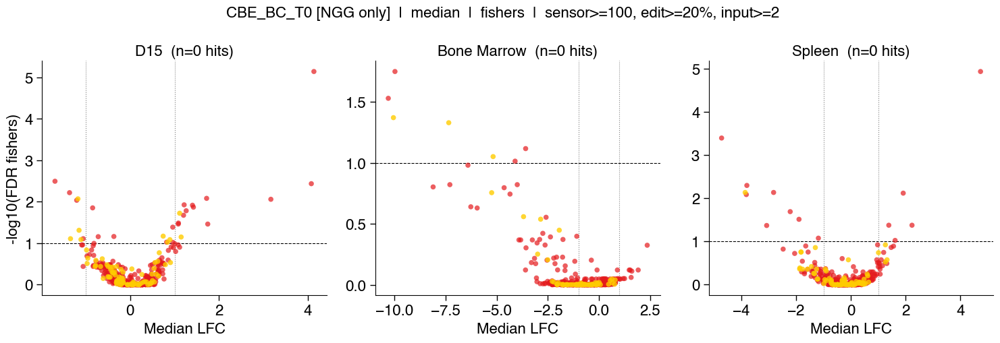

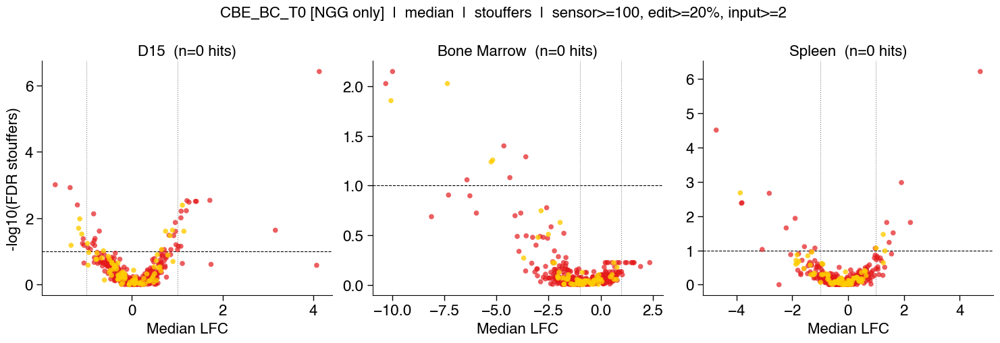

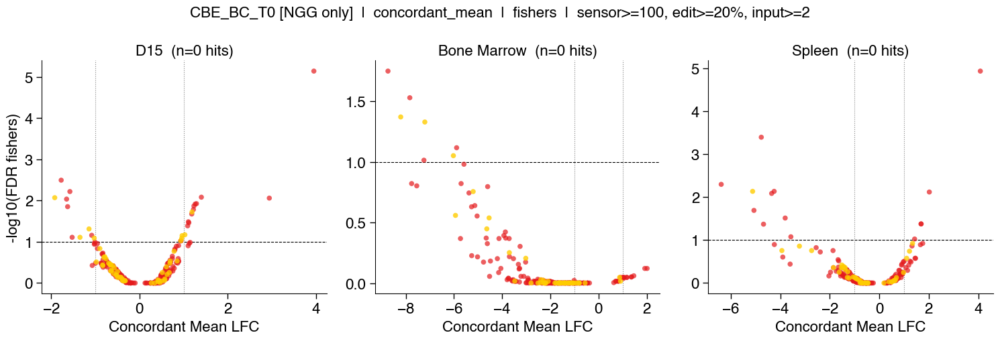

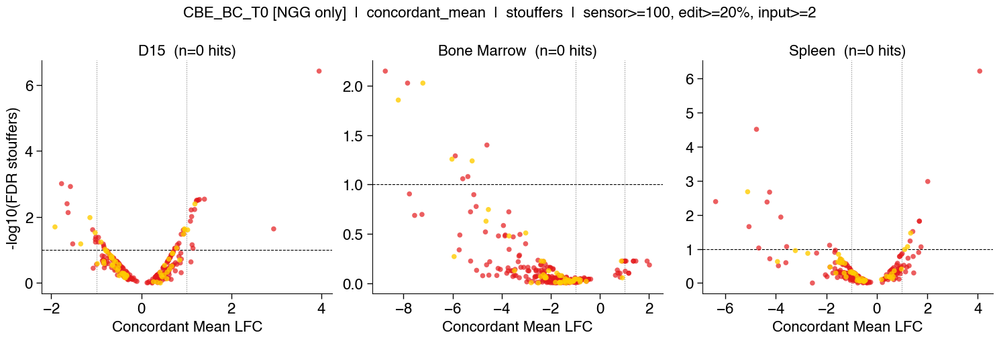

In [136]:
# Volcano plots - CBE with NGG PAM filter
for screen, ngg in [('CBE_OG', _cbe_og_ngg), ('CBE_EPO_T0', _cbe_focused_ngg),
                     ('CBE_EPO_BC', _cbe_focused_ngg), ('CBE_BC_T0', _cbe_focused_ngg)]:
    conds = conds_og if 'OG' in screen else conds_focused
    og    = 'OG' in screen
    df_ngg = dfs[screen].copy()
    # Keep targeting guides only if they are NGG PAM; keep all controls
    mask = (df_ngg['classification'] == 'targeting guide') & (~df_ngg['gRNA_id'].isin(ngg))
    df_ngg = df_ngg[~mask]
    for effect in ['median', 'concordant_mean']:
        for fdr_m in ['fishers', 'stouffers']:
            volcano_plot(df_ngg, screen + ' [NGG only]', conds,
                         effect=effect, fdr_method=fdr_m, is_og=og)


# 14. Focused vs OG screen LFC correlation

For guides shared between the focused and OG libraries, compare z-scored LFC per tissue.
High Spearman correlation validates that the focused screen recapitulates OG screen results.
ABE and CBE shown separately (CBE: NGG PAM only).

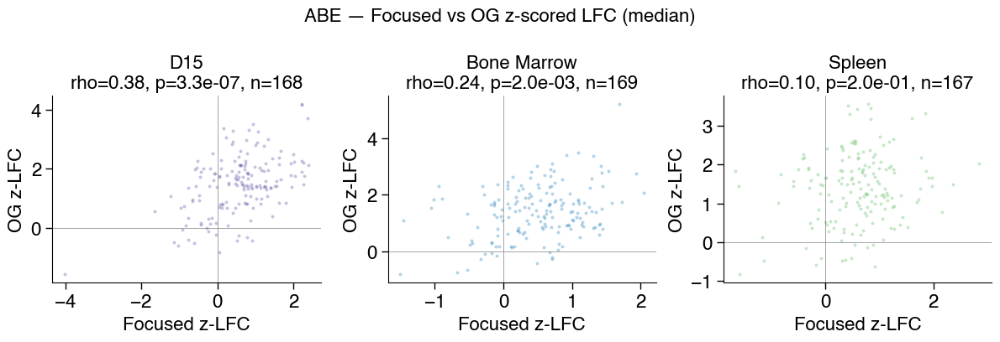

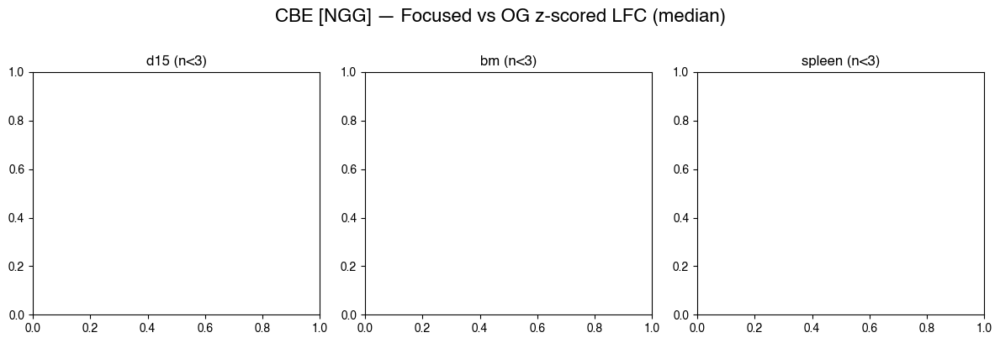

In [137]:
def focused_vs_og_correlation(editor, focused_key, og_key,
                               shared_conds, ngg_set=None, effect='median',
                               min_sensor=100, edit_cutoff=20):
    # z_score_{effect}_{cond} already precomputed in dfs
    foc_df = dfs[focused_key]
    og_df  = dfs[og_key]

    input_ok = foc_df['Input_median'] >= 2 if 'Input_median' in foc_df.columns else pd.Series(True, index=foc_df.index)
    targ_foc = foc_df[foc_df['classification'] == 'targeting guide'].copy()
    targ_og  = og_df[og_df['classification']  == 'targeting guide'].copy()

    if ngg_set is not None:
        targ_foc = targ_foc[targ_foc['gRNA_id'].isin(ngg_set)]
        targ_og  = targ_og[targ_og['gRNA_id'].isin(ngg_set)]

    _tc = {'bm': '#4393c3', 'spleen': '#74c476', 'd15': '#756bb1', 'men': '#d6604d'}
    n = len(shared_conds)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4), squeeze=False)

    for k, cond in enumerate(shared_conds):
        z_col = f'z_score_{effect}_{cond}'
        rc = f'sensor_reads_{cond}'; ec = f'target_base_edit_perc_{cond}'

        ok = input_ok.reindex(targ_foc.index, fill_value=False)
        if rc in targ_foc.columns and ec in targ_foc.columns:
            ok = ok & (targ_foc[rc] >= min_sensor) & (targ_foc[ec] >= edit_cutoff)
        sub_foc = targ_foc[ok]

        if z_col not in sub_foc.columns or z_col not in targ_og.columns:
            continue

        merged = pd.merge(
            sub_foc[['gRNA_id', z_col]].rename(columns={z_col: 'z_foc'}),
            targ_og[['gRNA_id', z_col]].rename(columns={z_col: 'z_og'}),
            on='gRNA_id'
        ).dropna()

        ax = axes[0][k]
        if len(merged) < 3:
            ax.set_title(f'{cond} (n<3)'); continue

        r, p = scipy.stats.spearmanr(merged['z_foc'], merged['z_og'])
        ax.scatter(merged['z_foc'], merged['z_og'],
                   c=_tc.get(cond, '#888888'), s=8, alpha=0.4, linewidths=0)
        ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
        cond_label = {'bm': 'Bone Marrow', 'spleen': 'Spleen', 'men': 'Meninges', 'd15': 'D15'}.get(cond, cond)
        ax.set_title(f'{cond_label}\nrho={r:.2f}, p={p:.1e}, n={len(merged)}', fontsize=16)
        ax.set_xlabel('Focused z-LFC', fontsize=16); ax.set_ylabel('OG z-LFC', fontsize=16)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)

    ngg_label = ' [NGG]' if ngg_set is not None else ''
    fig.suptitle(f'{editor}{ngg_label} — Focused vs OG z-scored LFC ({effect})', fontsize=16, y=1.01)
    fig.tight_layout(); plt.show()

_shared_conds = ['d15', 'bm', 'spleen']  # men not in focused screens

focused_vs_og_correlation('ABE', 'ABE_EPO_T0', 'ABE_OG', _shared_conds)
focused_vs_og_correlation('CBE', 'CBE_EPO_T0', 'CBE_OG', _shared_conds, ngg_set=_cbe_focused_ngg)


# 15. Control guide LFC cross-screen correlation

NTC and safe-targeting guides should behave consistently across screens.
High Pearson r between z-scored control LFC of EPO vs BC screens confirms
that screen-to-screen variation is not inflating hits.

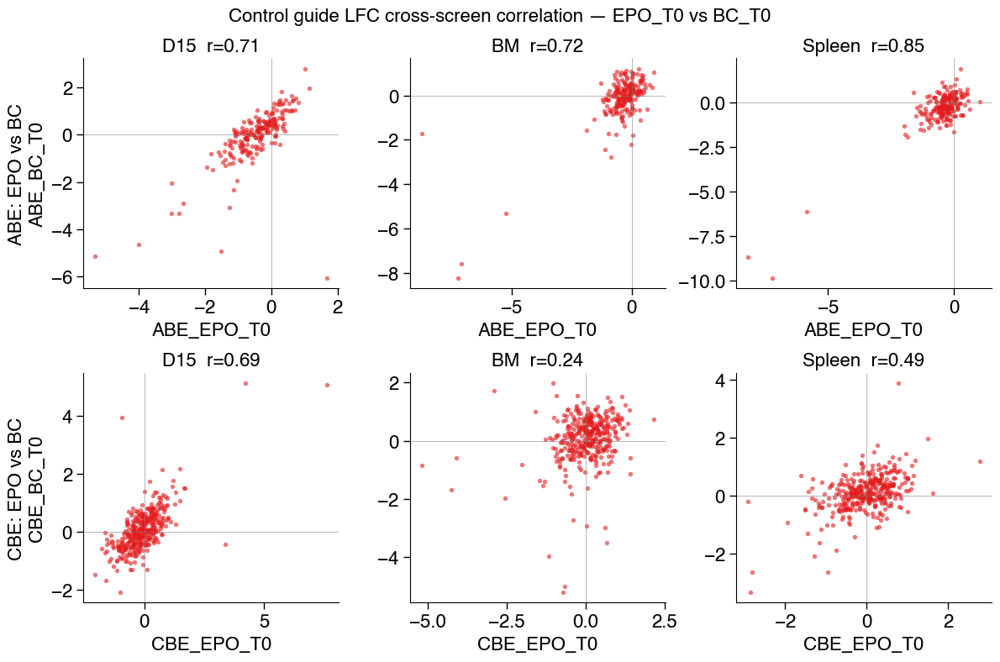

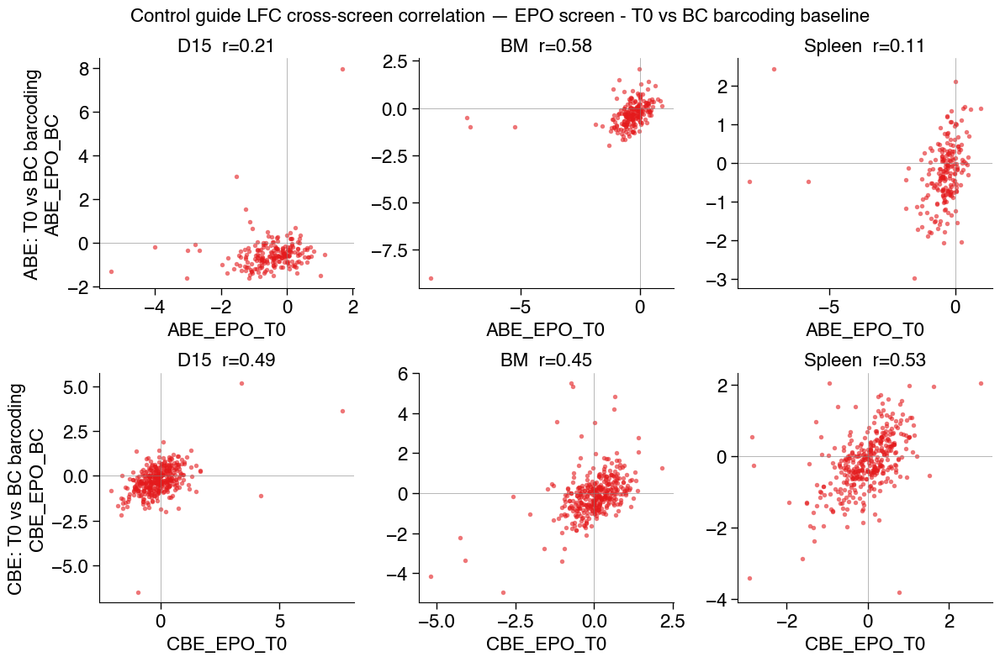

In [138]:
def control_lfc_correlation(screen_pairs, conditions, effect='median', title=''):
    null_classes = ['non-targeting control', 'safe-targeting control']
    n_pairs = len(screen_pairs)
    n_conds = len(conditions)
    fig, axes = plt.subplots(n_pairs, n_conds, figsize=(4*n_conds, 4*n_pairs), squeeze=False)

    for pi, (k1, k2, pair_label) in enumerate(screen_pairs):
        ctrl1 = dfs[k1][dfs[k1]['classification'].isin(null_classes)]
        ctrl2 = dfs[k2][dfs[k2]['classification'].isin(null_classes)]

        for ci, cond in enumerate(conditions):
            zc = f'z_score_{effect}_{cond}'
            if zc not in ctrl1.columns or zc not in ctrl2.columns:
                continue
            merged = pd.merge(
                ctrl1[['gRNA_id', zc]].rename(columns={zc: 'z1'}),
                ctrl2[['gRNA_id', zc]].rename(columns={zc: 'z2'}),
                on='gRNA_id'
            ).dropna()

            ax = axes[pi][ci]
            if len(merged) < 3:
                ax.set_title('n<3'); continue

            r, p = scipy.stats.pearsonr(merged['z1'], merged['z2'])
            ax.scatter(merged['z1'], merged['z2'], s=15, alpha=0.6,
                       color='#e41a1c', linewidths=0)
            ax.axhline(0, color='grey', lw=0.4); ax.axvline(0, color='grey', lw=0.4)
            cond_label = {'bm': 'BM', 'spleen': 'Spleen', 'men': 'Men', 'd15': 'D15'}.get(cond, cond)
            ax.set_title(f'{cond_label}  r={r:.2f}', fontsize=16)
            if ci == 0:
                ax.set_ylabel(f'{pair_label}\n{k2}', fontsize=16)
            ax.set_xlabel(k1, fontsize=16)
            ax.spines[['top', 'right']].set_visible(False)
            ax.tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)

    fig.suptitle(f'Control guide LFC cross-screen correlation — {title}', fontsize=16)
    fig.tight_layout(); plt.show()

control_lfc_correlation(
    [('ABE_EPO_T0', 'ABE_BC_T0',  'ABE: EPO vs BC'),
     ('CBE_EPO_T0', 'CBE_BC_T0',  'CBE: EPO vs BC')],
    conds_focused, title='EPO_T0 vs BC_T0'
)
control_lfc_correlation(
    [('ABE_EPO_T0', 'ABE_EPO_BC', 'ABE: T0 vs BC barcoding'),
     ('CBE_EPO_T0', 'CBE_EPO_BC', 'CBE: T0 vs BC barcoding')],
    conds_focused, title='EPO screen - T0 vs BC barcoding baseline'
)

